# Does buying right after a Binance burst, while the book has not moved, still make money on weeks it was not tuned on?

## S0 · Summary

**The thesis.** After a 3-sigma Binance burst the move persists, and a Polymarket 15-minute Up/Down book that has not re-priced it leaves the near token (the
side the burst points to) under its driftless fair value. Test E reads that mechanism directly: rule A (a burst, and a near ask more than 5 cents under fair value)
plus a near ask equal to its ask 3 seconds earlier. This notebook asks whether E holds up when its settings are chosen week by week instead of fixed.

**What is tuned.** The stale window, what "has not moved for n seconds" means, the discount to fair value (3, 5 or 8 cents) and the fill limit: (a) the near ask
equals its ask n seconds ago (E as built; an ask that moved and came back counts), (b) it is unchanged at every second of the last n, (c) it and its size at the
touch are unchanged; the limit is the ask seen at the decision second (E as built) or our edge price, fair value less the discount. Each week is traded with the
setting chosen on the weeks before it, taken at the centre of a plateau along the window rather than at the best single cell.

**The engine.** The gate reads the book 100 ms after the Binance print and the order meets the ladder 250 ms after it [U]. A decision is refused when every book of
its 15-minute slot is silent, because a frozen feed passes "has not moved" by construction. Fair value starts from the venue's published price to beat, with the
Binance stream converted into its terms by the previous day's median basis per coin; a window with no published price to beat is left out.

In [1]:
from IPython.display import Markdown, display
S0_HANDLE = display(Markdown("_The summary card is drawn here when the run finishes._"), display_id=True)

**Does buying right after a Binance burst, while the book has not moved, still make money on weeks it was not tuned on?** · **NO SIZE**

**Research question** Does buying after a burst, while the book has not moved, still make money on weeks it was not tuned on?

NO SIZE, class B. E tuned out of sample: 174 entries net +509 USD (+2.93 each, 95% +0.26 to +5.98); without the best 5% +0.25.

**Implementation**

| | |
|:--|:--|
| Trade | Buy the near token after a burst, book not moved |
| Venue | Polymarket 15m crypto Up/Down; Binance is input |
| Rule | a12\|th0.08\|ask |
| Size | USD 20 a trade, USD 1,000 book, 1x |
| Costs | taker fee 0.07 x p(1-p); gate +100, fill +250 ms |
| Window | 09-02 to 10-09, 912h, 1 regime |

**The numbers that matter**

| At | Metric | Value | Bar | |
|:--|:--|--:|:--|:--|
| test | Net per entry | +2.93 USD | 95% +0.26 to +5.98 | PASS |
| test | Without best 5% | +0.25 USD | above 0 | PASS |
| test | Win rate | 71.3% | needed 59.0% | INFO |
| test | Deflated Sharpe | 0.00 | at least 0.90 | FAIL |

**Money**

| Metric | Value | Bar | |
|:--|--:|:--|:--|
| Net per entry | +2.93 USD | above 0 | PASS |
| Before costs, per entry | +3.29 USD |  | INFO |
| Fee, per entry | 0.37 USD |  | INFO |
| E as built, same days | +0.77 USD |  | INFO |

**Is it real**

| Metric | Value | Bar | |
|:--|--:|:--|:--|
| Tuned beats E | no | yes | FAIL |
| Same window | 4 of 5 | 4 of 5 | PASS |
| Weeks agree | 2 of 5 | 4 of 5 | FAIL |
| Out-of-sample blocks | not both | both | FAIL |
| Plateau | holds | holds | PASS |
| Random burst p | 0.0190 | below 0.10 | PASS |

**Delay and cost**

| Metric | Value | Bar | |
|:--|--:|:--|:--|
| 1,250 ms, per entry | +0.89 | above 0 | PASS |
| Fee x2, per entry | +2.56 | above 0 | PASS |

**Risk, USD**

| Metric | Value | Bar | |
|:--|--:|:--|:--|
| Deepest drawdown | -157 | limit -150 | FAIL |
| Worst day | -51 |  | INFO |
| Steadiness r2 | 0.43 | low end 0.80 | FAIL |

**Checks**

| Metric | Value | Bar | |
|:--|--:|:--|:--|
| Windows with a book | 94% | 90% bar | PASS |
| Live replay | agrees | agrees | PASS |
| Cells tried | 162 |  | INFO |
| Checks held | 50 of 50 | all | INFO |

**Size**

| Size | Net, USD | Per entry | Verdict |
|:--|--:|--:|:--|
| 1x info only | +509 | +2.93 | FAIL |

162 cells, each week chosen on the weeks before it.  
E was first read on all 38 days; only the walk-forward record is out of sample for a choice.  
912h, 50/50 checks; gate 100 ms and fill 250 ms after the print; slot-wide silent feeds refused.


## S1 · Setup

### S1.1 · Parameters

In [2]:
# ---- the study's parameters; the grid names its own levels here and in tf15_stale.TUNE_LEVELS (asserted equal, registered before any cell is scored) ----
STUDY_ID = "2026-10-11-predmkts-binance-burst-15m-updown-stale-book"
RUN_ID = "um-023"
DESK = "lab/predmkts"
DAYS = ['2026-09-02', '2026-09-03', '2026-09-04', '2026-09-05', '2026-09-06', '2026-09-07', '2026-09-08', '2026-09-09', '2026-09-10', '2026-09-11', '2026-09-12', '2026-09-13', '2026-09-14', '2026-09-15', '2026-09-16', '2026-09-17', '2026-09-18', '2026-09-19', '2026-09-20', '2026-09-21', '2026-09-22', '2026-09-23', '2026-09-24', '2026-09-25', '2026-09-26', '2026-09-27', '2026-09-28', '2026-09-29', '2026-09-30', '2026-10-01', '2026-10-02', '2026-10-03', '2026-10-04', '2026-10-05', '2026-10-06', '2026-10-07', '2026-10-08', '2026-10-09']
WEEK = 7                                                 # walk-forward weeks by day index; also the tf15_oos fold length
TUNE_LEVELS = dict(kind=("a", "b", "c"), n=(1, 2, 3, 4, 5, 6, 8, 10, 12), theta=(0.03, 0.05, 0.08), limit=("ask", "edge"))   # theta: the discount to fair value, USD a share (3, 5, 8 c)
TUNE_FIXED = dict(z_min=3.0, L=10, t_min=300, band="any")      # E's own levels: |z| 3 over 10 s, at least 300 s left, any ask band
N_REGISTERED = 162                                            # 9 windows x 3 definitions x 3 discounts to fair value (3, 5, 8 c) x 2 limits
E_CELL = dict(kind="a", n=3, theta=0.05, limit="ask")          # test E of um-021 as built
TUNE_N_MIN = 60                                           # a cell is chosen only with at least this many entries on the choosing weeks
STABLE_MIN = 4                                             # G-stable: the chosen window the same in at least this many folds
CLIP_USD, BOOK_USD = 20.0, 1000.0
VENUE_HOLD_MS, OWN_MS = 150, 100                         # the venue's taker hold [1]; our own tick-to-trade, ASSUMED until measured live [U]
LAT_MS = VENUE_HOLD_MS + OWN_MS                          # the order meets the ladder this long after the Binance print
DECIDE_MS = OWN_MS                                       # the gate reads the book this long after the print: the soonest we can know of it [U]
REF = "ptbb"                                             # the fair value's reference: the price to beat, the Binance stream converted by the previous day's median basis per coin
FEED = True                                              # the feed mask: no decision when every book of the 15-minute slot is 2 s old or older
EXTRA_S = (1, 2, 3, 5)                                   # whole seconds added to the 250 ms table: 1,250 to 5,250 ms
FEE_MULTS = (0.0, 0.5, 1.0, 1.5, 2.0, 3.0)
SLIPS = (0.0, 0.01, 0.02)                                # the limit raised over the ask seen, USD a share
N_IS, N_OOS = 14, 14                                  # tf15_oos blocks by day index
N_DRAWS, P_GATE = 1000, 0.10
STOP_DAY_USD = 60.0                                      # PRE-REGISTERED [U]: the paper run stops for the day after a day's loss of three clips
DD_LIMIT_USD = 150.0                                     # PRE-REGISTERED [U]: the drawdown limit, 15% of the book
R2_MIN = 0.80                                            # PRE-REGISTERED [U]: the steadiness gate on the daily equity line
DSR_MIN = 0.90

In [3]:
import datetime as dt, time, math
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from IPython.display import HTML, Markdown, display
from fundplat.quant.core import figstyle, report as REPORT, summary_card
import tf15_bt as B, tf15_cands as C, tf15_trade_figs as TF, lift_figs as LF, tf15_oos as O, tf15_oos_figs as OF, tf15_stale as ST, tf15_runner as RUNNER
get_ipython().run_line_magic("config", "InlineBackend.print_figure_kwargs = {'bbox_inches': None}")
LF.setup()
plt.rcParams["figure.dpi"] = 72
assert TUNE_LEVELS == ST.TUNE_LEVELS and TUNE_FIXED == ST.TUNE_FIXED, "the parameters are not the module's grid"
t0 = time.time()
TAB = B.Tab(DAYS, fill_ms=LAT_MS, decide_ms=DECIDE_MS, ref=REF)
ALL_IDX = np.arange(len(DAYS))
CAND = C.BuyNearStale(feed=FEED)
CAND_RAW = C.BuyNearStale(feed=False)                      # the same rule without the feed mask: only for the live replay, which has none
CFG_E = ST.tune_cell(**E_CELL)
CFG_A = dict(CFG_E, n=0, name="A")
E_ALL = B.concat(CAND.run(TAB, CFG_E, {}))
A_ALL = B.concat(CAND.run(TAB, CFG_A, {}))
TESTS_U21, MASKS_U21 = C.near_tests(TAB, feed=FEED)       # um-021's own code: E and A here must be its tests E and A, on the same table and feed mask
_same = lambda a_, b_: len(a_["net"]) == len(b_["net"]) and np.array_equal(a_["w"], b_["w"]) and np.array_equal(a_["k"], b_["k"]) and np.allclose(a_["net"], b_["net"])
assert _same(E_ALL, TESTS_U21["E"]) and _same(A_ALL, TESTS_U21["A"]), "the grid's E or A cell is not um-021's test"
S_E, S_A = ST.stats5(E_ALL), ST.stats(A_ALL)
HALF = len(DAYS) // 2
FIGURES = []
WIN = f"{DAYS[0][5:]} to {DAYS[-1][5:]} · {24 * len(DAYS):,}h · {len(DAYS)} days · one regime · gate {DECIDE_MS} ms, fill {LAT_MS} ms after the print · feed mask on"
ASSET = list(TF.COINS)
N_AXIS = figstyle.NEUTRAL["axis"]
sgn = lambda v_, d_=2: "n/a" if v_ is None or not np.isfinite(v_) else f"{v_:+,.{d_}f}"
pct = lambda v_, d_=1: "n/a" if v_ is None or not np.isfinite(v_) else f"{v_ * 100:.{d_}f}%"
FEED_LIVE = C.feed_live(TAB)                               # the feed mask the rule applies: False where every book of the slot is silent

def row(label, s):
    if not s.get("n"):
        return dict(label=label, n=0)
    return dict(label=label, n=s["n"], win_pct=s["win"] * 100, win_needed_pct=s["win_needed"] * 100, per_entry=s["per"], lo=s["per_lo"], hi=s["per_hi"],
                per_ex_best5=s["per_ex_top5"], reward_to_risk=s["rr"], profit_factor=s["pf"], net=s["net"])

def trades_df(e, idx):
    return pd.DataFrame(dict(day=[DAYS[i] for i in e["day"][idx]], coin=[ASSET[i] for i in e["asset"][idx]], near=np.where(e["side"][idx] > 0, "Up", "Down"),
                             second=(B.K0 + e["k"][idx]).astype(int), seconds_left=e["T"][idx].astype(int), price_paid=e["vwap"][idx], shares=e["shares"][idx],
                             cost=e["cost"][idx], fee=e["fee"][idx], won=e["won"][idx], net=e["net"][idx]))

def pass_table(rows):
    return "| Check | Result |\n|---|---|\n" + "\n".join(f"| {l} | {'PASS' if ok else 'FAIL'} |" for l, ok in rows)

print(f"loaded {TAB.W:,} windows of {len(DAYS)} days in {time.time() - t0:.0f}s; E {S_E['n']:,} entries, A {S_A['n']:,}; both equal um-021's tests")

loaded 13,749 windows of 38 days in 14s; E 1,792 entries, A 4,086; both equal um-021's tests


### S1.2 · Assumptions

| Item | Value | Source |
|---|---|---|
| Taker hold | 150 ms: a marketable order on a crypto market is held before matching | venue changelog [1] |
| Our own tick-to-trade | 100 ms, assumed until measured live | [U] |
| Delay in the engine | 250 ms in all: the order meets the ladder as it stood 250 ms after the Binance print, and the gate reads the book 100 ms after it | [U] |
| Taker fee | shares x rate x p x (1 - p); 0.07 on the crypto category, each market's own `feeSchedule.rate` read live | `fee.formula`, `fee.category_rates` [1], read 2026-10-10; market rows [API] |
| Minimum order | 5 shares | market rows [API] |
| Fill model | FAK at the ask seen: it fills what rests at or under it, keeps the fill from 5 shares, and a miss retries at the next decision second. S6 also reads FOK (fills entirely or cancels) and FAK with the limit at fair value less the discount | Polymarket order types [1], no fact card yet |
| Fair value | driftless Brownian P(Up) of the 60 s TWAP of Binance prices, against the venue's price to beat, the Binance stream converted into its terms by the previous day's median basis per coin | price to beat per market [API]; Binance spot aggTrades |
| Silent feeds | a decision is refused when every book of its 15-minute slot is 2 s old or older: a hole in the archive, not a quiet market | `tf15_cands.feed_live` |
| Clip and book | USD 20 a trade of the near token, USD 1,000 book, 1x, one entry a window, hold to expiry | the study's setting |
| Exits | none: every exit lost through the real bid ladder in um-016 and um-018; S4.6 checks it for E | um-016, um-018 |
| Limits | daily stop USD 60 (three clips), drawdown limit USD 150, steadiness r-squared at least 0.80 | set before the grid ran [U] |
| Forward days | 10-10 onward are not read here | held for a forward read |

## S2 · Data checks - Can we trust the data and the engine?

Inputs are the seated decision tables, one UTC day each, built from Binance spot aggTrades and the pinned Polymarket Up-token ladders at a 250 ms fill (150, 500 and
1,000 ms for S4.2). The checks below count into `verify`.

In [4]:
# ---- coverage, from each day's table meta ----
COV = pd.DataFrame([dict(day=m_["day"], windows=int(m_["windows"]), with_book=int(m_["ok"])) for m_ in TAB.meta])
SHARE = float(COV.with_book.sum() / COV.windows.sum())
display(Markdown("**Windows with a book**\n\n| Day | Windows | With a book |\n|---|---|---|\n" + "\n".join(f"| {r.day} | {r.windows} | {r.with_book} |" for r in COV.itertuples())
                 + f"\n\n{SHARE:.0%} of {int(COV.windows.sum()):,} windows have a book; the rest are out before any outcome is read."))
GATES = [{"id": "G1", "section": "S2", "label": "Windows have a book", "name": "at least 90% of windows have a ladder by the first decision second",
          "reading": f"{SHARE:.1%} of {int(COV.windows.sum()):,} windows", "verdict": "PASS" if SHARE >= 0.9 else "FAIL", "would_change": "a share below 90%"}]

**Windows with a book**

| Day | Windows | With a book |
|---|---|---|
| 2026-09-02 | 384 | 331 |
| 2026-09-03 | 384 | 331 |
| 2026-09-04 | 384 | 379 |
| 2026-09-05 | 384 | 381 |
| 2026-09-06 | 384 | 380 |
| 2026-09-07 | 384 | 374 |
| 2026-09-08 | 384 | 375 |
| 2026-09-09 | 384 | 378 |
| 2026-09-10 | 384 | 367 |
| 2026-09-11 | 384 | 361 |
| 2026-09-12 | 384 | 380 |
| 2026-09-13 | 384 | 364 |
| 2026-09-14 | 384 | 367 |
| 2026-09-15 | 384 | 360 |
| 2026-09-16 | 384 | 355 |
| 2026-09-17 | 384 | 364 |
| 2026-09-18 | 384 | 372 |
| 2026-09-19 | 384 | 327 |
| 2026-09-20 | 384 | 357 |
| 2026-09-21 | 384 | 372 |
| 2026-09-22 | 384 | 372 |
| 2026-09-23 | 384 | 364 |
| 2026-09-24 | 384 | 348 |
| 2026-09-25 | 384 | 351 |
| 2026-09-26 | 384 | 364 |
| 2026-09-27 | 384 | 361 |
| 2026-09-28 | 384 | 356 |
| 2026-09-29 | 384 | 372 |
| 2026-09-30 | 384 | 377 |
| 2026-10-01 | 384 | 350 |
| 2026-10-02 | 384 | 362 |
| 2026-10-03 | 384 | 361 |
| 2026-10-04 | 384 | 360 |
| 2026-10-05 | 384 | 365 |
| 2026-10-06 | 384 | 356 |
| 2026-10-07 | 384 | 354 |
| 2026-10-08 | 384 | 346 |
| 2026-10-09 | 384 | 355 |

94% of 14,592 windows have a book; the rest are out before any outcome is read.

In [5]:
# ---- the engine's checks and the study module's own (each planted fault caught) ----
CHECKS = B.checks() + ST.checks()
display(Markdown("**Engine and study checks**\n\n" + pass_table(CHECKS)))
assert all(ok for _, ok in CHECKS), "a check failed"
VERIFY_PASSED, VERIFY_TOTAL = sum(ok for _, ok in CHECKS), len(CHECKS)
# ---- the eight entry invariants on E ----
def invariants(e, cfg):
    w, k = e["w"], e["k"]
    qa_lim, qd_lim = C.quotes(TAB)
    lim = np.where(e["side"] > 0, qa_lim[w, k], qd_lim[w, k])
    rate = TAB.w_fee[w].astype(float)
    gu, gd = CAND.gates(TAB, cfg)
    gate_ok = bool(np.all(np.where(e["side"] > 0, gu[w, k], gd[w, k])))
    return [("every fill paid no more a share than the ask the rule saw", bool(np.all(e["vwap"] <= lim + 1e-6))),
            ("every entry is at least the venue minimum of 5 shares", bool(np.all(e["shares"] >= B.MIN_SHARES))),
            ("every outcome is the venue's own resolution of its window", bool(np.all(e["won"] == ((e["side"] > 0) == TAB.up[w])))),
            ("net = payoff - cost - fee for every entry", bool(np.allclose(e["net"], e["payoff"] - e["cost"] - e["fee"]))),
            ("the fee is positive and at most rate x 0.25 a share", bool(np.all((e["fee"] > 0) & (e["fee"] <= rate * 0.25 * e["shares"] + 1e-9)))),
            (f"every decision had at least {cfg['t_min']} s left", bool(np.all(e["T"] >= cfg["t_min"]))),
            ("one entry a window", len(set(w.tolist())) == len(w)),
            ("every entry's decision second passed the burst, the discount to fair value, the band and the stale condition, on the burst's side", gate_ok),
            ("no entry sits on a slot-wide silent feed (every book of its slot 2 s old or older)", bool(np.all(FEED_LIVE[w, k])))]
INV_E = invariants(E_ALL, CFG_E)
display(Markdown("**The nine invariants on E's entries**\n\n" + pass_table(INV_E)))
assert all(ok for _, ok in INV_E), "an entry invariant failed"
VERIFY_PASSED, VERIFY_TOTAL = VERIFY_PASSED + sum(ok for _, ok in INV_E), VERIFY_TOTAL + len(INV_E)

**Engine and study checks**

| Check | Result |
|---|---|
| walk takes 10 at 0.50, 20 at 0.52 and 8.36 at 0.55 for 20 USD | PASS |
| walk never pays above the limit (second row stops at 0.50) | PASS |
| fee is rate x p x (1 - p) per share (10 sh at 0.50 -> 0.175) | PASS |
| buy_levels agrees with walk_buy level by level (10, 20, 8.36) | PASS |
| sell 8 into bids 5 at 0.40 and 3 at 0.30 -> proceeds 2.9 | PASS |
| a sell floor of 0.35 stops the walk after the 5 shares at 0.40 | PASS |
| sell_levels agrees with walk_sell level by level (5, 3) | PASS |
| a 20 USD Down sale at 0.20/0.19 is a long of 100 Up at 0.809 risking 80.9 USD; Up won -> net +18.01843 | PASS |
| a 20 USD Down sale at 0.20/0.19 is a long of 100 Up at 0.809 risking 80.9 USD; Up lost -> net -81.98157 | PASS |
| the short never sells below the bid it saw (floor 0.195 -> 10 shares at 0.20 only) | PASS |
| a short under the venue minimum does not fill (floor 0.21 -> nothing) | PASS |
| slot bootstrap of a constant has a zero-width interval | PASS |
| the trimmed bootstrap of a constant is that constant, no draw at or below zero | PASS |
| planted: a net carried by its best 5% has a trimmed interval whose lower end is at or below zero | PASS |
| the trimmed bootstrap's first draw equals the direct trim of the same resample | PASS |
| concat orders by slot then asset | PASS |
| the run of an unchanged ask resets where the ask moves and counts again after (0,1,2,0,0,1,...) | PASS |
| (a) reads the endpoints only: second 6 (0.50 against 0.52 three seconds earlier) fails, second 7 passes | PASS |
| (b) needs every second unchanged: second 7 has run 3 (4..7), second 6 does not | PASS |
| (c) also needs the size unchanged: the size moved at second 5, so second 7 fails and second 8 passes | PASS |
| planted: (b) is never looser than (a), (c) never looser than (b) | PASS |
| n = 0 is no condition beyond a quote | PASS |
| a zero extra delay is the engine itself | PASS |
| a 2 s delay keeps the decision second in k and fills 2 columns later | PASS |
| planted: the choice skips a cell negative on train (x) and a cell under 30 entries (z) | PASS |
| by_days keeps only the named days | PASS |
| a cell run on the pooled table and split by day keeps every entry once | PASS |
| the second-pass grid is 9 windows x 3 definitions x 3 discounts x 2 limits = 162 named cells, E's among them | PASS |
| the net without the best 5% drops ceil(5% of n): 1..20 -> the mean of 1..19 | PASS |
| the trimmed slot bootstrap of a constant is that constant | PASS |
| planted: a spike (a3 at +5 between -3 and -3) loses to a plateau (b at +1 everywhere); among equal smoothed scores the smaller n wins | PASS |
| a cell under 60 entries on the choosing weeks is not chosen | PASS |
| the walk-forward chooses each week on the weeks before it only: (a) both times, so the record is (a) on days 1 and 2 | PASS |
| E's conditions rebuilt by e_variant (no change) equal BuyNearStale's entries | PASS |
| planted: a price cap of 0.45 keeps only the window whose ask is 0.40, and every fill is at or under the cap | PASS |
| planted: a fair value of 0.40 everywhere leaves no ask more than 5 c under it, so no entry | PASS |
| planted: a choice that also read the applied week would pick (b) on the last fold | PASS |

**The nine invariants on E's entries**

| Check | Result |
|---|---|
| every fill paid no more a share than the ask the rule saw | PASS |
| every entry is at least the venue minimum of 5 shares | PASS |
| every outcome is the venue's own resolution of its window | PASS |
| net = payoff - cost - fee for every entry | PASS |
| the fee is positive and at most rate x 0.25 a share | PASS |
| every decision had at least 300 s left | PASS |
| one entry a window | PASS |
| every entry's decision second passed the burst, the discount to fair value, the band and the stale condition, on the burst's side | PASS |
| no entry sits on a slot-wide silent feed (every book of its slot 2 s old or older) | PASS |

In [6]:
# ---- the stale masks are causal: recomputed on a table whose future is scrambled, the past does not move; a planted look-ahead is caught ----
import tf15_signals as SG
_t1 = TAB.subset(TAB.day == 0)
_fn = lambda t_: {f"{k_}{s_}": m_ for k_ in ("a", "b", "c") for s_, m_ in zip(("up", "dn"), C.stale_masks(t_, k_, 3))}
for _t in [_t1]:
    C._STALE.pop(_t, None)
_ok_causal = SG.assert_causal(lambda t_: _fn(t_), _t1)
def _peek(t_):
    m_ = np.zeros(t_.qa.shape, bool)
    m_[:, :-1] = t_.qa[:, 1:] == t_.qa[:, :-1]                 # the ask one second AHEAD equals now: a look-ahead
    return m_
try:
    SG.assert_causal(_peek, _t1, windows=False)
    _caught = False
except AssertionError:
    _caught = True
CAUSAL = [("the three stale definitions at n = 3 do not move when the future is scrambled or later windows change", bool(_ok_causal)),
          ("planted: a mask that reads the next second's ask is caught", _caught)]
display(Markdown(f"**Causality of the stale masks** (on the first day's {_t1.W} windows)\n\n" + pass_table(CAUSAL)))
assert all(ok for _, ok in CAUSAL)
VERIFY_PASSED, VERIFY_TOTAL = VERIFY_PASSED + sum(ok for _, ok in CAUSAL), VERIFY_TOTAL + len(CAUSAL)
del _t1
# ---- the registered grid, asserted before any cell is scored ----
TUNE_CELLS = ST.tune_grid(TUNE_LEVELS)
assert len(TUNE_CELLS) == N_REGISTERED and len({c_["name"] for c_ in TUNE_CELLS}) == N_REGISTERED, "the grid is not the registered grid"
assert CFG_E["name"] in {c_["name"] for c_ in TUNE_CELLS}, "E is not a cell of the grid"
display(Markdown(f"**The registered grid holds {len(TUNE_CELLS):,} cells** (" + "; ".join(f"{k_} {', '.join(str(v_) for v_ in vs_)}" for k_, vs_ in TUNE_LEVELS.items())
                 + "; fixed at E's levels: " + ", ".join(f"{k_} {v_}" for k_, v_ in TUNE_FIXED.items()) + f"), E among them as `{CFG_E['name']}`."))

**Causality of the stale masks** (on the first day's 331 windows)

| Check | Result |
|---|---|
| the three stale definitions at n = 3 do not move when the future is scrambled or later windows change | PASS |
| planted: a mask that reads the next second's ask is caught | PASS |

**The registered grid holds 162 cells** (kind a, b, c; n 1, 2, 3, 4, 5, 6, 8, 10, 12; theta 0.03, 0.05, 0.08; limit ask, edge; fixed at E's levels: z_min 3.0, L 10, t_min 300, band any), E among them as `a3|th0.05|ask`.

In [7]:
# ---- the live replay: E's rule decided second by second (tf15_live.LayeredRule, stale_s = 3) reproduces the vectorised entries exactly; a planted stale_s = 2 must differ ----
import tf15_live as LV
_t = time.time()
_mk = lambda n_: LV.LayeredRule(L=10, z_min=3.0, theta=0.05, band=C.STALE_BANDS["any"], t_min=300, stale_s=n_)
E_RAW = B.concat(CAND_RAW.run(TAB, CFG_E, {}))           # tf15_live has no feed mask, so the replay reads the rule without it on the same table
LIVE_E = LV.agree(E_RAW, LV.replay(TAB, _mk(3), LAT_MS), verbose=False)
LIVE_P = LV.agree(E_RAW, LV.replay(TAB, _mk(2), LAT_MS), verbose=False)
LIVE = [(f"LayeredRule(stale_s=3) makes the unmasked E's {LIVE_E['n_vec']:,} entries and no other, to the cent (tf15_live has no feed mask; the mask removes {LIVE_E['n_vec'] - len(E_ALL['net']):,} of them)",
         bool(LIVE_E["ok"] and LIVE_E["n_vec"] >= 20)),
        (f"planted: stale_s = 2 differs ({LIVE_P['only_vec']:,} entries only in E, {LIVE_P['only_live']:,} only in the planted rule)", not LIVE_P["ok"])]
display(Markdown(f"**The live form** (replayed in {time.time() - _t:.0f}s)\n\n" + pass_table(LIVE)))
VERIFY_PASSED, VERIFY_TOTAL = VERIFY_PASSED + sum(ok for _, ok in LIVE), VERIFY_TOTAL + len(LIVE)
GATES.append({"id": "G2", "section": "S2", "label": "Live replay agrees", "name": "E without the feed mask, decided one second at a time by tf15_live (which has no feed mask), reproduces the vectorised entries exactly, and a planted window of 2 s differs",
              "reading": f"{LIVE_E['n_vec']:,} entries, only-vectorised {LIVE_E['only_vec']}, only-live {LIVE_E['only_live']}; planted differs: {not LIVE_P['ok']}",
              "verdict": "PASS" if all(ok for _, ok in LIVE) else "FAIL", "would_change": "a single entry that differs"})

**The live form** (replayed in 79s)

| Check | Result |
|---|---|
| LayeredRule(stale_s=3) makes the unmasked E's 1,803 entries and no other, to the cent (tf15_live has no feed mask; the mask removes 11 of them) | PASS |
| planted: stale_s = 2 differs (1,415 entries only in E, 1,946 only in the planted rule) | PASS |

## S3 · Core result - Does the rule still make money when its setting is chosen week by week?

### S3.1 · Did test E make money over every seated day?

In [8]:
_sf, _ss = ST.stats(B.subset(E_ALL, E_ALL["day"] < HALF)), ST.stats(B.subset(E_ALL, E_ALL["day"] >= HALF))
display(Markdown(f"**Test E on {len(DAYS)} days.** {S_E['n']:,} entries, win rate {pct(S_E['win'])} against {pct(S_E['win_needed'])} its payoff needs; "
                 f"net {sgn(S_E['per'], 3)} USD an entry (95% by 15-minute slot {sgn(S_E['per_lo'])} to {sgn(S_E['per_hi'])}), {sgn(S_E['net'], 0)} USD in all; "
                 f"{sgn(S_E['per_ex_top5'], 3)} without the best 5% of entries ({pct(S_E['top5_share'], 0)} of the net sits in them); first half {sgn(_sf['per'], 3)}, second half {sgn(_ss['per'], 3)}. "
                 f"Rule A on the same days: {sgn(S_A['per'], 3)} on {S_A['n']:,} ({sgn(S_A['per_ex_top5'], 3)} without the best 5%)."))
_rows = [row(f"E whole ({len(DAYS)} days)", S_E), row("E first half", _sf), row("E second half", _ss)]
_rows += [row(f"E {a_.upper()}", ST.stats(B.subset(E_ALL, E_ALL["asset"] == i_))) for i_, a_ in enumerate(ASSET)]
_rows += [row("E buying Up", ST.stats(B.subset(E_ALL, E_ALL["side"] > 0))), row("E buying Down", ST.stats(B.subset(E_ALL, E_ALL["side"] < 0)))]
_rows += [row(f"A whole ({len(DAYS)} days)", S_A)]
display(HTML(pd.DataFrame(_rows).round(3).to_html(index=False, border=0)))

**Test E on 38 days.** 1,792 entries, win rate 67.6% against 64.7% its payoff needs; net +0.662 USD an entry (95% by 15-minute slot -0.06 to +1.36), +1,187 USD in all; -0.984 without the best 5% of entries (241% of the net sits in them); first half +0.926, second half +0.315. Rule A on the same days: +0.156 on 4,086 (-1.581 without the best 5%).

label,n,win_pct,win_needed_pct,per_entry,lo,hi,per_ex_best5,reward_to_risk,profit_factor,net
E whole (38 days),1792,67.634,64.746,0.662,-0.064,1.365,-0.984,0.544,1.138,1186.949
E first half,1018,68.762,64.539,0.926,0.038,1.832,-0.670,0.549,1.209,942.992
E second half,774,66.150,64.848,0.315,-0.809,1.396,-1.394,0.542,1.059,243.957
E BTC,897,73.467,69.488,1.104,0.122,2.059,-0.609,0.439,1.216,990.084
E ETH,456,65.351,61.594,0.919,-0.462,2.250,-0.946,0.624,1.176,419.255
E SOL,256,59.766,61.108,-0.194,-1.332,0.936,-1.360,0.636,0.945,-49.787
E XRP,183,55.738,62.218,-0.943,-2.294,0.513,-2.156,0.607,0.765,-172.603
E buying Up,900,66.222,64.190,0.468,-0.550,1.534,-1.389,0.558,1.094,421.515
E buying Down,892,69.058,65.302,0.858,-0.086,1.752,-0.574,0.531,1.186,765.434
A whole (38 days),4086,62.310,61.636,0.156,-0.367,0.690,-1.581,0.622,1.029,637.153


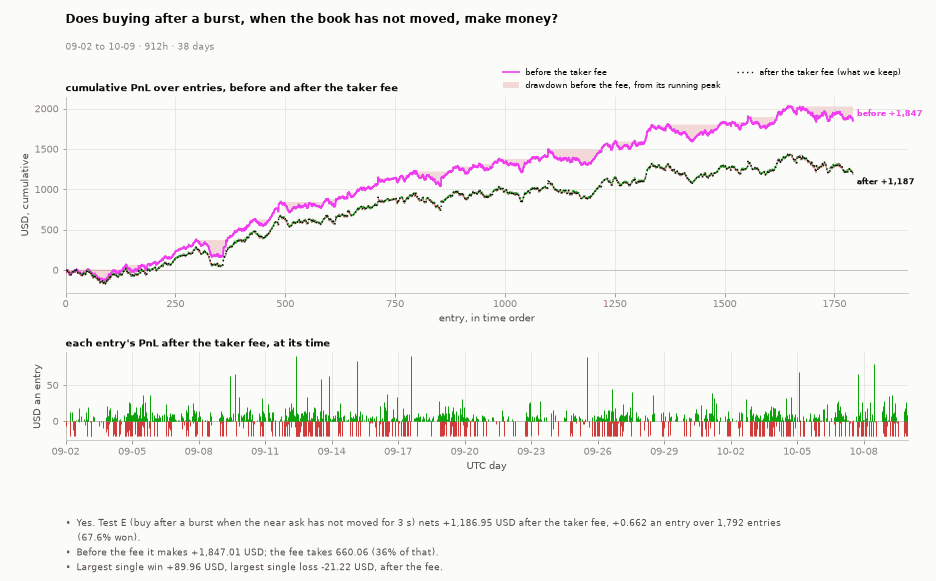

In [9]:
figstyle.show(TF.equity_fig(E_ALL, DAYS, question="Does buying after a burst, when the book has not moved, make money?", who="Test E (buy after a burst when the near ask has not moved for 3 s)"), "fig:s3-e-equity", FIGURES)

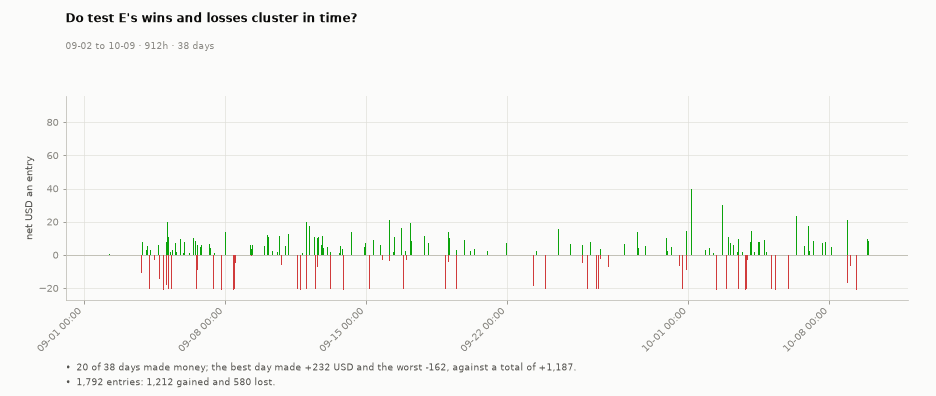

In [10]:
figstyle.show(TF.trade_pnl_fig(E_ALL, DAYS, question="Do test E's wins and losses cluster in time?"), "fig:s3-e-tradepnl", FIGURES)

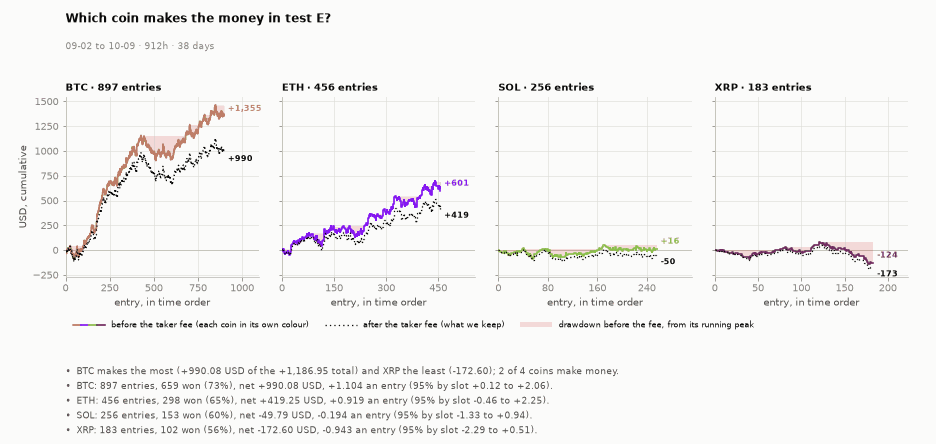

In [11]:
figstyle.show(TF.coin_panels_fig(E_ALL, DAYS, question="Which coin makes the money in test E?"), "fig:s3-e-coins", FIGURES)

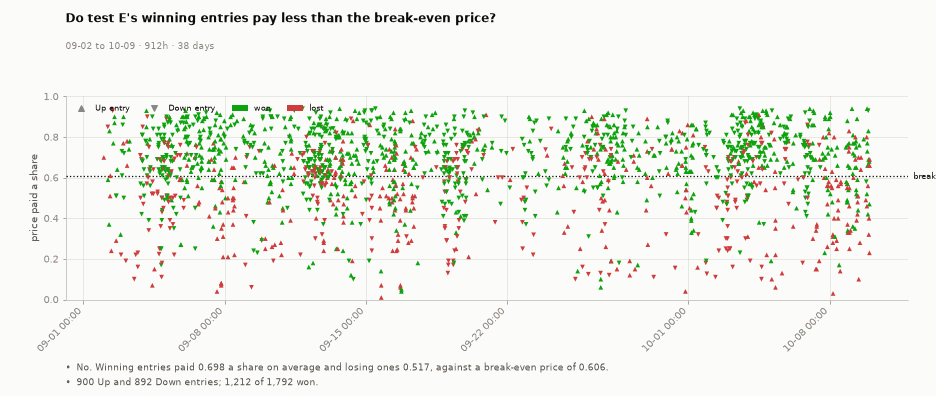

In [12]:
figstyle.show(TF.entry_price_fig(E_ALL, DAYS, be=float(S_E["breakeven"]), question="Do test E's winning entries pay less than the break-even price?", s=22, edge=False), "fig:s3-e-entrypx", FIGURES)

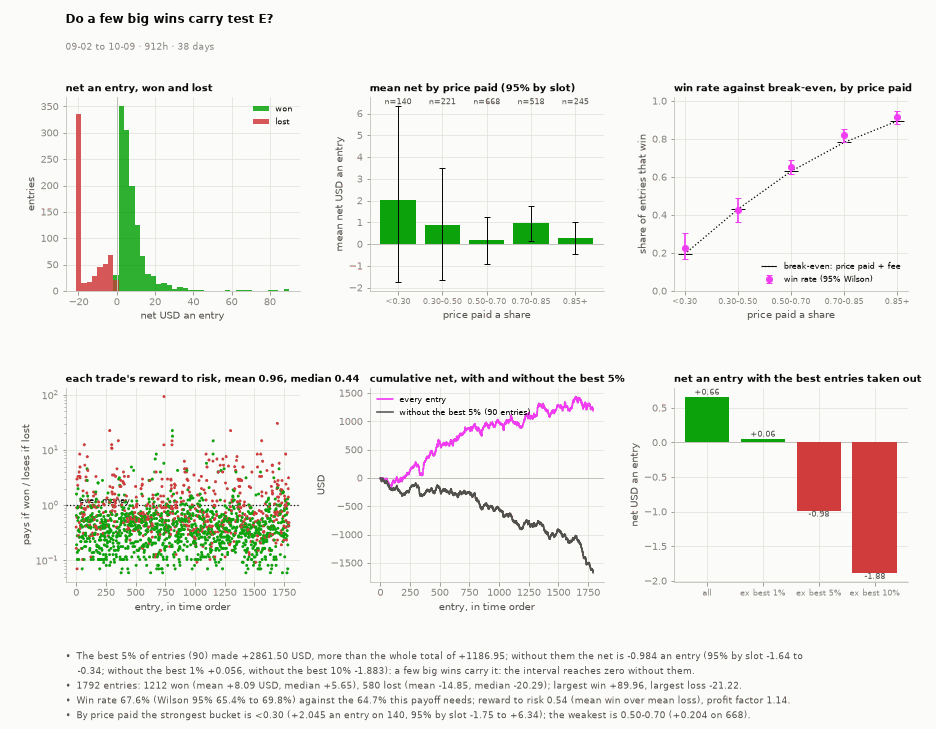

In [13]:
figstyle.show(TF.winloss_fig(E_ALL, DAYS, question="Do a few big wins carry test E?"), "fig:s3-e-winloss", FIGURES)

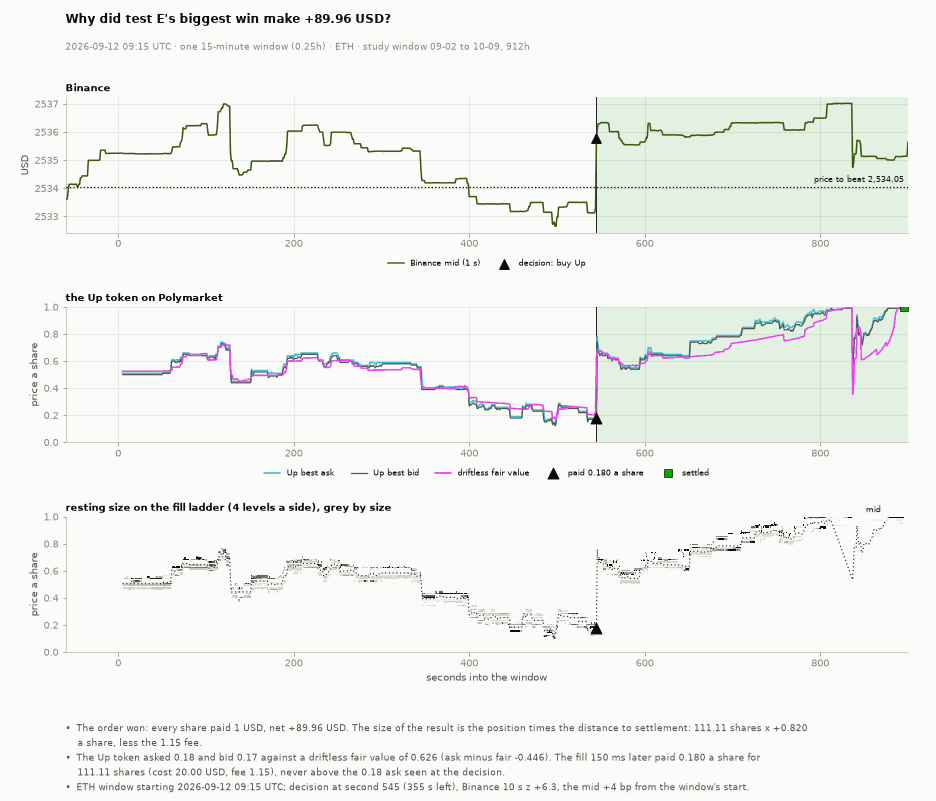

**Fill ladder at second 545 + 150 ms, ETH Up token: a buy of 20 USD of Up at no worse than the 0.18 ask seen at the decision; fair value 0.626; took 111.11 shares for 20.00 USD at risk.**

level,bid_size,bid,ask,ask_size,taken_shares,usd_at_risk
1,33.79,0.17,0.18,498.52,111.11,19.9998
2,30.00,0.16,0.19,536.00,0.00,0.0000
3,30.00,0.15,0.20,391.00,0.00,0.0000
4,165.00,0.14,0.22,210.00,0.00,0.0000


In [14]:
_i = int(np.argmax(E_ALL["net"]))
figstyle.show(TF.anatomy_fig(TAB, E_ALL, _i, DAYS, question=f"Why did test E's biggest win make {E_ALL['net'][_i]:+.2f} USD?", usd=CLIP_USD), "fig:s3-e-bigwin", FIGURES)
_df, _cap = TF.ladder_table(TAB, E_ALL, _i, usd=CLIP_USD)
display(Markdown("**" + _cap + "**")); display(HTML(_df.round(4).to_html(index=False, border=0)))

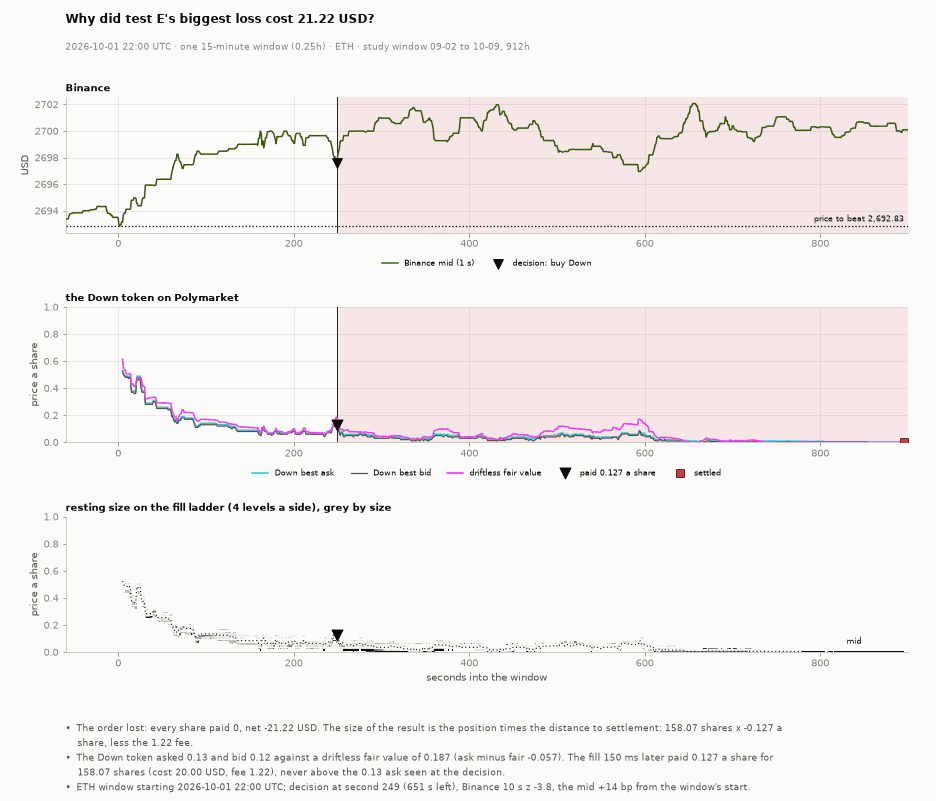

**Fill ladder at second 249 + 150 ms, ETH Down token: a buy of 20 USD of Down at no worse than the 0.13 ask seen at the decision; fair value 0.187; took 158.07 shares for 20.00 USD at risk.**

level,bid_size,bid,ask,ask_size,taken_shares,usd_at_risk
1,60.39,0.11,0.12,55.00,55.00,6.6000
2,80.77,0.10,0.13,109.07,103.07,13.3991
3,327.00,0.09,0.14,49.00,0.00,0.0000
4,951.00,0.08,0.15,180.00,0.00,0.0000


In [15]:
_i = int(np.argmin(E_ALL["net"]))
figstyle.show(TF.anatomy_fig(TAB, E_ALL, _i, DAYS, question=f"Why did test E's biggest loss cost {-E_ALL['net'][_i]:.2f} USD?", usd=CLIP_USD), "fig:s3-e-bigloss", FIGURES)
_df, _cap = TF.ladder_table(TAB, E_ALL, _i, usd=CLIP_USD)
display(Markdown("**" + _cap + "**")); display(HTML(_df.round(4).to_html(index=False, border=0)))

### How is a setting chosen each week?

The days are cut into weeks by date. From the second week on, the setting is chosen on the weeks before it only and traded on that week alone; week one is only
ever chosen on. Each setting is scored by its net an entry without the best 5% of entries, averaged with its neighbouring stale windows (same definition, discount
and limit) so a lone lucky window cannot win; settings with fewer than `TUNE_N_MIN` entries are skipped, and a tie goes to the shorter window.

Two checks follow: is the pick the same stale window week after week (gate G4), and does each traded week agree with the weeks it was chosen from, meaning above
zero without the best 5% and inside the in-sample 95% interval (gate G15)? Beside them, does the tuned rule beat test E as built on the same traded days? If not,
tuning added nothing (gate G3).

### S3.2 · Which settings earn over every seated day?

Every setting on every seated day at once. It describes where the rule earns and chooses nothing; S3.3 does the choosing.

  54 of 162 cells run


  108 of 162 cells run


  162 of 162 cells run


162 cells run and read in 56s; the plateau centre on every day: a12|th0.08|ask


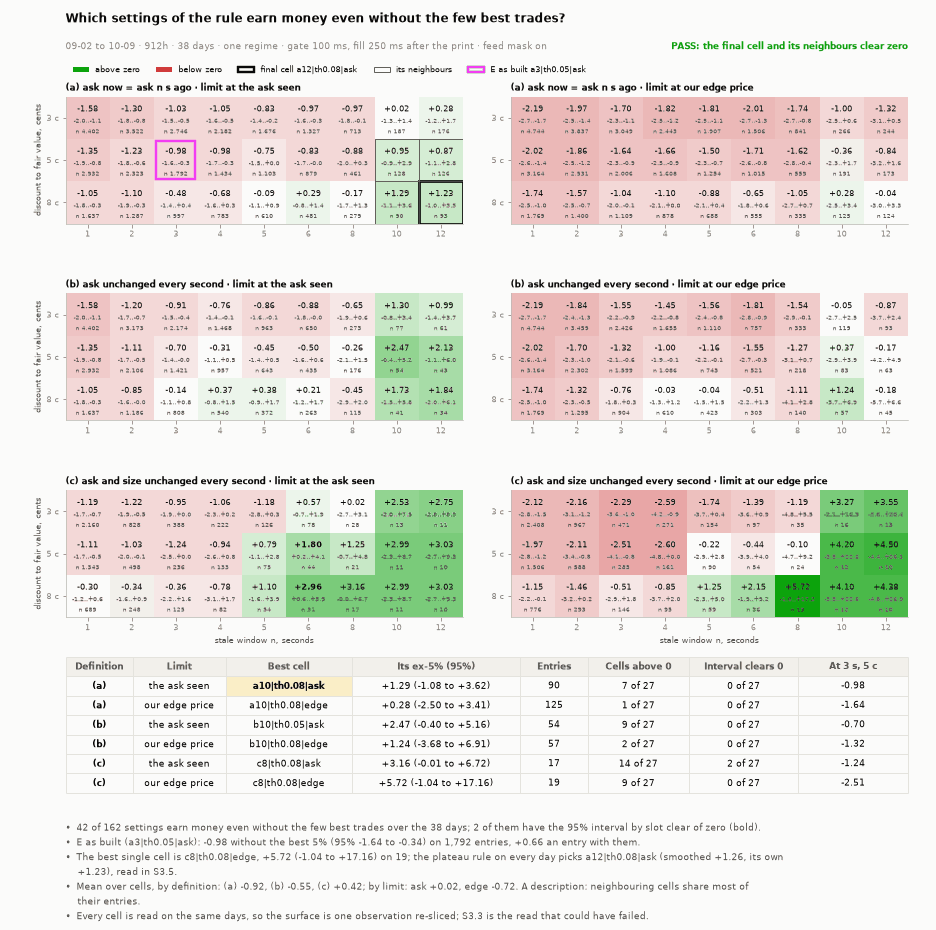

In [16]:
_t = time.time()
TUNE = ST.run_tune(CAND, TAB, TUNE_CELLS, log=print)
assert _same(TUNE[CFG_E["name"]], E_ALL), "the grid's E cell is not E"
SURF = {c_["name"]: ST.stats5(TUNE[c_["name"]]) for c_ in TUNE_CELLS}
FINAL_RANK = ST.choose_plateau(TUNE, TUNE_CELLS, ALL_IDX, TUNE_N_MIN, TUNE_LEVELS)
FINAL_ROW = FINAL_RANK[0]
CFG = FINAL_ROW["cfg"]
FINAL_IS_E = CFG["name"] == CFG_E["name"]
TUNE_SECONDS = time.time() - _t
SURF_DF = pd.DataFrame([dict(cell=c_["name"], definition=c_["kind"], n_s=c_["n"], theta=c_["theta"], limit=c_["limit"], entries=SURF[c_["name"]]["n"], per=SURF[c_["name"]]["per"],
                             ex5=SURF[c_["name"]]["per_ex_top5"], ex5_lo=SURF[c_["name"]]["per_ex_top5_lo"], ex5_hi=SURF[c_["name"]]["per_ex_top5_hi"]) for c_ in TUNE_CELLS])
_fb = ST.block_names(TUNE_CELLS, CFG, TUNE_LEVELS)
PLATEAU_OK = bool(_fb) and all(np.isfinite(SURF[x_]["per_ex_top5"]) and SURF[x_]["per_ex_top5"] > 0 for x_ in [CFG["name"], *_fb])
print(f"{len(TUNE):,} cells run and read in {TUNE_SECONDS:.0f}s; the plateau centre on every day: {CFG['name']}")
_e, _best = SURF[CFG_E["name"]], SURF_DF.sort_values("ex5", ascending=False).iloc[0]
_bk = SURF_DF.groupby("definition")["ex5"].mean()
_bl = SURF_DF.groupby("limit")["ex5"].mean()
_notes = [f"{int((SURF_DF.ex5 > 0).sum())} of {len(SURF_DF)} settings earn money even without the few best trades over the {len(DAYS)} days; {int((SURF_DF.ex5_lo > 0).sum())} of them have the 95% interval by slot clear of zero (bold).",
          f"E as built ({CFG_E['name']}): {sgn(_e['per_ex_top5'])} without the best 5% (95% {sgn(_e['per_ex_top5_lo'])} to {sgn(_e['per_ex_top5_hi'])}) on {_e['n']:,} entries, {sgn(_e['per'])} an entry with them.",
          f"The best single cell is {_best.cell}, {sgn(_best.ex5)} ({sgn(_best.ex5_lo)} to {sgn(_best.ex5_hi)}) on {int(_best.entries):,}; the plateau rule on every day picks {CFG['name']} "
          f"(smoothed {sgn(FINAL_ROW['smoothed'])}, its own {sgn(FINAL_ROW['score'])}), " + ("which is E as built." if FINAL_IS_E else "read in S3.5."),
          "Mean over cells, by definition: " + ", ".join(f"({k_}) {v_:+.2f}" for k_, v_ in _bk.items()) + "; by limit: " + ", ".join(f"{k_} {v_:+.2f}" for k_, v_ in _bl.items())
          + ". A description: neighbouring cells share most of their entries.",
          "Every cell is read on the same days, so the surface is one observation re-sliced; S3.3 is the read that could have failed."]
figstyle.show(ST.surface_all_fig(SURF, TUNE_CELLS, CFG_E["name"], CFG["name"], WIN, _notes, TUNE_LEVELS), "fig:s3-surface", FIGURES)

### S3.3 · Does picking the setting from past weeks beat the plain 3-second rule?

Each week from the second is traded with the setting chosen on every week before it. E tuned is the record those weeks make, beside E as built and rule A on the
same days (gate G3).

**Each traded week's pick and its three runners-up**, scored on the choosing weeks only (rank 1 is the pick)

traded_week,chosen_on,rank,setting,entries,ex5,smoothed,qualifies
09-09 to 09-15,09-02 to 09-08,1,a6|th0.08|ask,94,-0.001,1.101,True
09-09 to 09-15,09-02 to 09-08,2,a8|th0.05|ask,74,-0.303,0.951,True
09-09 to 09-15,09-02 to 09-08,3,b6|th0.08|edge,65,-1.415,0.660,True
09-09 to 09-15,09-02 to 09-08,4,b5|th0.08|ask,71,0.944,0.588,True
09-16 to 09-22,09-02 to 09-15,1,a12|th0.08|edge,62,2.713,3.027,True
09-16 to 09-22,09-02 to 09-15,2,a10|th0.08|edge,65,3.341,2.426,True
09-16 to 09-22,09-02 to 09-15,3,a12|th0.05|ask,65,2.286,2.407,True
09-16 to 09-22,09-02 to 09-15,4,b8|th0.08|edge,69,0.908,2.256,True
09-23 to 09-29,09-02 to 09-22,1,a12|th0.08|edge,78,4.307,3.545,True
09-23 to 09-29,09-02 to 09-22,2,a12|th0.05|ask,79,2.992,2.976,True


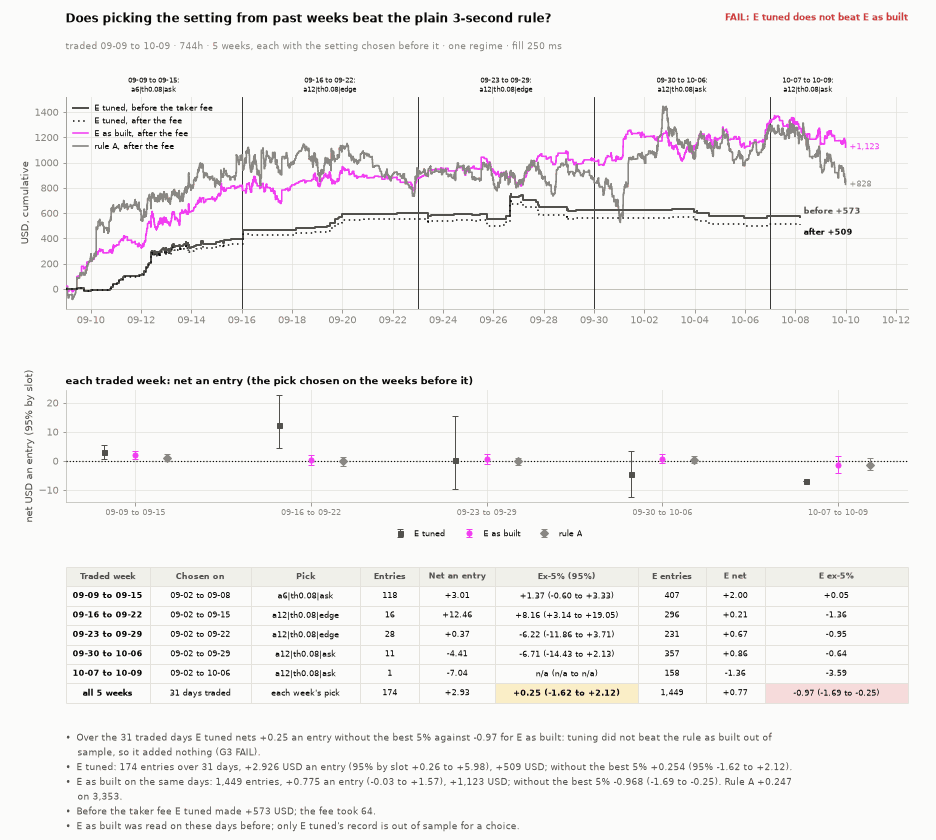

In [17]:
WF = ST.walk_forward(TUNE, TUNE_CELLS, len(DAYS), WEEK, TUNE_N_MIN, TUNE_LEVELS, e_name=CFG_E["name"])
OOS_IDX = WF["oos_idx"]
OOS_DAYS = [DAYS[i_] for i_ in OOS_IDX]
ENT = WF["record"]
REC_E, REC_A = ST.by_days(E_ALL, OOS_IDX), ST.by_days(A_ALL, OOS_IDX)
TS, TS_E, TS_A = ST.stats5(ENT), ST.stats5(REC_E), ST.stats5(REC_A)
WIN_WF = f"traded {OOS_DAYS[0][5:]} to {OOS_DAYS[-1][5:]} · {24 * len(OOS_DAYS):,}h · {len(WF['folds'])} weeks, each with the setting chosen before it · one regime · fill {LAT_MS} ms"
WK = lambda f_: ST.week_name(DAYS, f_["out_idx"])
G_WALK = bool(TS.get("n") and TS_E.get("n") and TS["per_ex_top5"] > TS_E["per_ex_top5"] and TS["per_ex_top5_lo"] > 0)
_rows = [dict(traded_week=WK(f_), chosen_on=ST.week_name(DAYS, f_["choose_idx"]), rank=j_ + 1, setting=r_["cfg"]["name"], entries=r_["n"],
              ex5=r_["score"], smoothed=r_["smoothed"], qualifies=r_["eligible"]) for f_ in WF["folds"] for j_, r_ in enumerate(f_["rank"])]
display(Markdown("**Each traded week's pick and its three runners-up**, scored on the choosing weeks only (rank 1 is the pick)"))
display(HTML(pd.DataFrame(_rows).round(3).to_html(index=False, border=0)))
_notes = [f"Over the {len(OOS_DAYS)} traded days E tuned nets {sgn(TS['per_ex_top5'])} an entry without the best 5% against {sgn(TS_E['per_ex_top5'])} for E as built: "
          + ("tuning beat the rule as built out of sample (G3 PASS)." if G_WALK else "tuning did not beat the rule as built out of sample, so it added nothing (G3 FAIL)."),
          f"E tuned: {TS['n']:,} entries over {len(OOS_DAYS)} days, {sgn(TS['per'], 3)} USD an entry (95% by slot {sgn(TS['per_lo'])} to {sgn(TS['per_hi'])}), {sgn(TS['net'], 0)} USD; "
          f"without the best 5% {sgn(TS['per_ex_top5'], 3)} (95% {sgn(TS['per_ex_top5_lo'])} to {sgn(TS['per_ex_top5_hi'])}).",
          f"E as built on the same days: {TS_E['n']:,} entries, {sgn(TS_E['per'], 3)} an entry ({sgn(TS_E['per_lo'])} to {sgn(TS_E['per_hi'])}), {sgn(TS_E['net'], 0)} USD; without the best 5% "
          f"{sgn(TS_E['per_ex_top5'], 3)} ({sgn(TS_E['per_ex_top5_lo'])} to {sgn(TS_E['per_ex_top5_hi'])}). Rule A {sgn(TS_A['per'], 3)} on {TS_A['n']:,}.",
          f"Before the taker fee E tuned made {sgn(float(ENT['gross'].sum()), 0)} USD; the fee took {float(ENT['fee'].sum()):,.0f}.",
          "E as built was read on these days before; only E tuned's record is out of sample for a choice."]
figstyle.show(ST.walk_fig({"tuned": ("E tuned", ENT), "E": ("E as built", REC_E), "A": ("rule A", REC_A)}, WF, DAYS, _notes, WIN_WF, G_WALK), "fig:s3-walk", FIGURES)

### S3.4 · Is the setting we picked the same from week to week, and does the week we traded agree with the weeks we picked from?

Each panel is one traded week, along the stale window: the score on its choosing weeks (raw, and smoothed as the rule reads it) and what the traded week then
earned (gates G4 and G15).

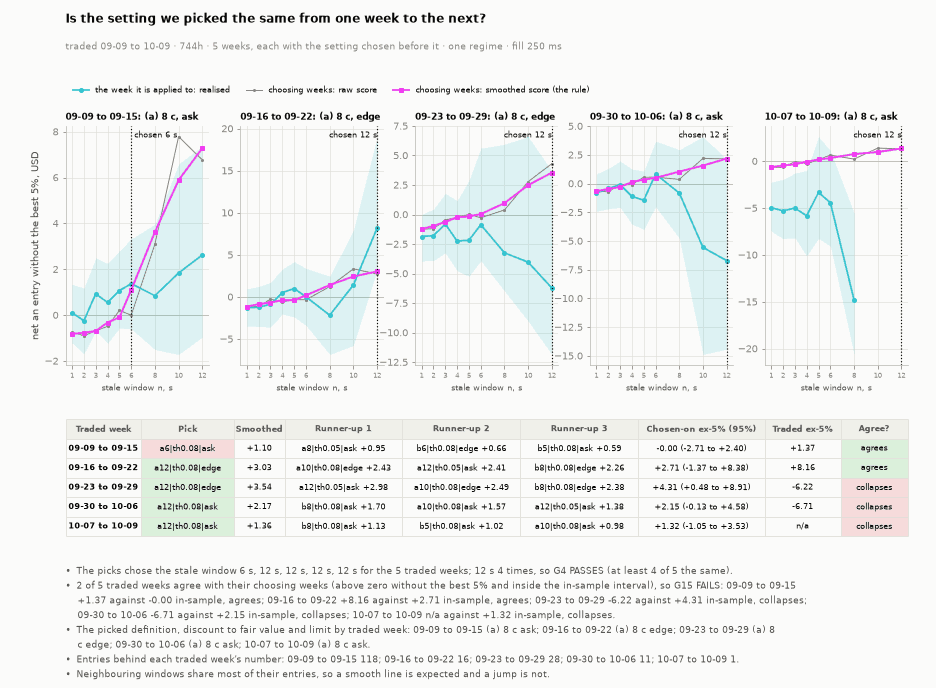

In [18]:
NS_CHOSEN = [f_["chosen"]["cfg"]["n"] for f_ in WF["folds"]]
N_MODE, N_MODE_COUNT = Counter(NS_CHOSEN).most_common(1)[0]
G_STABLE = N_MODE_COUNT >= STABLE_MIN
N_AGREE = sum(f_["agree"] for f_ in WF["folds"])
G_AGREE = N_AGREE >= STABLE_MIN
_here = [next(c_ for c_ in f_["curve"] if c_["n"] == f_["chosen"]["cfg"]["n"])["week"] for f_ in WF["folds"]]
_notes = ["The picks chose the stale window " + ", ".join(f"{f_['chosen']['cfg']['n']} s" for f_ in WF["folds"]) + f" for the {len(WF['folds'])} traded weeks; "
          + (f"{N_MODE} s {N_MODE_COUNT} times" if N_MODE_COUNT > 1 else "no window twice") + f", so G4 {'PASSES' if G_STABLE else 'FAILS'} (at least {STABLE_MIN} of {len(NS_CHOSEN)} the same).",
          f"{N_AGREE} of {len(WF['folds'])} traded weeks agree with their choosing weeks (above zero without the best 5% and inside the in-sample interval), so G15 "
          + f"{'PASSES' if G_AGREE else 'FAILS'}: " + "; ".join(f"{WK(f_)} {sgn(f_['s'].get('per_ex_top5'))} against {sgn(f_['s_in'].get('per_ex_top5'))} in-sample, {'agrees' if f_['agree'] else 'collapses'}" for f_ in WF["folds"]) + ".",
          "The picked definition, discount to fair value and limit by traded week: " + "; ".join(f"{WK(f_)} ({f_['chosen']['cfg']['kind']}) {f_['chosen']['cfg']['theta'] * 100:.0f} c {f_['chosen']['cfg']['limit']}" for f_ in WF["folds"]) + ".",
          "Entries behind each traded week's number: " + "; ".join(f"{WK(f_)} {h_.get('n', 0):,}" for f_, h_ in zip(WF["folds"], _here)) + ".",
          "Neighbouring windows share most of their entries, so a smooth line is expected and a jump is not."]
figstyle.show(ST.stable_fig(WF, DAYS, _notes, WIN_WF), "fig:s3-stable", FIGURES)

### S3.5 · Does the final setting survive a late order and a higher fee?

The same rule on every seated day picks the setting a forward read would freeze. Its numbers on those days are in-sample; its honest read is the walk-forward row.
Delay and fee are read against E as built (S4.2 and S4.3 draw both in full).

final cell read in 18s; seated tables [250]


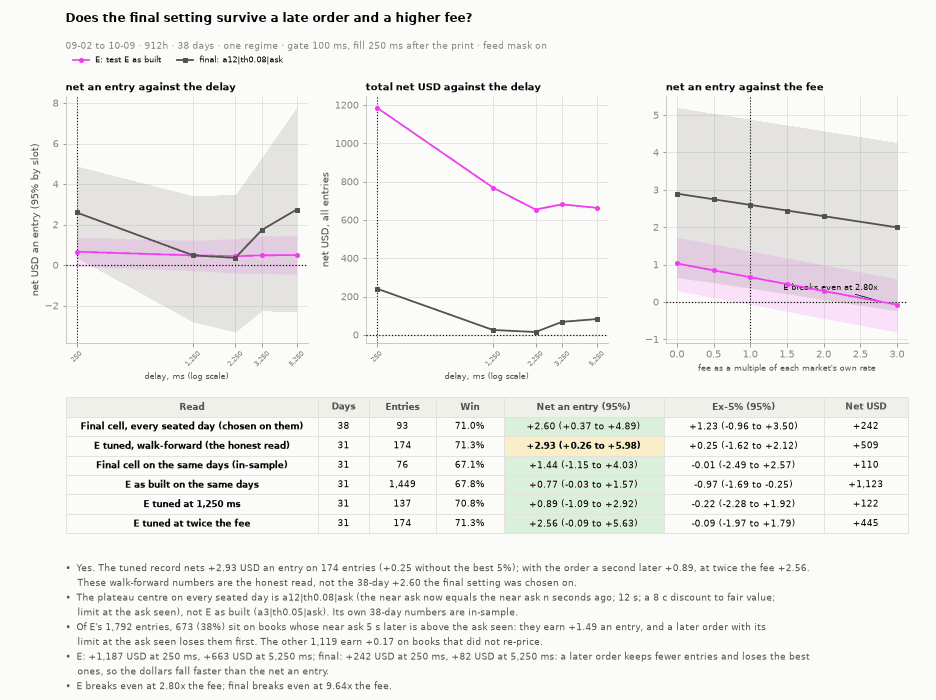

In [19]:
import gc
_t = time.time()
CELL_ALL = TUNE[CFG["name"]]
S_CELL = ST.stats5(CELL_ALL)
REC_F = ST.by_days(CELL_ALL, OOS_IDX)
TS_F = ST.stats5(REC_F)
WF_1S = ST.stats(ST.wf_variant(CAND, TAB, WF, delay_k=1))
WF_FEE2 = ST.stats(ST.wf_variant(CAND, TAB, WF, fee_mult=2.0))
SH, DSR = ST.deflated_record(TUNE, ENT)
LAT_TABS = {LAT_MS: TAB}
LAT_MISSING = {}
for ms_ in (150, 500, 1000):
    miss_ = [d_ for d_ in DAYS if RUNNER.seated(d_, ms_, DECIDE_MS, REF) is None]
    if miss_:
        LAT_MISSING[ms_] = miss_
        continue
    LAT_TABS[ms_] = B.Tab(DAYS, fill_ms=ms_, decide_ms=DECIDE_MS, ref=REF)
LAT = {"E": ("E: test E as built", ST.latency_rows(CAND, LAT_TABS, CFG_E, LAT_MS, EXTRA_S)), "cell": (f"final: {CFG['name']}", ST.latency_rows(CAND, LAT_TABS, CFG, LAT_MS, EXTRA_S))}
DELAY_E = {"E": ST.delay_entries(CAND, LAT_TABS, CFG_E, LAT_MS, EXTRA_S), "cell": ST.delay_entries(CAND, LAT_TABS, CFG, LAT_MS, EXTRA_S)}     # S4.2's paths
LAT_SEATED = sorted(LAT_TABS)
for ms_ in [m_ for m_ in LAT_TABS if m_ != LAT_MS]:
    del LAT_TABS[ms_]
gc.collect()
COSTS = {"E": ("E: test E as built", ST.cost_read(CAND, TAB, CFG_E, ALL_IDX, FEE_MULTS, SLIPS)), "cell": (f"final: {CFG['name']}", ST.cost_read(CAND, TAB, CFG, ALL_IDX, FEE_MULTS, SLIPS))}
REPRICE = {"E": ST.repricing_split(TAB, E_ALL), "cell": ST.repricing_split(TAB, CELL_ALL)}
print(f"final cell read in {time.time() - _t:.0f}s; seated tables {LAT_SEATED}")
_ci = lambda s_: f"{sgn(s_.get('per_ex_top5'))} ({sgn(s_.get('per_ex_top5_lo'))} to {sgn(s_.get('per_ex_top5_hi'))})"
_line = lambda lab_, nd_, s_: [lab_, f"{nd_}", f"{s_.get('n', 0):,}", pct(s_.get("win", float("nan"))), f"{sgn(s_.get('per'))} ({sgn(s_.get('per_lo'))} to {sgn(s_.get('per_hi'))})", _ci(s_), sgn(s_.get("net", float("nan")), 0)]
FINAL_ROWS = [_line("Final cell, every seated day (chosen on them)", len(DAYS), S_CELL), _line("E tuned, walk-forward (the honest read)", len(OOS_DAYS), TS),
              _line("Final cell on the same days (in-sample)", len(OOS_DAYS), TS_F), _line("E as built on the same days", len(OOS_DAYS), TS_E),
              _line("E tuned at 1,250 ms", len(OOS_DAYS), WF_1S), _line("E tuned at twice the fee", len(OOS_DAYS), WF_FEE2)]
_rp = REPRICE["E"]
_n_rest = _rp["same"][0] + _rp["lower"][0]
_ok_late = bool(WF_1S.get("n") and WF_1S["per"] > 0 and WF_FEE2.get("n") and WF_FEE2["per"] > 0)
_notes = [f"{'Yes' if _ok_late else 'No'}. The tuned record nets {sgn(TS['per'])} USD an entry on {TS['n']:,} entries ({sgn(TS['per_ex_top5'])} without the best 5%); with the order a second later "
          f"{sgn(WF_1S['per'])}, at twice the fee {sgn(WF_FEE2['per'])}. These walk-forward numbers are the honest read, not the {len(DAYS)}-day {sgn(S_CELL['per'])} the final setting was chosen on.",
          ("The plateau centre on every seated day is E as built: the tuning confirms 3 s, definition (a), a 5 c discount to fair value and the ask-seen limit."
           if FINAL_IS_E else f"The plateau centre on every seated day is {CFG['name']} ({C.STALE_DEFS[CFG['kind']].split('(')[0].strip()}; {CFG['n']} s; a {CFG['theta'] * 100:.0f} c discount to fair value; limit at {ST.LIMIT_NAME[CFG['limit']]}), not E as built ({CFG_E['name']}).")
          + f" Its own {len(DAYS)}-day numbers are in-sample.",
          f"Of E's {S_E['n']:,} entries, {_rp['higher'][0]:,} ({_rp['higher'][0] / max(S_E['n'], 1):.0%}) sit on books whose near ask 5 s later is above the ask seen: they earn {sgn(_rp['higher'][1])} an entry, "
          f"and a later order with its limit at the ask seen loses them first. The other {_n_rest:,} earn {sgn((_rp['same'][2] + _rp['lower'][2]) / max(_n_rest, 1))} on books that did not re-price.",
          "; ".join(f"{t_.split(':')[0]}: " + ", ".join(f"{sgn(r_['total'], 0)} USD at {r_['ms']:,} ms" for r_ in ([rr_[0]] if rr_[0]['ms'] != LAT_MS else []) + [next(r_ for r_ in rr_ if r_['ms'] == LAT_MS), rr_[-1]]) for t_, rr_ in LAT.values())
          + ": a later order keeps fewer entries and loses the best ones, so the dollars fall faster than the net an entry.",
          "; ".join(f"{t_.split(':')[0]} breaks even at {c_['be_mult']:.2f}x the fee" for t_, c_ in COSTS.values()) + "."]
figstyle.show(ST.final_fig({k_: LAT[k_] for k_ in ("E", "cell")}, COSTS, FINAL_ROWS, ["Read", "Days", "Entries", "Win", "Net an entry (95%)", "Ex-5% (95%)", "Net USD"], _notes, WIN, LAT_MS),
              "fig:s3-final", FIGURES)

In [20]:
# ---- the live spec of the final cell, for the paper run (tf15_live.to_spec) ----
import json
import tf15_live as LV
RULE_LIVE, WHY_NO_LIVE = ST.live_rule(CFG, CLIP_USD)
if RULE_LIVE is not None and CFG["limit"] == "ask":
    SPEC = LV.to_spec(RULE_LIVE)
    assert LV.to_spec(LV.from_spec(json.loads(json.dumps(SPEC)))) == SPEC, "the spec does not round-trip"
    display(Markdown("**Live spec of the final cell** (round-trips through `tf15_live.from_spec`)\n\n```json\n" + json.dumps(SPEC, indent=1) + "\n```\n\n" + LV.explain(RULE_LIVE)))
else:
    if CFG["limit"] != "ask":
        WHY_NO_LIVE = (WHY_NO_LIVE + "; " if WHY_NO_LIVE else "") + "the edge-price limit (fair value less the discount) is not a parameter of `tf15_live.LayeredRule`, which pays at most the ask seen"
    SPEC = dict(LV.to_spec(LV.LayeredRule(L=CFG["L"], z_min=CFG["z_min"], theta=CFG["theta"], band=C.STALE_BANDS[CFG["band"]], t_min=CFG["t_min"], stale_s=CFG["n"], usd=CLIP_USD, name=CFG["name"])),
                stale_kind=CFG["kind"], fill_limit=CFG["limit"])
    display(Markdown("**Live spec of the final cell, with its stale definition and fill limit named** (`stale_kind`, `fill_limit`)\n\n```json\n" + json.dumps(SPEC, indent=1) + f"\n```\n\n{WHY_NO_LIVE}."))

**Live spec of the final cell** (round-trips through `tf15_live.from_spec`)

```json
{
 "rule": "buy_near_layered",
 "version": 1,
 "L": 10,
 "z_min": 3.0,
 "theta": 0.08,
 "band": [
  0.0,
  1.0
 ],
 "t_min": 300.0,
 "usd": 20.0,
 "exits": [],
 "name": "a12|th0.08|ask",
 "time": null,
 "hour": null,
 "spread": null,
 "gap": null,
 "rsi": null,
 "level": null,
 "flow": null,
 "coin": null,
 "onset": false,
 "slot_one": false,
 "stale_s": 12
}
```

Every second of each 15-minute Up/Down window it watches the Binance trade-implied mid of the coin and its 10-second move in vol units. When that move is 3 or more upward it considers the Up token, when it is 3 or more downward the Down token (the near token, the side the move points to). It buys only if the token's best ask is more than 8 cents under its driftless fair value (the Brownian P of ending on that side), the ask is between 0 and 100 cents, and at least 300 seconds are left. It spends 20 USD, taking asks best first and never above the ask it saw, and does not trade if fewer than 5 shares fill (it then keeps looking); one position a window. It buys only when the near token's best ask has not moved for the last 12 seconds (never in the first 12 seconds). Once in, it holds to expiry. The venue pays 1 USD a share if the token's side wins and 0 otherwise. The market's taker fee, rate x p x (1 - p) a share, is paid on each trade.

### S3.6 · Did the tuned rule grow the account faster than the plain rule?

E tuned starts at the second week, so its total is compared with E as built's on the same days in the bullets, not at the line ends.

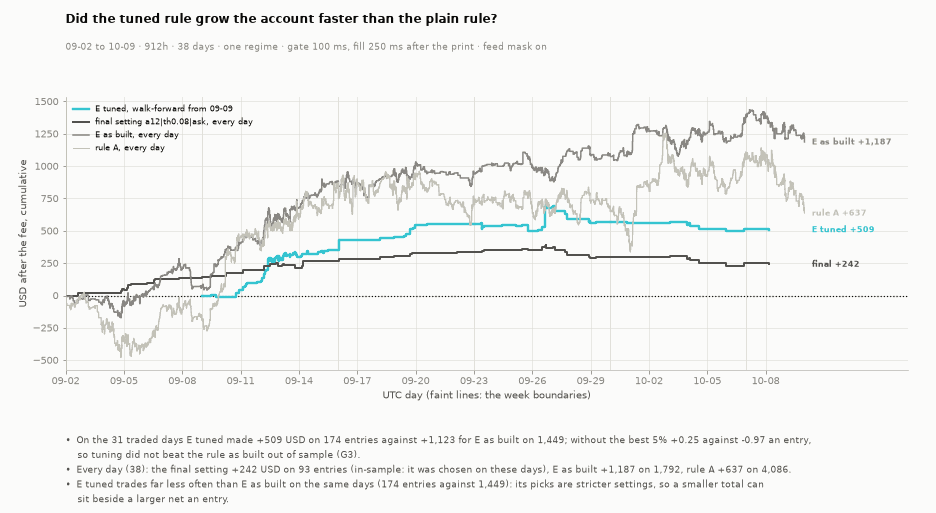

In [21]:
_tot = lambda e_: float(np.sum(e_["net"]))
_lines = [("E tuned, walk-forward from " + OOS_DAYS[0][5:], "E tuned", ENT, figstyle.IDENTITY["POLYMARKET"], 2.4, int(OOS_IDX[0])),
          (f"final setting {CFG['name']}, every day", "final", CELL_ALL, ST.INK2, 2.0, 0), ("E as built, every day", "E as built", E_ALL, ST.MUTED, 1.5, 0),
          ("rule A, every day", "rule A", A_ALL, N_AXIS, 1.3, 0)]
_notes = [f"On the {len(OOS_DAYS)} traded days E tuned made {sgn(TS['net'], 0)} USD on {TS['n']:,} entries against {sgn(TS_E['net'], 0)} for E as built on {TS_E['n']:,}; without the best 5% "
          f"{sgn(TS['per_ex_top5'])} against {sgn(TS_E['per_ex_top5'])} an entry, so tuning " + ("beat" if G_WALK else "did not beat") + " the rule as built out of sample (G3).",
          f"Every day ({len(DAYS)}): the final setting {sgn(_tot(CELL_ALL), 0)} USD on {S_CELL['n']:,} entries (in-sample: it was chosen on these days), E as built {sgn(_tot(E_ALL), 0)} on {S_E['n']:,}, "
          f"rule A {sgn(_tot(A_ALL), 0)} on {S_A['n']:,}.",
          f"E tuned trades far less often than E as built on the same days ({TS['n']:,} entries against {TS_E['n']:,}): its picks are stricter settings, so a smaller total can sit beside a larger net an entry."]
figstyle.show(ST.rules_paths_fig(_lines, DAYS, WF["weeks"], WIN, _notes), "fig:s3-paths", FIGURES)

## S4 · Robustness - Does the edge survive new days, luck, delay and fees?

On the final cell and on test E side by side. The final cell was chosen on every seated day, so its blocks and weeks here are consistency checks; S3.3 is its clean
read.

### S4.1 · Does the rule beat luck, and does it keep making money on days it was not read on?

The luck test buys the same number of entries per day and coin at random seconds that pass every condition of the cell except the burst, at the ask seen: does the
burst's direction add anything to a book that already passes the gate? The coin-flip side is a reading only: it buys the far token, so it measures the price gate and
cannot fail.

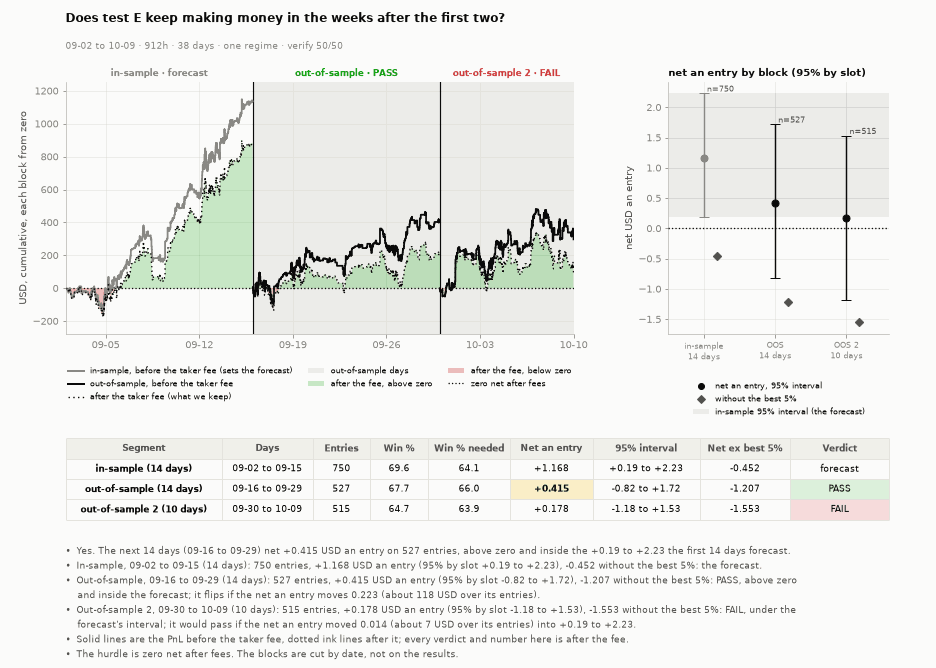

In [22]:
WIN_ = f"{DAYS[0][5:]} to {DAYS[-1][5:]} · {24 * len(DAYS):,}h · {len(DAYS)} days · one regime · verify {VERIFY_PASSED}/{VERIFY_TOTAL}"
_r = O.read_blocks(E_ALL, DAYS, N_IS, N_OOS)
OOS2W_E = _r
figstyle.show(OF.oos2w_fig(E_ALL, DAYS, _r, OF.block_notes(_r, O.MIN_N), "Does test E keep making money in the weeks after the first two?", WIN_), "fig:s4-e-oos2w", FIGURES)

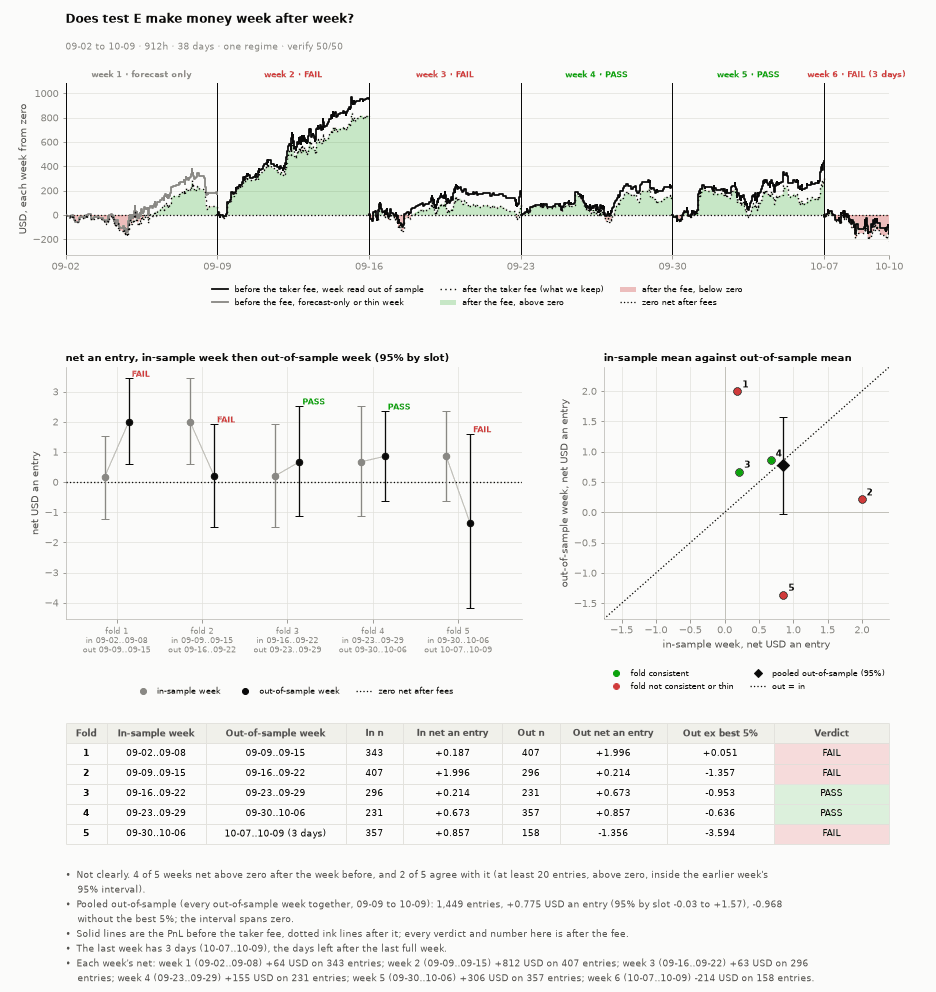

In [23]:
_f = O.read_folds(E_ALL, DAYS, WEEK)
FOLDS_E = _f
figstyle.show(OF.folds_fig(E_ALL, DAYS, _f, OF.fold_notes(_f, DAYS, WEEK, O.MIN_N), "Does test E make money week after week?", WIN_), "fig:s4-e-oosfolds", FIGURES)

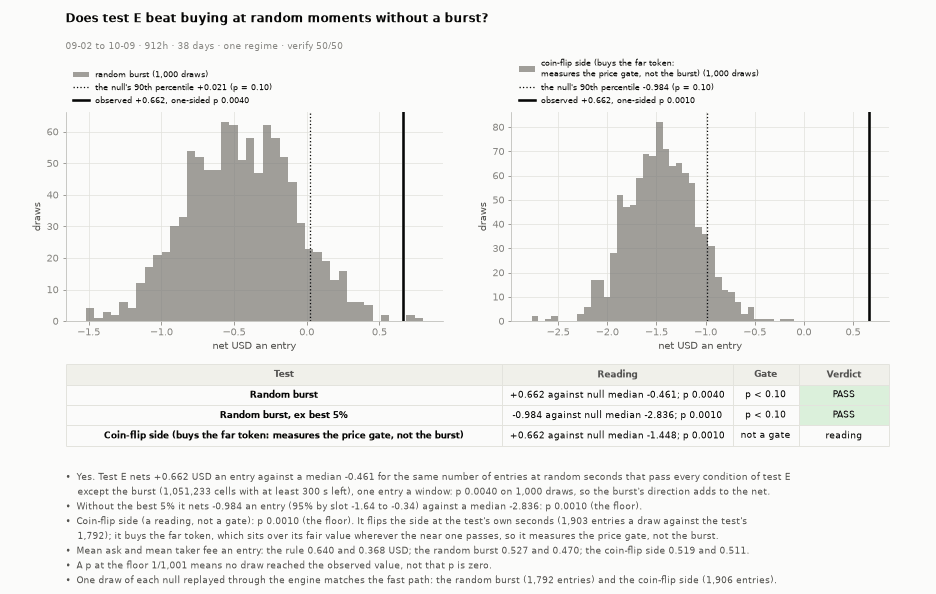

In [24]:
_s = ST.stats5(E_ALL)
_g, _tm, _m = CAND.gates(TAB, CFG_E), C.tmask(TAB, CFG_E["t_min"]), ST.burst_masks(TAB, CFG_E, feed=CAND.feed)
_rs = O.random_side(TAB, _g, _tm, usd=CLIP_USD, draws=N_DRAWS, seed=31)
_rb = O.random_burst(TAB, E_ALL, _m, "A", t_min=CFG_E["t_min"], usd=CLIP_USD, draws=N_DRAWS, seed=37)
_ok_s, _n_s = O.side_agrees(TAB, _g, _tm, usd=CLIP_USD)
_ag = O.burst_agrees(TAB, E_ALL, _m, "A", theta=CFG_E["theta"], t_min=CFG_E["t_min"], usd=CLIP_USD)
assert _ok_s and _ag["agree"] and not _ag["faults"], f"a randomised null disagrees with B.entries or breaks its own rules: {_ag}"
_ask = O.ask_of(TAB, E_ALL)
_p = dict(burst=O.p_one_sided(_rb["per"], _s["per"]), burst_ex5=O.p_one_sided(_rb["ex5"], _s["per_ex_top5"]), side=O.p_one_sided(_rs["per"], _s["per"]), side_ex5=O.p_one_sided(_rs["ex5"], _s["per_ex_top5"]))
RAND_E = _p
_rows, _notes = OF.burst_rows("E", _s, _ask, _rb, _rs, _p, N_DRAWS, P_GATE, CFG_E["t_min"], dict(burst=_ag, side=(_ok_s, _n_s)))
if CFG_E["limit"] != "ask":
    _notes.append("This cell's limit is our edge price; the null buys at the ask seen, so it fills a little less than the cell would.")
_nulls = [dict(name="random burst", null=_rb["per"], observed=_s["per"], p=_p["burst"]),
          dict(name="coin-flip side (buys the far token:\nmeasures the price gate, not the burst)", null=_rs["per"], observed=_s["per"], p=_p["side"])]
figstyle.show(OF.random_fig(_nulls, _rows, _notes, "Does test E beat buying at random moments without a burst?", WIN_, colw=OF.BURST_COLW), "fig:s4-e-random", FIGURES)

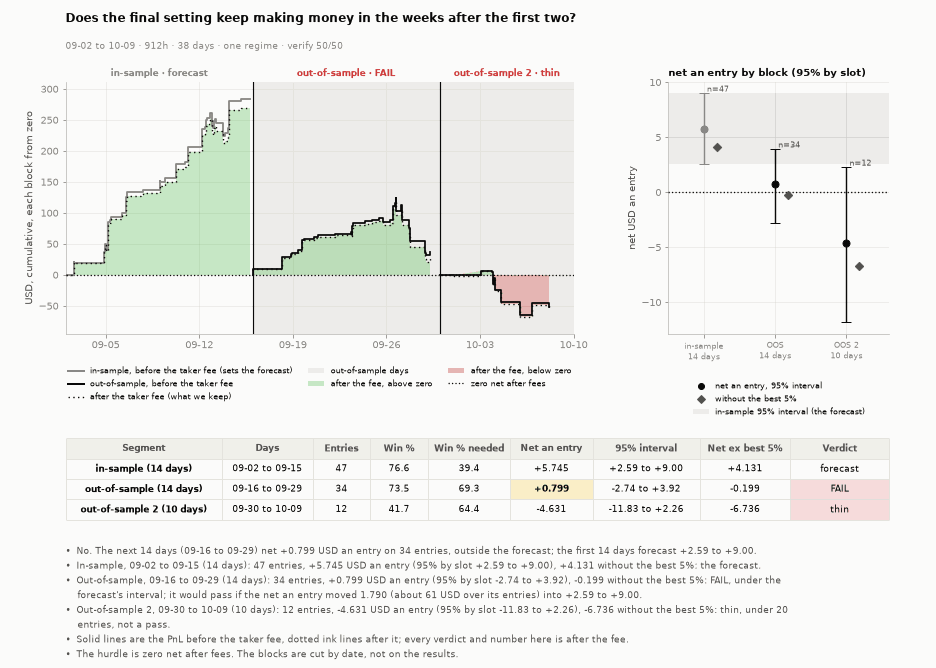

In [25]:
WIN_ = f"{DAYS[0][5:]} to {DAYS[-1][5:]} · {24 * len(DAYS):,}h · {len(DAYS)} days · one regime · verify {VERIFY_PASSED}/{VERIFY_TOTAL}"
_r = O.read_blocks(CELL_ALL, DAYS, N_IS, N_OOS)
OOS2W_CELL = _r
figstyle.show(OF.oos2w_fig(CELL_ALL, DAYS, _r, OF.block_notes(_r, O.MIN_N), "Does the final setting keep making money in the weeks after the first two?", WIN_), "fig:s4-cell-oos2w", FIGURES)

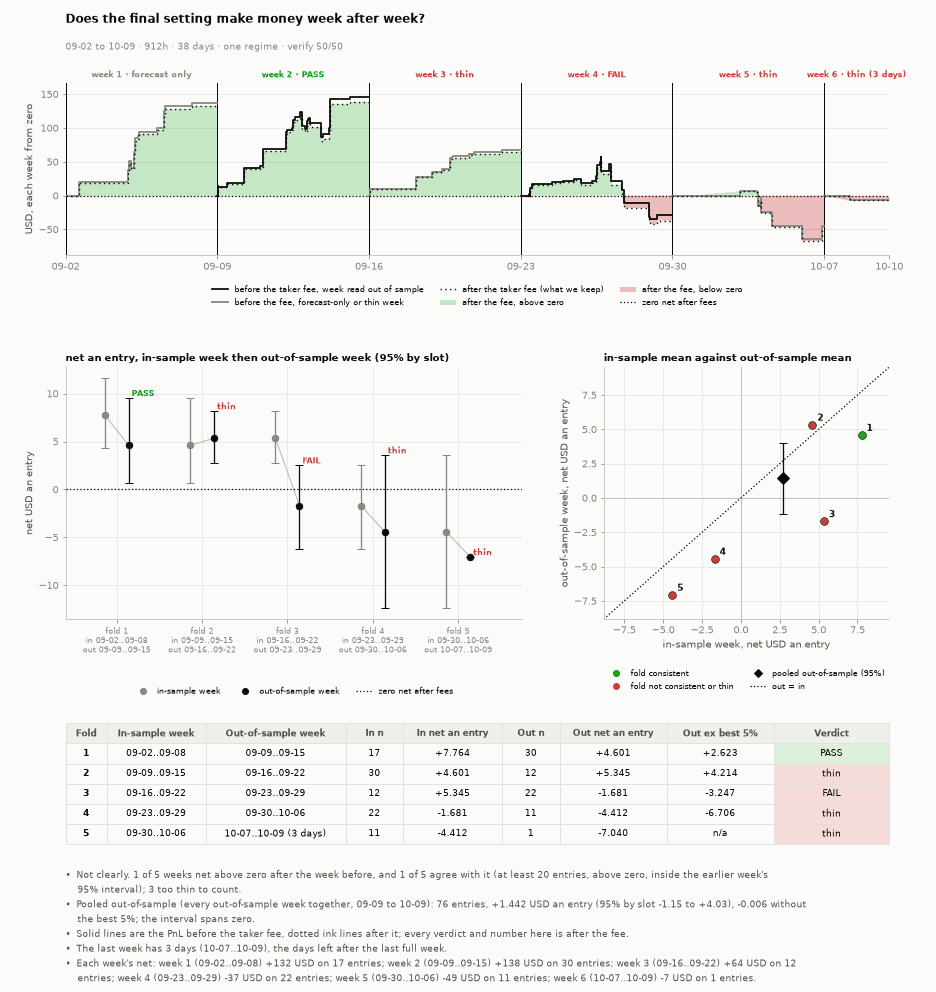

In [26]:
_f = O.read_folds(CELL_ALL, DAYS, WEEK)
FOLDS_CELL = _f
figstyle.show(OF.folds_fig(CELL_ALL, DAYS, _f, OF.fold_notes(_f, DAYS, WEEK, O.MIN_N), "Does the final setting make money week after week?", WIN_), "fig:s4-cell-oosfolds", FIGURES)

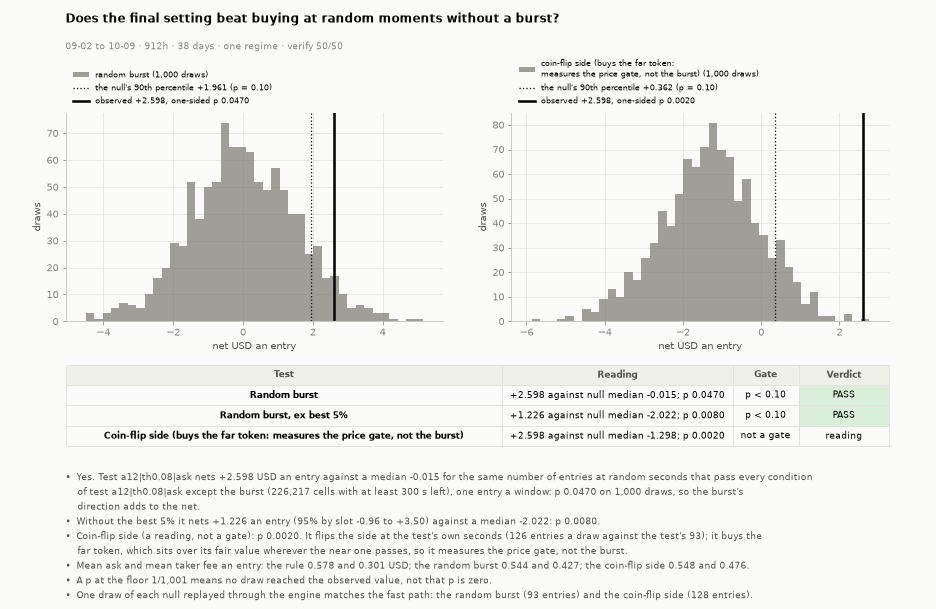

In [27]:
_s = ST.stats5(CELL_ALL)
_g, _tm, _m = CAND.gates(TAB, CFG), C.tmask(TAB, CFG["t_min"]), ST.burst_masks(TAB, CFG, feed=CAND.feed)
_rs = O.random_side(TAB, _g, _tm, usd=CLIP_USD, draws=N_DRAWS, seed=31)
_rb = O.random_burst(TAB, CELL_ALL, _m, "A", t_min=CFG["t_min"], usd=CLIP_USD, draws=N_DRAWS, seed=37)
_ok_s, _n_s = O.side_agrees(TAB, _g, _tm, usd=CLIP_USD)
_ag = O.burst_agrees(TAB, CELL_ALL, _m, "A", theta=CFG["theta"], t_min=CFG["t_min"], usd=CLIP_USD)
assert _ok_s and _ag["agree"] and not _ag["faults"], f"a randomised null disagrees with B.entries or breaks its own rules: {_ag}"
_ask = O.ask_of(TAB, CELL_ALL)
_p = dict(burst=O.p_one_sided(_rb["per"], _s["per"]), burst_ex5=O.p_one_sided(_rb["ex5"], _s["per_ex_top5"]), side=O.p_one_sided(_rs["per"], _s["per"]), side_ex5=O.p_one_sided(_rs["ex5"], _s["per_ex_top5"]))
RAND_CELL = _p
_rows, _notes = OF.burst_rows(CFG["name"], _s, _ask, _rb, _rs, _p, N_DRAWS, P_GATE, CFG["t_min"], dict(burst=_ag, side=(_ok_s, _n_s)))
if CFG["limit"] != "ask":
    _notes.append("This cell's limit is our edge price; the null buys at the ask seen, so it fills a little less than the cell would.")
_nulls = [dict(name="random burst", null=_rb["per"], observed=_s["per"], p=_p["burst"]),
          dict(name="coin-flip side (buys the far token:\nmeasures the price gate, not the burst)", null=_rs["per"], observed=_s["per"], p=_p["side"])]
figstyle.show(OF.random_fig(_nulls, _rows, _notes, "Does the final setting beat buying at random moments without a burst?", WIN_, colw=OF.BURST_COLW), "fig:s4-cell-random", FIGURES)

In [28]:
# ---- E tuned's walk-forward record against the random-burst null, each fold on its own week with its own cell (gate G7) ----
_t = time.time()
REC_BURST = ST.record_burst(TAB, WF, draws=N_DRAWS, seed=41, usd=CLIP_USD, feed=CAND.feed)
P_REC_BURST = O.p_one_sided(REC_BURST["per"], TS["per"]) if TS.get("n") else float("nan")
display(Markdown(f"**E tuned's walk-forward record against the random-burst null** ({N_DRAWS:,} draws; each fold's count of entries per day and coin at its week's seconds that pass "
                 f"every condition of its cell but the burst; {time.time() - _t:.0f}s): the null's median {sgn(float(np.nanmedian(REC_BURST['per'])), 3)} an entry, its 90th percentile "
                 f"{sgn(float(np.nanquantile(REC_BURST['per'], 0.9)), 3)}; the record {sgn(TS['per'], 3)}, one-sided p {P_REC_BURST:.4f}. Gate G7 reads this."))

**E tuned's walk-forward record against the random-burst null** (1,000 draws; each fold's count of entries per day and coin at its week's seconds that pass every condition of its cell but the burst; 6s): the null's median +0.448 an entry, its 90th percentile +1.892; the record +2.926, one-sided p 0.0190. Gate G7 reads this.

**Do we still make money each week if we drop the few best trades?** Take the best 5% of a week's entries out (set them to zero): the rest must still make money.
Each panel cumulates a week's PnL from zero, all entries and without the best 5%; a week passes when the second line ends above zero.

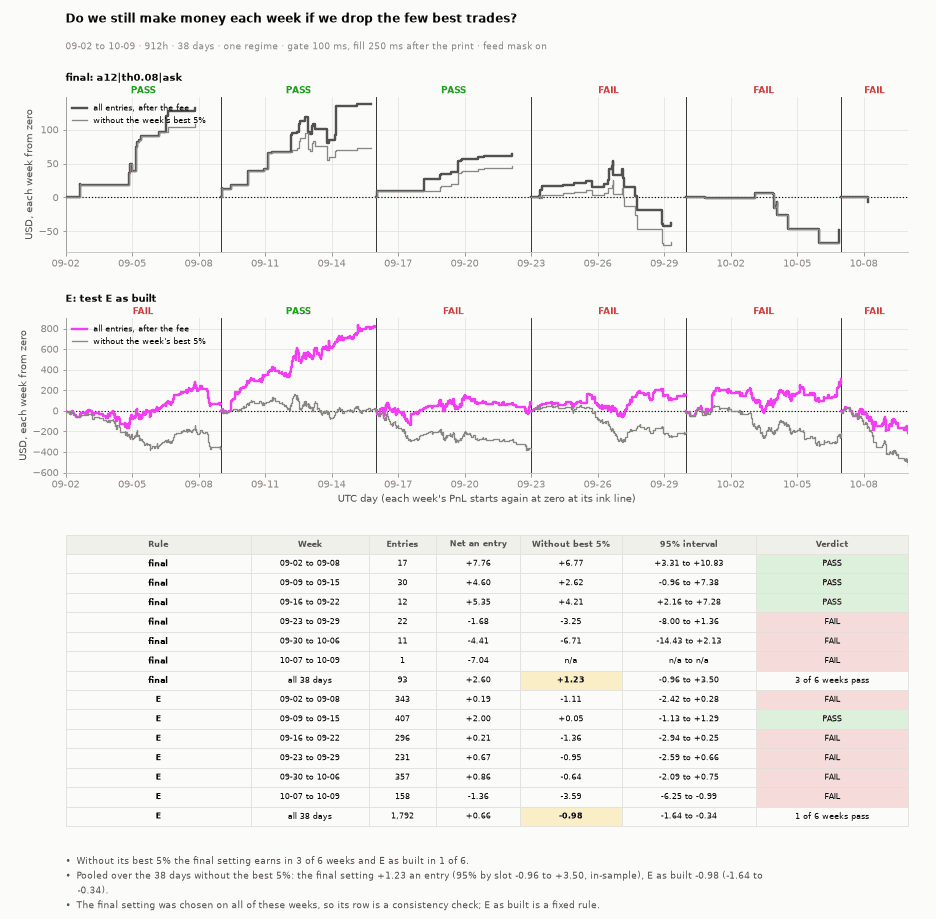

In [29]:
_r6 = {"cell": (f"final: {CFG['name']}", CELL_ALL), "E": ("E: test E as built", E_ALL)}
_wk = ST.weeks_of(len(DAYS), WEEK)
_np = {k_: sum(1 for i_ in _wk if ST.stats(ST.by_days(e_, i_)).get("n") and ST.stats(ST.by_days(e_, i_))["per_ex_top5"] > 0) for k_, (t_, e_) in _r6.items()}
_notes = [f"Without its best 5% the final setting earns in {_np['cell']} of {len(_wk)} weeks and E as built in {_np['E']} of {len(_wk)}.",
          f"Pooled over the {len(DAYS)} days without the best 5%: the final setting {sgn(S_CELL['per_ex_top5'])} an entry (95% by slot {sgn(S_CELL['per_ex_top5_lo'])} to {sgn(S_CELL['per_ex_top5_hi'])}, "
          f"in-sample), E as built {sgn(S_E['per_ex_top5'])} ({sgn(S_E['per_ex_top5_lo'])} to {sgn(S_E['per_ex_top5_hi'])}).",
          "The final setting was chosen on all of these weeks, so its row is a consistency check; E as built is a fixed rule."]
figstyle.show(ST.weekly_ex5_fig(_r6, DAYS, WEEK, WIN, _notes), "fig:s4-weekly-ex5", FIGURES)

### S4.2 · What happens when the order arrives later?

Net an entry, total and the entries a later order loses, against the delay between the decision and the ladder the order meets: tables seated at 150, 250, 500 and
1,000 ms where every day is seated at that delay, and whole seconds added to the 250 ms table (1,250 to 5,250 ms). The 250 ms is an assumption [U]. With the limit
at the ask seen, a later order loses exactly the entries whose book re-priced, which were the best ones, so the net an entry of the survivors can hold while the
dollars fall.

In [30]:
_lat_df = pd.DataFrame([dict(rule=lab_, delay_ms=r_["ms"], how=r_["how"], n=r_["s"]["n"], per=r_["s"]["per"], lo=r_["s"]["per_lo"], hi=r_["s"]["per_hi"], ex5=r_["s"]["per_ex_top5"],
                             total_usd=r_["total"], fill_share=r_["fill_share"], lost_n=r_["lost_n"], lost_net_at_250=r_["lost_per"], kept_n=r_["kept_n"], kept_net_at_250=r_["kept_per"],
                             new_n=r_["new_n"], new_net=r_["new_per"]) for lab_, (t_, rows_) in LAT.items() for r_ in rows_])
display(HTML(_lat_df.round(3).to_html(index=False, border=0)))
print(f"seated tables {LAT_SEATED}; not seated on every day: {({k_: len(v_) for k_, v_ in LAT_MISSING.items()})}")

rule,delay_ms,how,n,per,lo,hi,ex5,total_usd,fill_share,lost_n,lost_net_at_250,kept_n,kept_net_at_250,new_n,new_net
E,250,seated table,1792,0.662,-0.064,1.365,-0.984,1186.949,1.000,0,NaN,1792,0.662,0,NaN
E,1250,250 ms table + 1 s,1597,0.481,-0.270,1.227,-1.198,768.540,0.891,230,1.714,1562,0.507,35,1.861
E,2250,250 ms table + 2 s,1486,0.440,-0.391,1.300,-1.416,654.210,0.829,354,2.201,1438,0.284,48,3.483
E,3250,250 ms table + 3 s,1408,0.484,-0.406,1.423,-1.446,681.167,0.786,444,1.550,1348,0.370,60,4.983
E,5250,250 ms table + 5 s,1327,0.500,-0.446,1.473,-1.448,663.095,0.741,533,1.305,1259,0.390,68,3.106
cell,250,seated table,93,2.598,0.368,4.892,1.226,241.590,1.000,0,NaN,93,2.598,0,NaN
cell,1250,250 ms table + 1 s,52,0.486,-2.795,3.421,-0.724,25.262,0.559,43,4.051,50,1.348,2,-5.063
cell,2250,250 ms table + 2 s,41,0.359,-3.301,3.485,-0.986,14.699,0.441,54,4.389,39,0.118,2,-4.868
cell,3250,250 ms table + 3 s,39,1.737,-2.251,5.317,0.612,67.756,0.419,56,3.097,37,1.842,2,-4.865
cell,5250,250 ms table + 5 s,30,2.741,-2.298,7.777,0.554,82.244,0.323,64,2.522,29,2.765,1,-20.964


seated tables [250]; not seated on every day: {150: 38, 500: 38, 1000: 38}


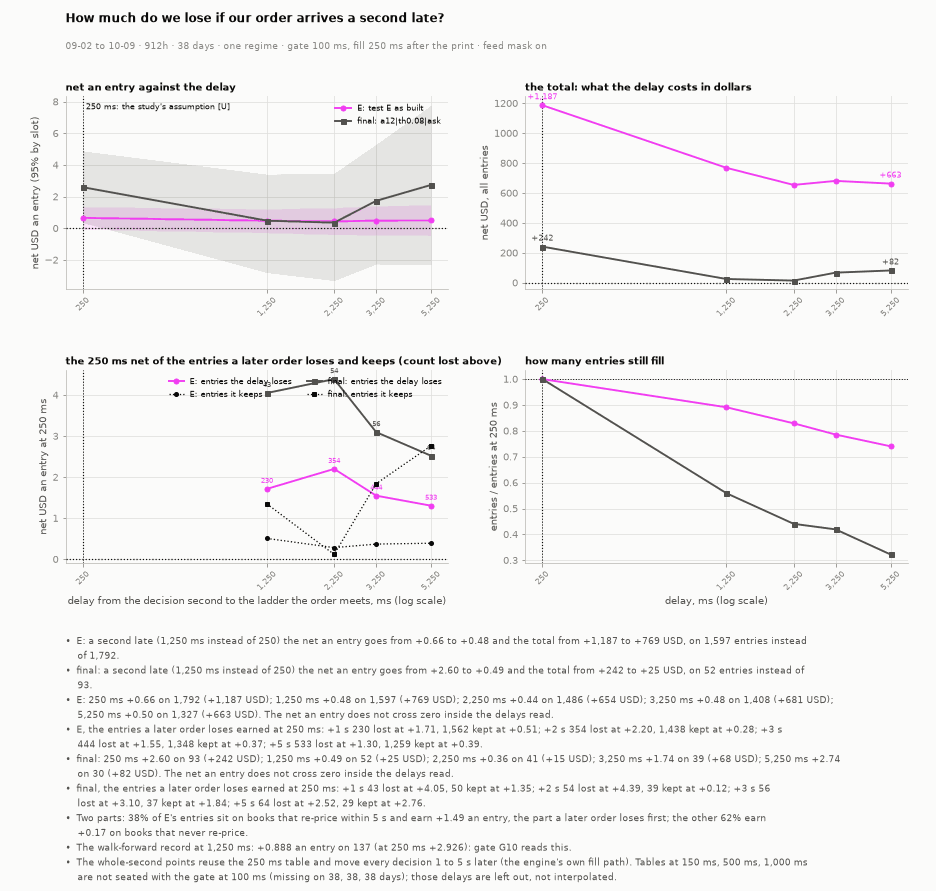

In [31]:
_notes = []
for lab_, (t_, rows_) in LAT.items():
    now_, late_ = next(r_ for r_ in rows_ if r_["ms"] == LAT_MS), next((r_ for r_ in rows_ if r_["ms"] == LAT_MS + 1000), None)
    if late_ is not None and lab_ in ("E", "cell"):
        _notes.append(f"{t_.split(':')[0]}: a second late ({late_['ms']:,} ms instead of {LAT_MS}) the net an entry goes from {sgn(now_['s']['per'])} to {sgn(late_['s']['per'])} "
                      f"and the total from {sgn(now_['total'], 0)} to {sgn(late_['total'], 0)} USD, on {late_['s']['n']:,} entries instead of {now_['s']['n']:,}.")
for lab_, (t_, rows_) in LAT.items():
    cx_ = ST.crossing(rows_)
    _notes.append(f"{t_.split(':')[0]}: " + "; ".join(f"{r_['ms']:,} ms {sgn(r_['s']['per'])} on {r_['s']['n']:,} ({sgn(r_['total'], 0)} USD)" for r_ in rows_) + ". "
                  + (f"The net an entry crosses zero near {cx_:,.0f} ms." if cx_ is not None else
                     ("The net an entry is at or below zero from the study's delay on." if rows_[0]["s"]["per"] <= 0 else "The net an entry does not cross zero inside the delays read.")))
    sp_ = [r_ for r_ in rows_ if r_["kept_n"] and r_["ms"] != LAT_MS]
    if sp_:
        _notes.append(f"{t_.split(':')[0]}, the entries a later order loses earned at {LAT_MS} ms: " + "; ".join(f"+{(r_['ms'] - LAT_MS) // 1000} s {r_['lost_n']:,} lost at {sgn(r_['lost_per'])}, {r_['kept_n']:,} kept at {sgn(r_['kept_per'])}" for r_ in sp_) + ".")
_rp = REPRICE["E"]
_n_rest = _rp["same"][0] + _rp["lower"][0]
_notes.append(f"Two parts: {_rp['higher'][0] / max(S_E['n'], 1):.0%} of E's entries sit on books that re-price within 5 s and earn {sgn(_rp['higher'][1])} an entry, the part a later order loses first; "
              f"the other {_n_rest / max(S_E['n'], 1):.0%} earn {sgn((_rp['same'][2] + _rp['lower'][2]) / max(_n_rest, 1))} on books that never re-price.")
_notes.append(f"The walk-forward record at 1,250 ms: {sgn(WF_1S['per'], 3)} an entry on {WF_1S['n']:,} (at 250 ms {sgn(TS['per'], 3)}): gate G10 reads this.")
_notes.append("The whole-second points reuse the 250 ms table and move every decision 1 to 5 s later (the engine's own fill path). "
              + (f"Tables at 500 and 1,000 ms were seated for all {len(DAYS)} days and are read directly; their entries are not matched to the 250 ms entries."
                 if not LAT_MISSING else f"Tables at {', '.join(f'{k_:,} ms' for k_ in sorted(LAT_MISSING))} are not seated with the gate at {DECIDE_MS} ms (missing on {', '.join(str(len(v_)) for _, v_ in sorted(LAT_MISSING.items()))} days); those delays are left out, not interpolated."))
figstyle.show(ST.latency_fig(LAT, WIN, _notes, LAT_MS), "fig:s4-latency", FIGURES)

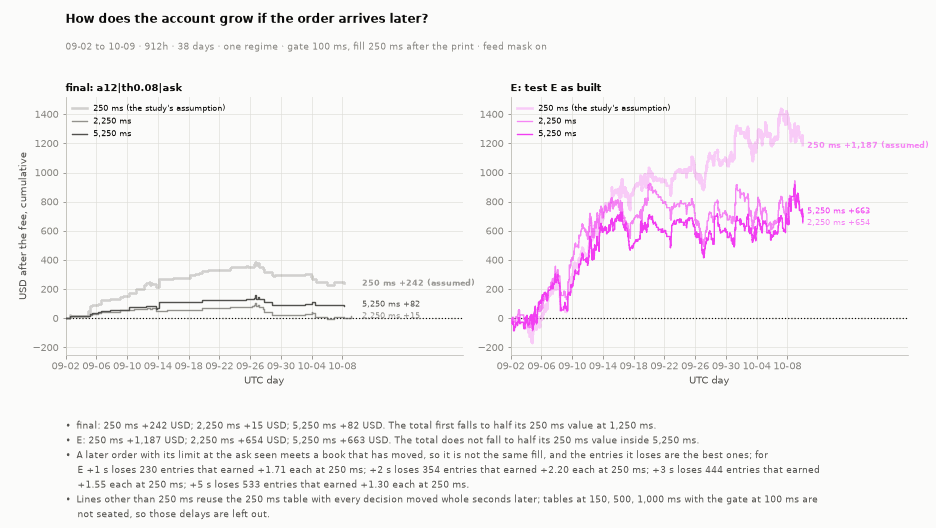

In [32]:
# ---- the same delays as paths over the days: the account after the fee at each delay, the final cell beside E as built ----
_show = (150, 250, 500, 1000, 2250, 5250)
_pan = {k_: (LAT[k_][0], [(f"{ms_:,} ms", DELAY_E[k_][ms_], ms_ == LAT_MS) for ms_ in _show if ms_ in DELAY_E[k_]]) for k_ in ("cell", "E")}
_notes = []
for k_ in ("cell", "E"):
    pts_ = [(ms_, float(np.sum(DELAY_E[k_][ms_]["net"])), ms_ == LAT_MS) for ms_ in DELAY_E[k_]]
    h_ = ST.halving(pts_)
    _notes.append(f"{LAT[k_][0].split(':')[0]}: " + "; ".join(f"{ms_:,} ms {sgn(v_, 0)} USD" for ms_, v_, b_ in pts_ if ms_ in _show) + ". "
                  + (f"The total first falls to half its {LAT_MS} ms value at {h_:,} ms." if h_ else f"The total does not fall to half its {LAT_MS} ms value inside {max(DELAY_E[k_]):,} ms."))
_sp = [r_ for r_ in LAT["E"][1] if r_["kept_n"] and r_["ms"] != LAT_MS]
_notes.append("A later order with its limit at the ask seen meets a book that has moved, so it is not the same fill, and the "
              "entries it loses are the best ones; for E " + "; ".join(f"+{(r_['ms'] - LAT_MS) // 1000} s loses {r_['lost_n']:,} entries that earned {sgn(r_['lost_per'])} each at {LAT_MS} ms" for r_ in _sp) + ".")
_notes.append(f"Lines other than {LAT_MS} ms reuse the {LAT_MS} ms table with every decision moved whole seconds later"
              + (f"; tables at {', '.join(f'{m_:,}' for m_ in sorted(LAT_MISSING))} ms with the gate at {DECIDE_MS} ms are not seated, so those delays are left out." if LAT_MISSING else "; the other lines are tables seated at their delays."))
figstyle.show(ST.paths_fig(_pan, DAYS, WIN, _notes, "How does the account grow if the order arrives later?"), "fig:s4-delay-paths", FIGURES)

### S4.3 · How much do we keep after the taker fee?

Every net is after the taker fee (`rate x p x (1 - p)` a share, each market's own rate). The sweep runs the fee from none to three times its rate on the same
entries, and raises the limit one and two cents over the cell's own.

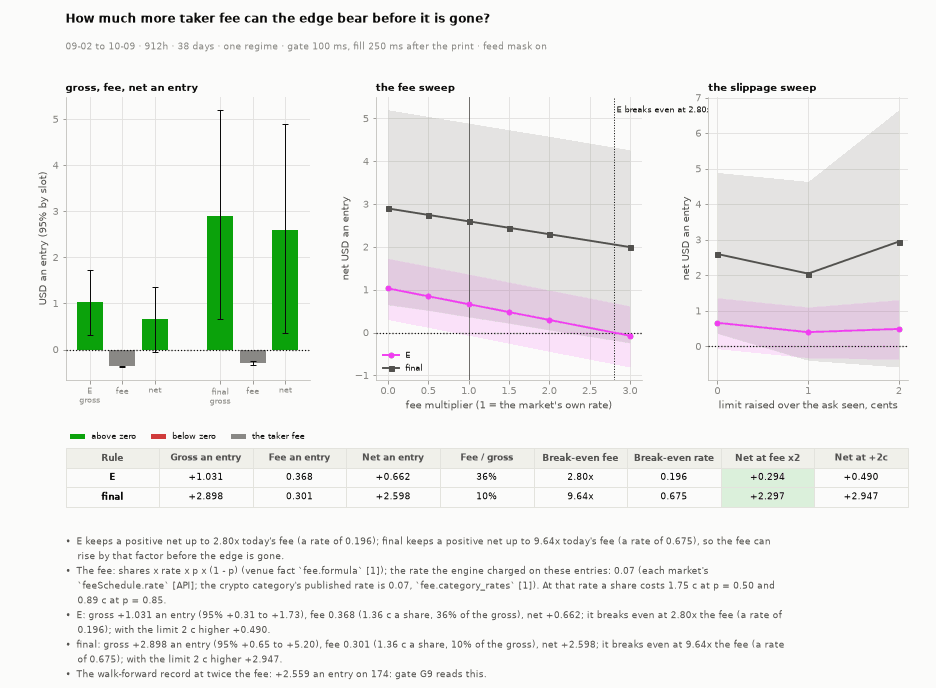

In [33]:
_c = COSTS["E"][1]
_rate = _c["rates"]
_notes = ["; ".join(f"{t_.split(':')[0]} keeps a positive net up to {c_['be_mult']:.2f}x today's fee" + (f" (a rate of {c_['be_mult'] * c_['rates'][0]:.3f})" if len(c_["rates"]) == 1 else "") for t_, c_ in COSTS.values())
          + ", so the fee can rise by that factor before the edge is gone.",
          f"The fee: shares x rate x p x (1 - p) (venue fact `fee.formula` [1]); the rate the engine charged on these entries: {', '.join(f'{r_:g}' for r_ in _rate)} (each market's `feeSchedule.rate` [API]; the crypto category's published rate is 0.07, `fee.category_rates` [1]). "
          + (f"At that rate a share costs {_rate[0] * 0.25 * 100:.2f} c at p = 0.50 and {_rate[0] * 0.85 * 0.15 * 100:.2f} c at p = 0.85." if len(_rate) == 1 else "")]
for lab_, (t_, c_) in COSTS.items():
    _notes.append(f"{t_.split(':')[0]}: gross {sgn(c_['gross'], 3)} an entry (95% {sgn(c_['gross_lo'])} to {sgn(c_['gross_hi'])}), fee {c_['fee_per']:.3f} ({c_['fee_per'] / c_['shares'] * 100:.2f} c a share, "
                  f"{c_['fee_per'] / c_['gross'] * 100 if c_['gross'] > 0 else float('nan'):.0f}% of the gross), net {sgn(c_['net'], 3)}; it breaks even at {c_['be_mult']:.2f}x the fee"
                  + (f" (a rate of {c_['be_mult'] * c_['rates'][0]:.3f})" if len(c_["rates"]) == 1 else "") + f"; with the limit 2 c higher {sgn(dict(c_['slip'])[0.02]['per'], 3)}.")
_notes.append(f"The walk-forward record at twice the fee: {sgn(WF_FEE2['per'], 3)} an entry on {WF_FEE2['n']:,}: gate G9 reads this.")
figstyle.show(ST.cost_fig(COSTS, WIN, _notes), "fig:s4-costs", FIGURES)

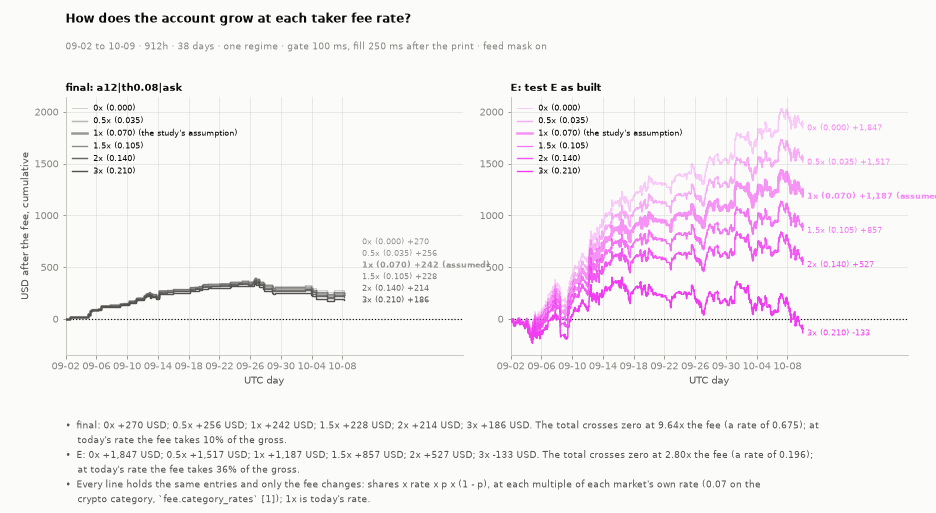

In [34]:
# ---- the same fee sweep as paths over the days: the account after the fee at each multiple of the rate, the final cell beside E as built ----
FEE_E = {k_: ST.fee_entries(CAND, TAB, cfg_, FEE_MULTS) for k_, cfg_ in (("cell", CFG), ("E", CFG_E))}
_r0 = float(COSTS["E"][1]["rates"][0]) if len(COSTS["E"][1]["rates"]) == 1 else 0.07
_pan = {k_: (COSTS[k_][0], [(f"{m_:g}x ({m_ * _r0:.3f})", FEE_E[k_][m_], m_ == 1.0) for m_ in FEE_MULTS]) for k_ in ("cell", "E")}
_notes = []
for k_ in ("cell", "E"):
    c_ = COSTS[k_][1]
    _notes.append(f"{COSTS[k_][0].split(':')[0]}: " + "; ".join(f"{m_:g}x {sgn(float(np.sum(FEE_E[k_][m_]['net'])), 0)} USD" for m_ in FEE_MULTS)
                  + f". The total crosses zero at {c_['be_mult']:.2f}x the fee (a rate of {c_['be_mult'] * _r0:.3f})"
                  + (f"; at today's rate the fee takes {c_['fee_per'] / c_['gross']:.0%} of the gross." if c_["gross"] > 0 else "; the gross is not positive."))
_notes.append(f"Every line holds the same entries and only the fee changes: shares x rate x p x (1 - p), at each multiple of each market's own rate ({_r0:g} on the crypto category, `fee.category_rates` [1]); 1x is today's rate.")
figstyle.show(ST.paths_fig(_pan, DAYS, WIN, _notes, "How does the account grow at each taker fee rate?"), "fig:s4-fee-paths", FIGURES)

### S4.4 · Does the edge hold in every group of trades?

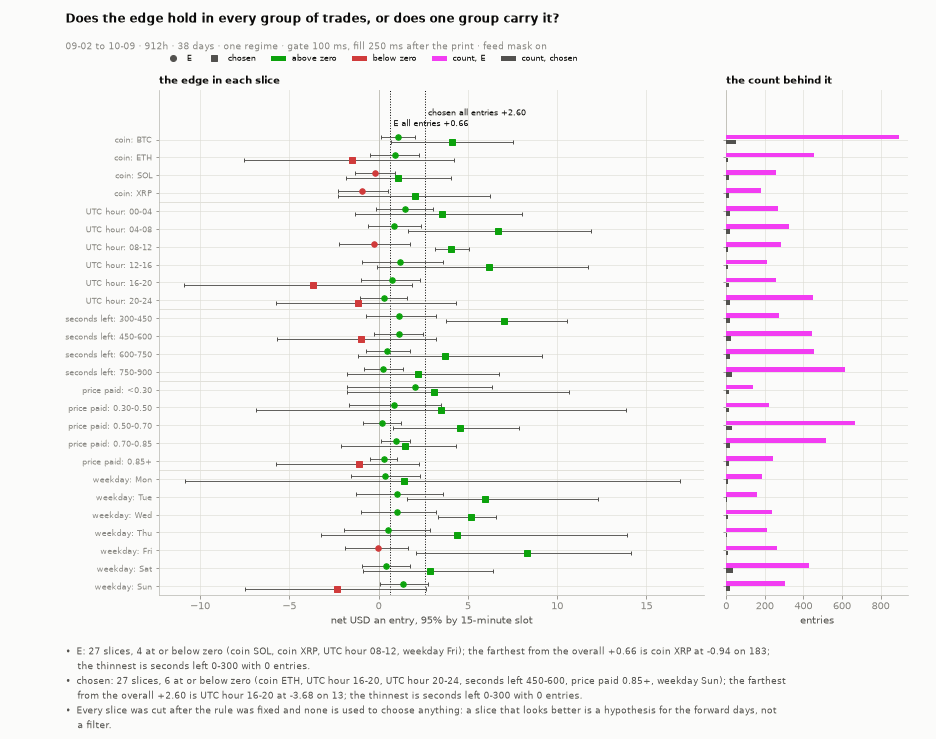

In [35]:
SL = {"E": ("E: test E as built", ST.slices(E_ALL, TAB, DAYS)), "cell": (f"chosen: {CFG['name']}", ST.slices(CELL_ALL, TAB, DAYS))}
_ov = {"E": S_E["per"], "cell": S_CELL["per"]}
_notes = []
for lab_, (t_, rows_) in SL.items():
    neg_ = [f"{d_} {l_}" for d_, l_, v_, lo_, hi_, n_ in rows_ if v_ <= 0]
    thin_ = min(rows_, key=lambda r_: r_[5])
    far_ = max(rows_, key=lambda r_: abs(r_[2] - _ov[lab_]) if np.isfinite(r_[2]) else -1)
    _notes.append(f"{t_.split(':')[0]}: {len(rows_)} slices, {len(neg_)} at or below zero" + (f" ({', '.join(neg_)})" if neg_ else "") + f"; the farthest from the overall {_ov[lab_]:+.2f} is {far_[0]} {far_[1]} at {far_[2]:+.2f} on {far_[5]:,}; the thinnest is {thin_[0]} {thin_[1]} with {thin_[5]:,} entries.")
_notes.append("Every slice was cut after the rule was fixed and none is used to choose anything: a slice that looks better is a hypothesis for the forward days, not a filter.")
figstyle.show(ST.slices_fig(SL, _ov, WIN, _notes), "fig:s4-slices", FIGURES)

### S4.5 · Does the account climb steadily or in jumps?

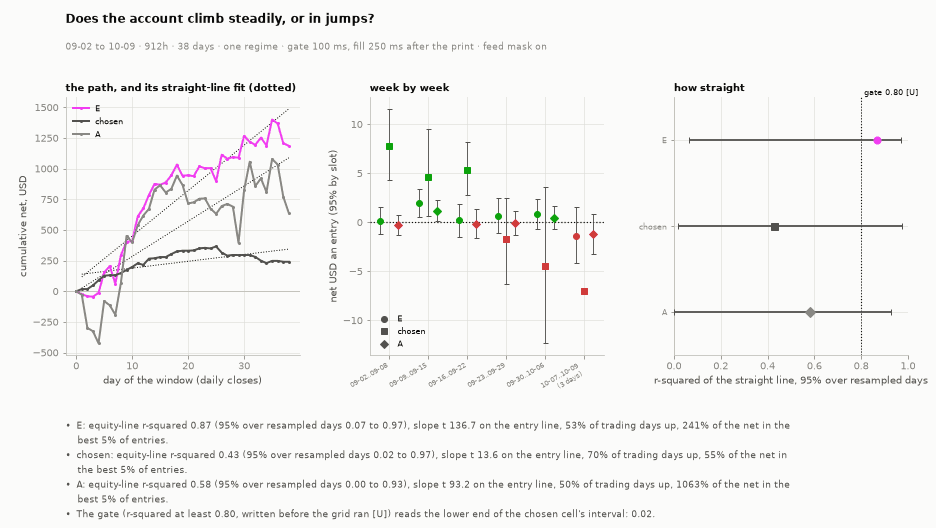

In [36]:
STEADY = {k_: (t_, e_) for k_, t_, e_ in (("E", "E: test E as built", E_ALL), ("cell", f"chosen: {CFG['name']}", CELL_ALL), ("A", "A: rule A", A_ALL))}
_nd = len(DAYS)
R2 = {k_: (ST.r2_line(ST.daily(e_, _nd)), *ST.r2_ci(ST.daily(e_, _nd))) for k_, (t_, e_) in STEADY.items()}
_notes = []
for k_, (t_, e_) in STEADY.items():
    s_ = B.summarize(e_, TAB, k_) if len(e_["net"]) else dict(n=0)
    _notes.append(f"{t_.split(':')[0]}: equity-line r-squared {R2[k_][0]:.2f} (95% over resampled days {R2[k_][1]:.2f} to {R2[k_][2]:.2f}), slope t {s_.get('eq_slope_t', float('nan')):.1f} on the entry line, "
                  f"{s_.get('days_pos', float('nan')):.0%} of trading days up, " + (f"{s_['top5_share'] * 100:.0f}% of the net in the best 5% of entries." if np.isfinite(s_.get('top5_share', float('nan'))) else "a net at or below zero, so no share in the best 5%."))
_notes.append(f"The gate (r-squared at least {R2_MIN:.2f}, written before the grid ran [U]) reads the lower end of the chosen cell's interval: {R2['cell'][1]:.2f}.")
figstyle.show(ST.steady_fig(STEADY, DAYS, R2_MIN, WIN, _notes), "fig:s4-steady", FIGURES)

### S4.6 · Does selling early beat holding to expiry?

Holding to expiry against a sale at the near bid after 60, 120 and 300 seconds and a take-profit at 0.95, on the same entries.

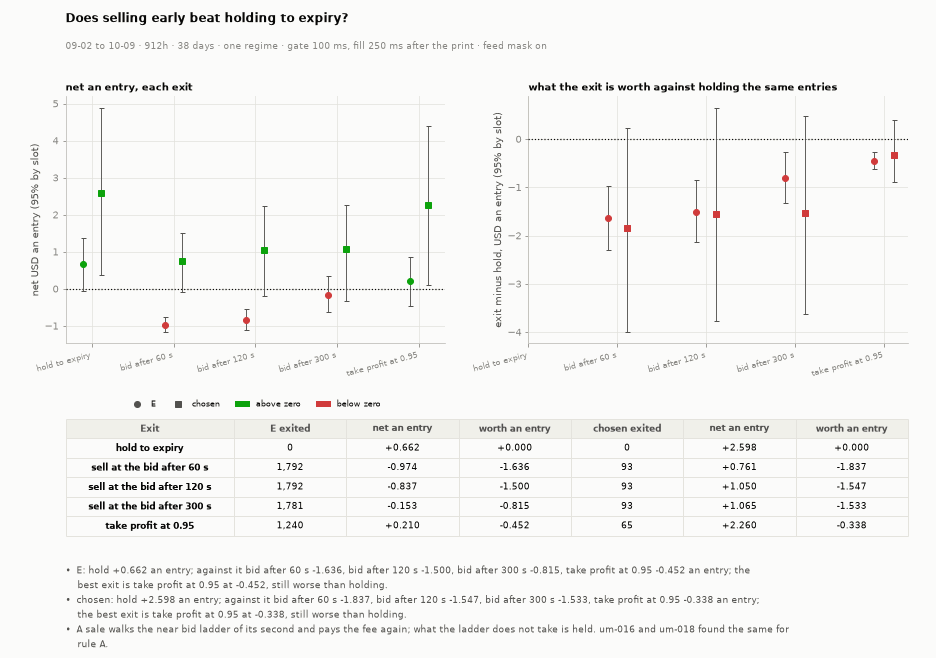

In [37]:
EXITS = {"E": ("E: test E as built", ST.exit_variants(TAB, E_ALL)), "cell": (f"chosen: {CFG['name']}", ST.exit_variants(TAB, CELL_ALL))}
_notes = []
for lab_, (t_, v_) in EXITS.items():
    base_ = v_["hold to expiry"]
    w_ = {nm_: float(np.mean(np.asarray(x_["net"]) - np.asarray(base_["net"]))) for nm_, x_ in v_.items() if nm_ != "hold to expiry"}
    best_ = max(w_, key=w_.get)
    _notes.append(f"{t_.split(':')[0]}: hold {sgn(ST.stats(base_)['per'], 3)} an entry; against it " + ", ".join(f"{nm_.replace('sell at the bid after', 'bid after')} {v2_:+.3f}" for nm_, v2_ in w_.items())
                  + f" an entry; the best exit is {best_} at {w_[best_]:+.3f}" + (" and it beats holding." if w_[best_] > 0 else ", still worse than holding."))
_notes.append("A sale walks the near bid ladder of its second and pays the fee again; what the ladder does not take is held. um-016 and um-018 found the same for rule A.")
figstyle.show(ST.exits_fig(EXITS, WIN, _notes), "fig:s4-exits", FIGURES)

### S4.7 · Does paying at most 50 cents a share help?

A binary bought at p wins 1 - p and loses p, so at 0.50 or under every trade risks no more than it can win; the cap removes the entries that lose a whole dollar
to win half of one. It applies to the ask seen at the decision second (the order's limit) and is confirmed on the fill; 0.60 is read as a softer cut. Both rules
use the engine's fair value. The capped rule is then read week by week, in two-week blocks, and against the random-burst null with the cap applied to the draws.

In [38]:
_t = time.time()
E4 = {}
for k_, lab_, cap_ in (("E", "E as built", None), ("cap50", "E paying at most 0.50", 0.50), ("cap60", "E paying at most 0.60", 0.60)):
    e_, g_, m_ = ST.e_variant(TAB, CFG_E, cap=cap_, feed=CAND.feed)
    E4[k_] = dict(label=lab_, e=e_, gates=g_, masks=m_, cap=cap_)
assert _same(E4["E"]["e"], E_ALL), "E rebuilt through e_variant is not E"
_hf = lambda e_, h_: ST.stats(B.subset(e_, (np.asarray(e_["day"]) < HALF) if h_ == 0 else (np.asarray(e_["day"]) >= HALF)))
_wk6 = ST.weeks_of(len(DAYS), WEEK)
_rows = []
for k_, r_ in E4.items():
    e_ = r_["e"]
    s_ = ST.stats5(e_)
    r_["s"] = s_
    _d = ST.daily(e_, len(DAYS))
    _nd = ST.daily(dict(day=e_["day"], net=np.ones(len(e_["net"]))), len(DAYS))
    r_["weeks_pass"] = sum(1 for i_ in _wk6 if ST.stats(ST.by_days(e_, i_)).get("n") and ST.stats(ST.by_days(e_, i_))["per_ex_top5"] > 0)
    _rows.append(dict(rule=r_["label"], entries=s_.get("n", 0), win_pct=s_.get("win", np.nan) * 100, win_needed_pct=s_.get("win_needed", np.nan) * 100,
                      net_per_entry=f"{sgn(s_.get('per'))} ({sgn(s_.get('per_lo'))} to {sgn(s_.get('per_hi'))})",
                      without_best5=f"{sgn(s_.get('per_ex_top5'))} ({sgn(s_.get('per_ex_top5_lo'))} to {sgn(s_.get('per_ex_top5_hi'))})",
                      days_up=f"{int((_d > 0).sum())} of {int((_nd > 0).sum())}", first_half=sgn(_hf(e_, 0).get("per")), second_half=sgn(_hf(e_, 1).get("per")),
                      weeks_pass=f"{r_['weeks_pass']} of {len(_wk6)}", **{a_: sgn(ST.stats(B.subset(e_, np.asarray(e_["asset"]) == i_)).get("per")) for i_, a_ in enumerate(ASSET)},
                      highest_fill=float(np.max(e_["vwap"])) if len(e_["net"]) else np.nan))
E4_DF = pd.DataFrame(_rows)
display(Markdown(f"**E and the price cap on every seated day** (net an entry and the net without the best 5% with their 95% slot intervals; days up of the days with an entry; "
                 f"halves split at {DAYS[HALF][5:]}; the coins' net an entry; the highest price any fill paid; {time.time() - _t:.0f}s)"))
display(HTML(E4_DF.round(2).to_html(index=False, border=0)))

**E and the price cap on every seated day** (net an entry and the net without the best 5% with their 95% slot intervals; days up of the days with an entry; halves split at 09-21; the coins' net an entry; the highest price any fill paid; 2s)

rule,entries,win_pct,win_needed_pct,net_per_entry,without_best5,days_up,first_half,second_half,weeks_pass,btc,eth,sol,xrp,highest_fill
E as built,1792,67.63,64.75,+0.66 (-0.06 to +1.36),-0.98 (-1.64 to -0.34),20 of 38,+0.93,+0.32,1 of 6,+1.10,+0.92,-0.19,-0.94,0.94
E paying at most 0.50,405,34.57,32.61,+0.69 (-1.39 to +2.82),-2.38 (-4.20 to -0.42),19 of 38,+1.62,-0.50,1 of 6,+2.44,+2.87,-1.79,-2.44,0.50
E paying at most 0.60,651,44.55,42.79,+0.53 (-1.06 to +2.08),-1.98 (-3.39 to -0.51),21 of 38,+1.06,-0.19,1 of 6,+1.60,+1.44,-0.95,-1.59,0.60


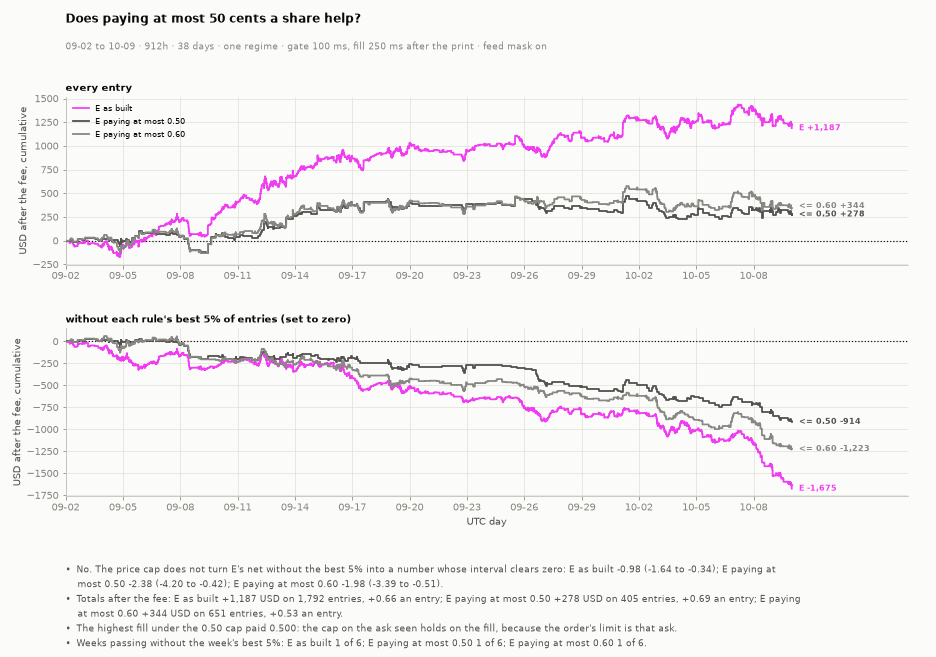

In [39]:
_c4 = {"E": figstyle.IDENTITY["MODEL"], "cap50": ST.INK2, "cap60": ST.MUTED}
_lines = [(E4[k_]["label"], {"E": "E", "cap50": "<= 0.50", "cap60": "<= 0.60"}[k_], E4[k_]["e"], _c4[k_]) for k_ in ("E", "cap50", "cap60")]
_s = {k_: E4[k_]["s"] for k_ in E4}
_turn = [k_ for k_ in ("cap50", "cap60") if _s[k_].get("per_ex_top5_lo", -1) > 0]
_notes = [("Yes: " + "; ".join(f"{E4[k_]['label']} lifts the net without the best 5% to {sgn(_s[k_]['per_ex_top5'])} with its interval clear of zero" for k_ in _turn) + "."
                       if _turn else "No. The price cap does not turn E's net without the best 5% into a number whose interval clears zero: "
                       + "; ".join(f"{E4[k_]['label']} {sgn(_s[k_]['per_ex_top5'])} ({sgn(_s[k_]['per_ex_top5_lo'])} to {sgn(_s[k_]['per_ex_top5_hi'])})" for k_ in ("E", "cap50", "cap60")) + "."),
          "Totals after the fee: " + "; ".join(f"{E4[k_]['label']} {sgn(_s[k_].get('net', 0.0), 0)} USD on {_s[k_].get('n', 0):,} entries, {sgn(_s[k_].get('per'))} an entry" for k_ in ("E", "cap50", "cap60")) + ".",
          f"The highest fill under the 0.50 cap paid {E4_DF.set_index('rule').loc[E4['cap50']['label'], 'highest_fill']:.3f}: the cap on the ask seen holds on the fill, because the order's limit is that ask.",
          "Weeks passing without the week's best 5%: " + "; ".join(f"{E4[k_]['label']} {E4[k_]['weeks_pass']} of {len(_wk6)}" for k_ in ("E", "cap50", "cap60")) + "."]
figstyle.show(ST.gate_paths_fig(_lines, DAYS, WIN, _notes, question="Does paying at most 50 cents a share help?"), "fig:s4-gates-paths", FIGURES)

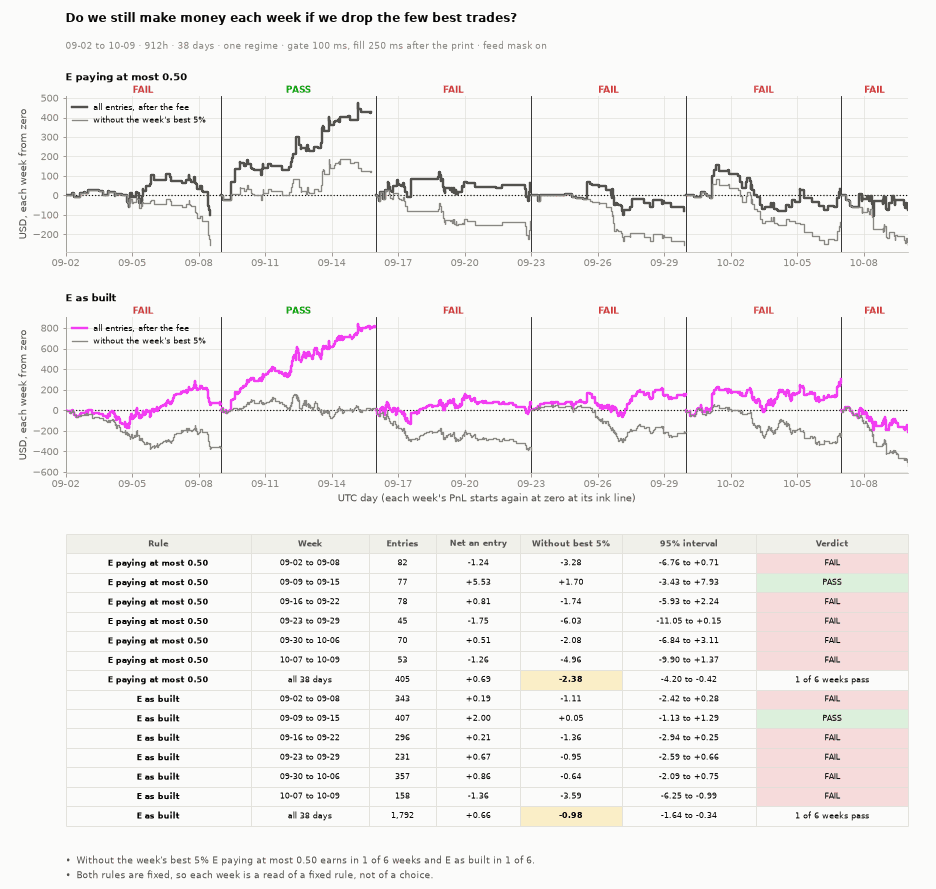

In [40]:
_r = {k_: (f"{E4[k_]['label']}", E4[k_]["e"]) for k_ in ("cap50", "E")}
_notes = [f"Without the week's best 5% {E4['cap50']['label']} earns in {E4['cap50']['weeks_pass']} of {len(_wk6)} weeks and E as built in {E4['E']['weeks_pass']} of {len(_wk6)}.",
          "Both rules are fixed, so each week is a read of a fixed rule, not of a choice."]
figstyle.show(ST.weekly_ex5_fig(_r, DAYS, WEEK, WIN, _notes, cols={"cap50": ST.INK2, "E": figstyle.IDENTITY["MODEL"]}), "fig:s4-gates-weekly", FIGURES)

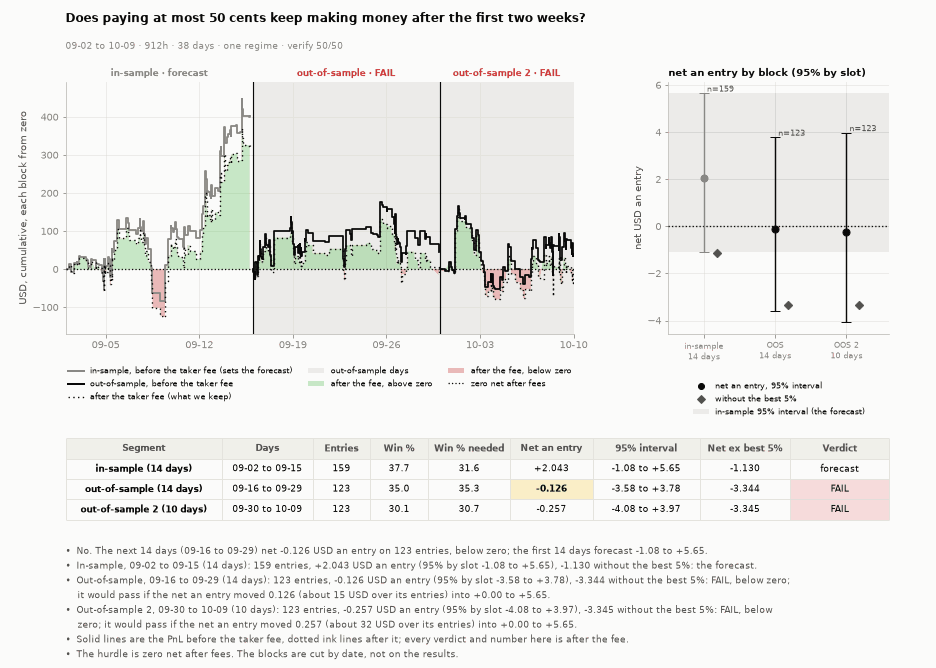

In [41]:
_b = E4["cap50"]
WIN_ = f"{DAYS[0][5:]} to {DAYS[-1][5:]} · {24 * len(DAYS):,}h · {len(DAYS)} days · one regime · verify {VERIFY_PASSED}/{VERIFY_TOTAL}"
OOS2W_B4 = O.read_blocks(_b["e"], DAYS, N_IS, N_OOS)
figstyle.show(OF.oos2w_fig(_b["e"], DAYS, OOS2W_B4, OF.block_notes(OOS2W_B4, O.MIN_N), "Does paying at most 50 cents keep making money after the first two weeks?", WIN_), "fig:s4-gates-oos2w", FIGURES)

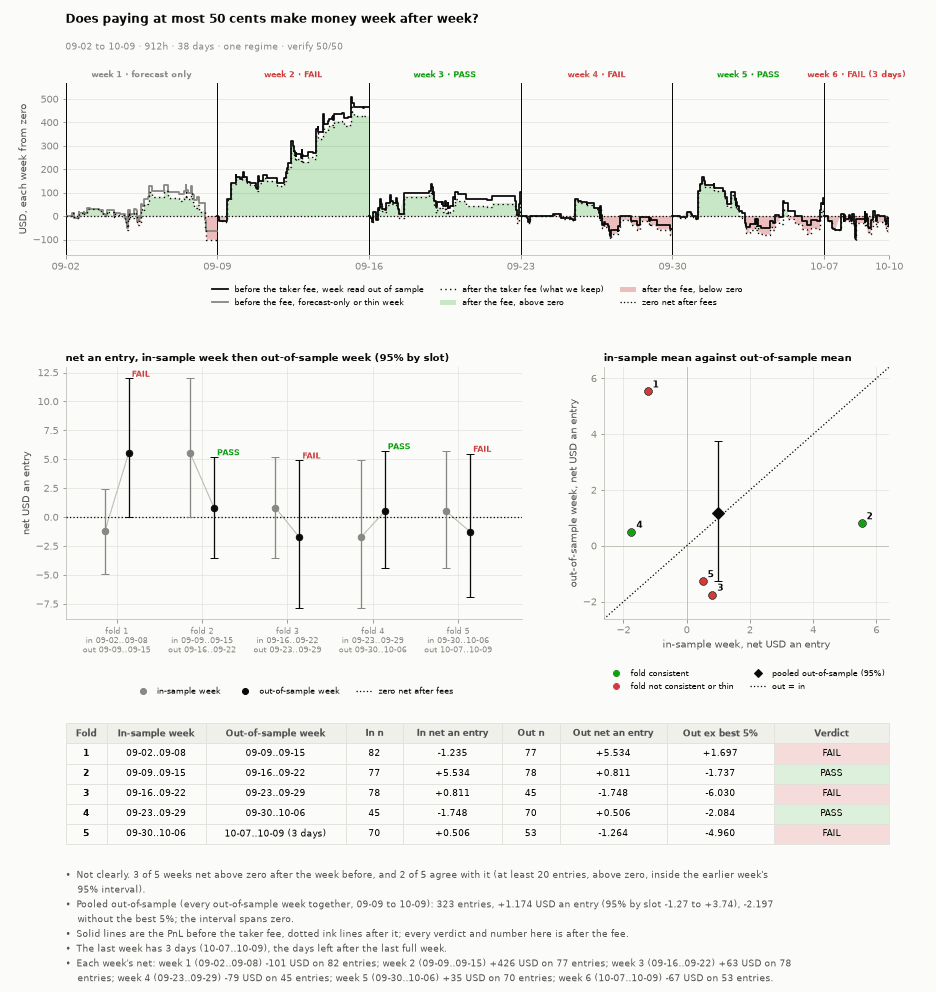

In [42]:
FOLDS_B4 = O.read_folds(_b["e"], DAYS, WEEK)
figstyle.show(OF.folds_fig(_b["e"], DAYS, FOLDS_B4, OF.fold_notes(FOLDS_B4, DAYS, WEEK, O.MIN_N), "Does paying at most 50 cents make money week after week?", WIN_),
              "fig:s4-gates-folds", FIGURES)

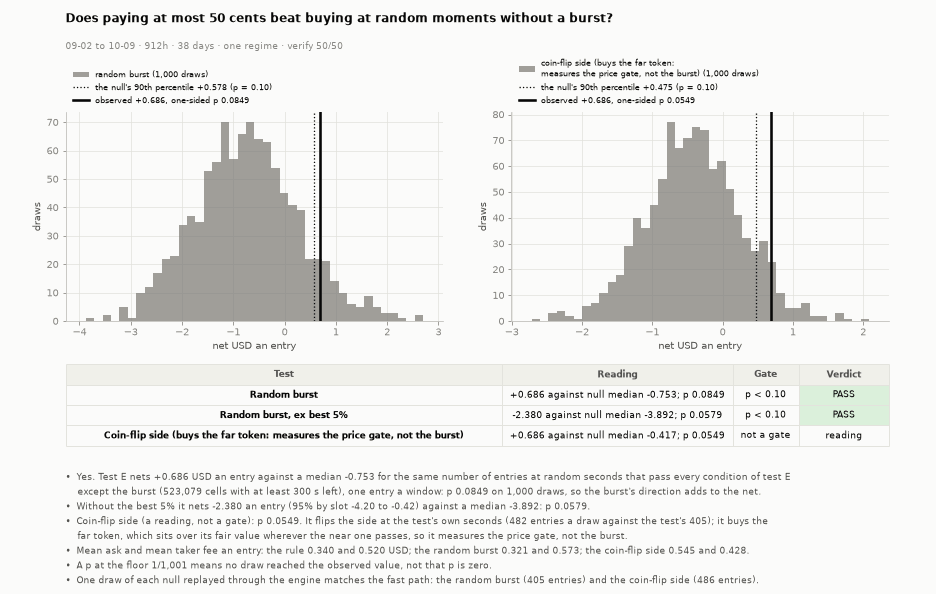

**Gates on E paying at most 0.50 a share, read beside the decision and not part of the final cell's sizing:** G17 Cap 0.50: ex-5% clears 0: -2.380 (-4.20 to -0.42) on 405 entries, FAIL; G18 Cap 0.50: 4 of 6 weeks: 1 of 6 weeks, FAIL; random-burst p 0.0849.

In [43]:
# the random-burst null with the price cap in its pool, so the draws pass what the rule passes
_s = ST.stats5(_b["e"])
_tm = C.tmask(TAB, CFG_E["t_min"])
_rs = O.random_side(TAB, _b["gates"], _tm, usd=CLIP_USD, draws=N_DRAWS, seed=53)
_rb = O.random_burst(TAB, _b["e"], _b["masks"], "A", t_min=CFG_E["t_min"], usd=CLIP_USD, draws=N_DRAWS, seed=59)
_ok_s, _n_s = O.side_agrees(TAB, _b["gates"], _tm, usd=CLIP_USD)
_ag = O.burst_agrees(TAB, _b["e"], _b["masks"], "A", theta=CFG_E["theta"], t_min=CFG_E["t_min"], usd=CLIP_USD)
assert _ok_s and _ag["agree"] and not _ag["faults"], f"a randomised null disagrees with B.entries or breaks its own rules: {_ag}"
_p = dict(burst=O.p_one_sided(_rb["per"], _s["per"]), burst_ex5=O.p_one_sided(_rb["ex5"], _s["per_ex_top5"]), side=O.p_one_sided(_rs["per"], _s["per"]), side_ex5=O.p_one_sided(_rs["ex5"], _s["per_ex_top5"]))
RAND_B4 = _p
_rows, _notes = OF.burst_rows("E", _s, O.ask_of(TAB, _b["e"]), _rb, _rs, _p, N_DRAWS, P_GATE, CFG_E["t_min"], dict(burst=_ag, side=(_ok_s, _n_s)))
_nulls = [dict(name="random burst", null=_rb["per"], observed=_s["per"], p=_p["burst"]),
          dict(name="coin-flip side (buys the far token:\nmeasures the price gate, not the burst)", null=_rs["per"], observed=_s["per"], p=_p["side"])]
figstyle.show(OF.random_fig(_nulls, _rows, _notes, "Does paying at most 50 cents beat buying at random moments without a burst?", WIN_, colw=OF.BURST_COLW),
              "fig:s4-gates-random", FIGURES)
_bs = _b["s"]
GATES_E4 = [{"id": "G17", "section": "S4", "label": "Cap 0.50: ex-5% clears 0", "name": "Does E paying at most 0.50 a share earn without its best 5% of entries on every seated day, the 95% slot interval of that number above zero?",
             "reading": f"{sgn(_bs['per_ex_top5'], 3)} ({sgn(_bs['per_ex_top5_lo'])} to {sgn(_bs['per_ex_top5_hi'])}) on {_bs['n']:,} entries", "verdict": "PASS" if _bs["per_ex_top5_lo"] > 0 else "FAIL",
             "would_change": "an interval that reaches zero"},
            {"id": "G18", "section": "S4", "label": "Cap 0.50: 4 of 6 weeks", "name": f"Does E paying at most 0.50 a share earn without each week's best 5% of entries in at least 4 of the {len(_wk6)} weeks?",
             "reading": f"{_b['weeks_pass']} of {len(_wk6)} weeks", "verdict": "PASS" if _b["weeks_pass"] >= 4 else "FAIL", "would_change": "fewer than 4 weeks"}]
display(Markdown("**Gates on E paying at most 0.50 a share, read beside the decision and not part of the final cell's sizing:** "
                 + "; ".join(f"{g_['id']} {g_['label']}: {g_['reading']}, {g_['verdict']}" for g_ in GATES_E4) + f"; random-burst p {_p['burst']:.4f}."))

## S5 · Risk and diagnostics - How far can the account fall?

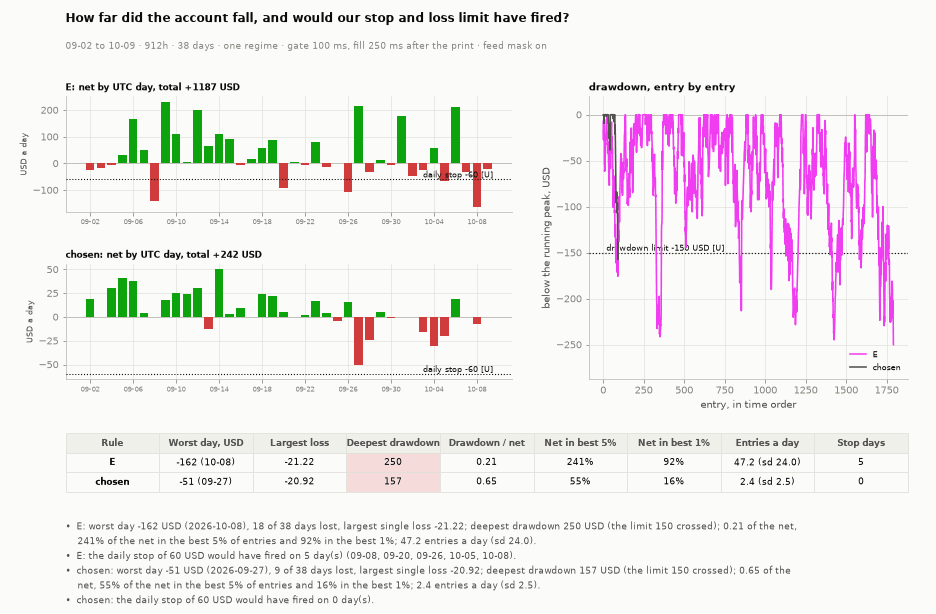

In [44]:
RISK = {"E": ("E: test E as built", ST.risk_read(E_ALL, len(DAYS), BOOK_USD, STOP_DAY_USD, DD_LIMIT_USD)), "cell": (f"chosen: {CFG['name']}", ST.risk_read(CELL_ALL, len(DAYS), BOOK_USD, STOP_DAY_USD, DD_LIMIT_USD))}
_notes = []
for lab_, (t_, r_) in RISK.items():
    _notes.append(f"{t_.split(':')[0]}: worst day {r_['worst_day']:+.0f} USD ({DAYS[r_['worst_idx']]}), {r_['days_lost']} of {len(DAYS)} days lost, largest single loss {r_['largest_loss']:+.2f}; "
                  f"deepest drawdown {r_['max_dd']:.0f} USD (the limit {DD_LIMIT_USD:.0f} {'crossed' if r_['dd_crossed'] else 'not crossed'}); "
                  + (f"{r_['dd_over_net']:.2f} of the net, {r_['top5'] * 100:.0f}% of the net in the best 5% of entries and {r_['top1'] * 100:.0f}% in the best 1%; " if r_["net"] > 0 else "the net is at or below zero; ")
                  + f"{r_['per_day']:.1f} entries a day (sd {r_['per_day_sd']:.1f}).")
    _notes.append(f"{t_.split(':')[0]}: the daily stop of {STOP_DAY_USD:.0f} USD would have fired on {len(r_['stop_days'])} day(s)" + (f" ({', '.join(DAYS[i_][5:] for i_ in r_['stop_days'])})." if r_["stop_days"] else "."))
figstyle.show(ST.risk_fig(RISK, DAYS, STOP_DAY_USD, DD_LIMIT_USD, WIN, _notes), "fig:s5-risk", FIGURES)

## S6 · Decision - How big an order can we place?

The clip curve reads FAK with the limit at the ask seen and, as a third model, FAK with the limit at our edge price (fair value less the discount); the sizing
ladder reads 1% of a starting notional of 2,000 to 10,000 USD a trade under FAK and FOK at the ask seen. A size prints only when every gate of S2 to S5 passed
(`SIZED`); otherwise the rungs are information only.

In [45]:
import tf15_capacity as CAP
_t = time.time()
CAP_MASKS = {"gates": {"E": CAND.gates(TAB, CFG_E), "cell": CAND.gates(TAB, CFG)}}
CAP_EST = {"E": CAP.estimate(TAB, E_ALL, CAP_MASKS, "E", len(DAYS), t_min=CFG_E["t_min"], theta=CFG_E["theta"]),
           "cell": CAP.estimate(TAB, CELL_ALL, CAP_MASKS, "cell", len(DAYS), t_min=CFG["t_min"], theta=CFG["theta"])}
CURVES = {}
for lab_, cfg_, t_ in (("E", CFG_E, "E: test E as built"), ("cell", CFG, f"chosen: {CFG['name']}")):
    CURVES[(lab_, "ask")] = (t_, ST.curve_ask(TAB, CAP_MASKS, lab_, len(DAYS), cfg_["t_min"], CAP.CLIPS))
    CURVES[(lab_, "edge")] = (t_, CAP.rerun_curve(TAB, CAP_MASKS, lab_, len(DAYS), cfg_["t_min"], CAP.CLIPS, theta=cfg_["theta"]))
_cap = pd.DataFrame([dict(rule=lab_, limit=f_, clip=r_["clip"], n=r_["n"], per_day=r_["per_day"], per=r_["per"], lo=r_["lo"], hi=r_["hi"], ex5=r_["ex5"], full=r_["full"], day_net=r_["day_net"])
                     for (lab_, f_), (t_, rows_) in CURVES.items() for r_ in rows_])
display(Markdown(f"**The clip curve per fill limit** ({len(DAYS)} days; full: the share of entries that got the whole clip; computed in {time.time() - _t:.0f}s)"))
display(HTML(_cap.round(3).to_html(index=False, border=0)))
SURV = {k_: max([r_["clip"] for r_ in rows_ if np.isfinite(r_["ex5"]) and r_["ex5"] > 0], default=0.0) for k_, (t_, rows_) in CURVES.items()}

**The clip curve per fill limit** (38 days; full: the share of entries that got the whole clip; computed in 4s)

rule,limit,clip,n,per_day,per,lo,hi,ex5,full,day_net
E,ask,20.0,1792,47.158,0.662,-0.064,1.365,-0.984,0.658,31.235
E,ask,50.0,1792,47.158,1.392,-0.082,2.772,-1.908,0.497,65.657
E,ask,100.0,1792,47.158,2.070,-0.364,4.362,-3.368,0.354,97.622
E,ask,200.0,1792,47.158,2.694,-0.980,6.214,-5.472,0.221,127.056
E,ask,500.0,1792,47.158,3.627,-2.054,9.306,-9.654,0.091,171.056
E,edge,20.0,2006,52.789,0.673,-0.158,1.569,-1.635,0.820,35.542
E,edge,50.0,2006,52.789,0.852,-0.877,2.631,-3.583,0.719,44.956
E,edge,100.0,2006,52.789,1.295,-1.798,4.396,-6.152,0.625,68.357
E,edge,200.0,2006,52.789,2.502,-2.968,7.799,-9.828,0.529,132.103
E,edge,500.0,2006,52.789,4.595,-6.300,15.410,-19.468,0.360,242.581


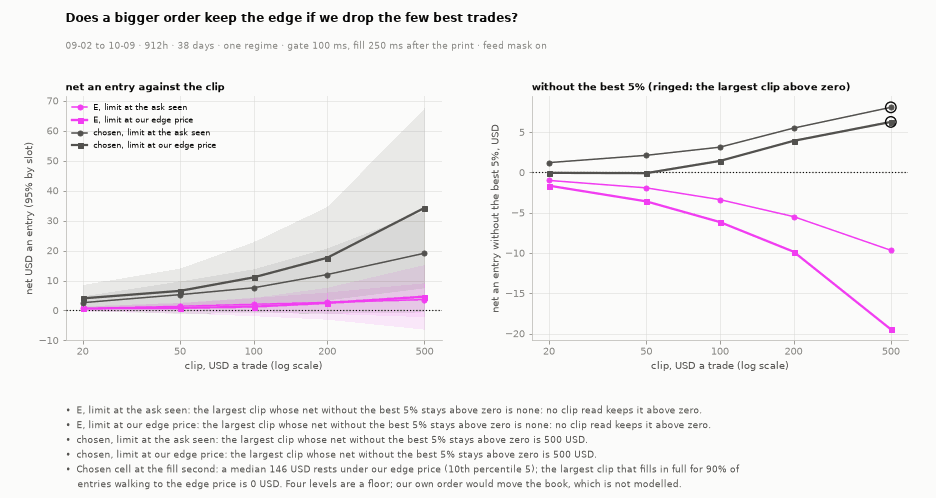

In [46]:
_notes = [f"{CURVES[k_][0].split(':')[0]}, limit at {'the ask seen' if k_[1] == 'ask' else 'our edge price'}: the largest clip whose net without the best 5% stays above zero is "
          + (f"{SURV[k_]:g} USD." if SURV[k_] else "none: no clip read keeps it above zero.") for k_ in CURVES]
_e = CAP_EST["cell"]["row"]
_notes.append(f"Chosen cell at the fill second: a median {_e['usd_edge_med']:,.0f} USD rests under our edge price (10th percentile {_e['usd_edge_p10']:,.0f}); "
              f"the largest clip that fills in full for 90% of entries walking to the edge price is {_e['full_clip']:g} USD. Four levels are a floor; our own order would move the book, which is not modelled.")
figstyle.show(ST.clip_fig(CURVES, WIN, _notes), "fig:s6-clip", FIGURES)

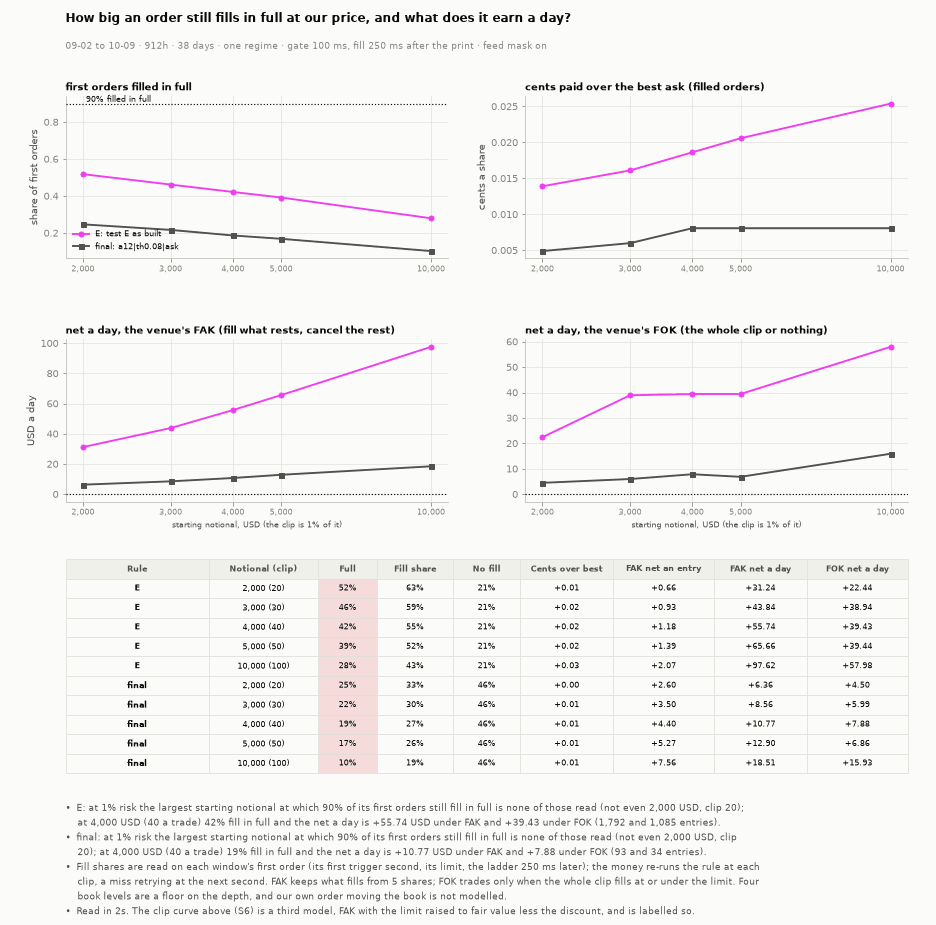

In [47]:
# ---- the sizing ladder at 1% of the starting notional a trade, under the venue's FAK (the engine's model) and FOK ----
_t = time.time()
LADDER = {"E": ("E: test E as built", ST.ladder_rows(CAND, TAB, CFG_E, len(DAYS))), "cell": (f"final: {CFG['name']}", ST.ladder_rows(CAND, TAB, CFG, len(DAYS)))}
_notes = []
for k_ in ("E", "cell"):
    t_, rr_ = LADDER[k_]
    ok_ = [r_ for r_ in rr_ if r_["full"] >= 0.9]
    big_ = max(ok_, key=lambda r_: r_["notional"]) if ok_ else None
    at4_ = next((r_ for r_ in rr_ if r_["notional"] == 4000.0), None)
    _notes.append(f"{t_.split(':')[0]}: at 1% risk the largest starting notional at which 90% of its first orders still fill in full is "
                  + (f"{big_['notional']:,.0f} USD (clip {big_['clip']:g})" if big_ else "none of those read (not even 2,000 USD, clip 20)")
                  + (f"; at 4,000 USD (40 a trade) {at4_['full']:.0%} fill in full and the net a day is {sgn(at4_['fak']['day'])} USD under FAK and {sgn(at4_['fok']['day'])} under FOK "
                     f"({at4_['fak']['n']:,} and {at4_['fok']['n']:,} entries)." if at4_ else "."))
_notes.append("Fill shares are read on each window's first order (its first trigger second, its limit, the ladder 250 ms later); the money re-runs the rule at each clip, a miss retrying at the next second. "
              "FAK keeps what fills from 5 shares; FOK trades only when the whole clip fills at or under the limit. Four book levels are a floor on the depth, and our own order moving the book is not modelled.")
_notes.append(f"Read in {time.time() - _t:.0f}s. The clip curve above (S6) is a third model, FAK with the limit raised to fair value less the discount, and is labelled so.")
figstyle.show(ST.ladder_fig(LADDER, WIN, _notes), "fig:s6-ladder", FIGURES)

In [48]:
# ---- the gates, as data, then the decision ----
def gate(i, sec, label, name, reading, verdict, would):
    GATES.append({"id": i, "section": sec, "label": label, "name": name, "reading": reading, "verdict": verdict if isinstance(verdict, str) else ("PASS" if verdict else "FAIL"), "would_change": would})
PF_ = lambda ok_: "PASS" if ok_ else "FAIL"
gate("G3", "S3", "Tuned beats E OOS", f"Does tuning beat the rule as built out of sample? Over the {len(OOS_DAYS)} traded days ({OOS_DAYS[0][5:]} to {OOS_DAYS[-1][5:]}), each week traded with the setting "
     "chosen on the weeks before it, E tuned's net an entry without the best 5% must be above E as built's (3 s) on the same days, and its 95% interval's low end above zero",
     f"E tuned {sgn(TS['per_ex_top5'], 3)} ({sgn(TS['per_ex_top5_lo'])} to {sgn(TS['per_ex_top5_hi'])}) against E as built {sgn(TS_E['per_ex_top5'], 3)}", G_WALK,
     "E as built ahead, or the interval reaching zero")
gate("G4", "S3", f"Same window {STABLE_MIN} of {len(NS_CHOSEN)} weeks", f"Is the pick the same week after week? The {len(NS_CHOSEN)} weekly picks, each made only on the weeks before its traded week, "
     f"must choose the same stale window at least {STABLE_MIN} times",
     f"chosen n {', '.join(str(n_) for n_ in NS_CHOSEN)} s; " + (f"{N_MODE} s in {N_MODE_COUNT} weeks" if N_MODE_COUNT > 1 else "no window twice"), G_STABLE, "a choice that jumps")
gate("G5", "S3", "OOS net above zero", "E tuned's walk-forward net an entry is above zero", f"{sgn(TS['per'], 3)} USD an entry (95% {sgn(TS['per_lo'])} to {sgn(TS['per_hi'])}) on {TS['n']:,}",
     bool(TS.get("n")) and TS["per"] > 0, "a net at or below zero")
gate("G6", "S3", "OOS ex-5% above zero", "E tuned's walk-forward net an entry stays above zero without its best 5% of entries", f"{sgn(TS['per_ex_top5'], 3)} USD an entry",
     bool(TS.get("n")) and TS["per_ex_top5"] > 0, "a few wins carrying the record")
gate("G7", "S4", "Beats random burst", f"E tuned's walk-forward record beats the same count of entries per day and coin at its weeks' seconds that pass every condition of each week's cell but the burst, one-sided p below {P_GATE:.2f}",
     f"p {P_REC_BURST:.4f} on {N_DRAWS:,} draws (null median {sgn(float(np.nanmedian(REC_BURST['per'])), 3)}, the record {sgn(TS['per'], 3)})", bool(np.isfinite(P_REC_BURST) and P_REC_BURST < P_GATE),
     f"a p of {P_GATE:.2f} or more")
_b = OOS2W_CELL[1:]
gate("G8", "S4", "Both OOS blocks pass", "both out-of-sample blocks of the final cell pass (at least 20 entries, above zero, inside the in-sample forecast); a consistency check, since it was chosen on every day",
     "; ".join(f"{b_['name']} {sgn(b_['s'].get('per', float('nan')), 3)} {b_['verdict']}" for b_ in _b), len(_b) >= 2 and all(b_["verdict"] == "PASS" for b_ in _b), "a block below zero or outside the forecast")
gate("G9", "S4", "Survives fee x2", "E tuned's walk-forward net an entry stays above zero at twice the fee", f"{sgn(WF_FEE2['per'], 3)} USD an entry", bool(WF_FEE2.get("n")) and WF_FEE2["per"] > 0,
     "an edge smaller than a fee")
gate("G10", "S4", "1 s delay keeps sign", "E tuned's walk-forward net an entry stays above zero with the order one second later (1,250 ms)", f"{sgn(WF_1S['per'], 3)} at 1,250 ms against {sgn(TS['per'], 3)} at 250 ms",
     bool(WF_1S.get("n")) and WF_1S["per"] > 0, "an edge that lives inside one second")
_dsr = DSR["dsr"] if DSR and np.isfinite(DSR["dsr"]) else float("nan")
gate("G11", "S4", "Deflated Sharpe", f"the walk-forward record's Sharpe an entry deflated over the {N_REGISTERED} registered cells is at least {DSR_MIN:.2f}", f"{_dsr:.2f}", bool(np.isfinite(_dsr) and _dsr >= DSR_MIN), "luck of the best of N")
gate("G12", "S4", "Climbs steadily", f"the lower end of the final cell's equity-line r-squared (95% over resampled days) is at least {R2_MIN:.2f} [U]", f"{R2['cell'][0]:.2f} ({R2['cell'][1]:.2f} to {R2['cell'][2]:.2f})",
     R2["cell"][1] >= R2_MIN, "a path carried by a few days")
gate("G13", "S3", "Plateau holds", "the final cell and its neighbours one step in window and discount to fair value are above zero without the best 5% on every seated day", f"{'every' if PLATEAU_OK else 'not every'} cell of the block above zero",
     PLATEAU_OK, "a spike in the grid")
gate("G14", "S5", "Drawdown inside limit", f"the final cell's deepest drawdown over every seated day stays under the pre-registered {DD_LIMIT_USD:.0f} USD [U]", f"{RISK['cell'][1]['max_dd']:.0f} USD",
     not RISK["cell"][1]["dd_crossed"], "a deeper drawdown")
gate("G15", "S3", f"Weeks agree {STABLE_MIN} of {len(WF['folds'])}", f"Does the week a pick is traded on agree with the weeks it was chosen from? At least {STABLE_MIN} of the "
     f"{len(WF['folds'])} traded weeks must net above zero without the best 5% and inside the pick's 95% interval on its choosing weeks",
     "; ".join(f"{WK(f_)} {'agrees' if f_['agree'] else 'collapses'}" for f_ in WF["folds"]), G_AGREE, "choosing weeks that fool us")
CORE = [g_["id"] for g_ in GATES]
GV_ = {g_["id"]: g_["verdict"] for g_ in GATES}
SIZED = all(GV_[i_] == "PASS" for i_ in CORE)
WORD = "1x" if SIZED else "NO SIZE"
CLASS = "A" if SIZED else ("B" if TS.get("n", 0) and TS["per"] > 0 else "C")
GATES.append({"id": "G16", "section": "S6", "label": "Sized only if passed", "name": "a size only when every gate G1 to G15 passed; else the rungs are information only",
              "reading": f"{'SIZED' if SIZED else 'NO SIZE'}: {', '.join(g_['label'] for g_ in GATES if g_['verdict'] != 'PASS') or 'none failed'}", "verdict": "PASS" if SIZED else "FAIL", "would_change": "any gate it reads"})
GATES.extend(GATES_E4)                                     # the price cap on E (S4.7): read beside the decision, not part of the final cell's sizing
_rungs = [(lab_, f_, r_) for (lab_, f_), (t_, rows_) in CURVES.items() if lab_ == "cell" for r_ in rows_]
display(Markdown(f"**Decision: {'a USD ' + format(CLIP_USD, 'g') + ' clip, one entry a window, paper only' if SIZED else 'NO SIZE, information only'}.** "
                 + ("Every gate passed." if SIZED else f"Not passed: {', '.join(g_['label'] for g_ in GATES if g_['verdict'] != 'PASS' and g_['id'] in CORE)}.")
                 + " The rungs of the final cell" + (":" if SIZED else " (information only):")))
display(HTML(pd.DataFrame([dict(limit=f_, clip=r_["clip"], entries_a_day=r_["per_day"], net_per_entry=r_["per"], net_ex_best5=r_["ex5"], net_a_day=r_["day_net"]) for lab_, f_, r_ in _rungs]).round(3).to_html(index=False, border=0)))

**Decision: NO SIZE, information only.** Not passed: Tuned beats E OOS, Both OOS blocks pass, Deflated Sharpe, Climbs steadily, Drawdown inside limit, Weeks agree 4 of 5. The rungs of the final cell (information only):

limit,clip,entries_a_day,net_per_entry,net_ex_best5,net_a_day
ask,20.0,2.447,2.598,1.226,6.358
ask,50.0,2.447,5.273,2.131,12.904
ask,100.0,2.447,7.564,3.145,18.511
ask,200.0,2.447,11.980,5.508,29.319
ask,500.0,2.447,19.103,8.088,46.751
edge,20.0,3.263,4.029,-0.045,13.147
edge,50.0,3.263,6.531,-0.080,21.311
edge,100.0,3.263,11.039,1.434,36.023
edge,200.0,3.263,17.577,3.924,57.356
edge,500.0,3.263,34.249,6.275,111.761


## S7 · Verdict - Does the thesis hold?

In [49]:
WORD_V = "MONEY" if SIZED else f"class {CLASS}"
_failed = [g_["label"] for g_ in GATES if g_["verdict"] != "PASS" and g_["id"] in CORE]
_why = [f"E tuned, each week chosen on the weeks before it, earned {sgn(TS['per'], 3)} USD an entry on {TS['n']:,} entries over {len(OOS_DAYS)} days (95% {sgn(TS['per_lo'])} to {sgn(TS['per_hi'])}), "
        f"{sgn(TS['per_ex_top5'], 3)} without the best 5% ({sgn(TS['per_ex_top5_lo'])} to {sgn(TS['per_ex_top5_hi'])}); E as built on the same days {sgn(TS_E['per'], 3)}, {sgn(TS_E['per_ex_top5'], 3)} without the best 5%",
        f"the weekly picks chose the stale window {', '.join(str(n_) for n_ in NS_CHOSEN)} s and {N_AGREE} of {len(WF['folds'])} traded weeks agreed with their choosing weeks; the final cell {CFG['name']}" + (" is E as built" if FINAL_IS_E else "") + f"; deflated Sharpe {_dsr:.2f} over {N_REGISTERED} cells; random burst p {P_REC_BURST:.4f}",
        f"E tuned at 1,250 ms {sgn(WF_1S['per'], 3)}, at twice the fee {sgn(WF_FEE2['per'], 3)}; not passed: {', '.join(_failed) or 'none'}"]
NEXT_BET = (f"the forward read of {CFG['name']} frozen as it stands, on the days from 10-10 as they seat, registered first, on this engine (the gate at t + {DECIDE_MS} ms, the feed mask), "
            "" + ("" if FINAL_IS_E else "beside it test E as built"))
VERDICT_MD = (f"**The answer: {WORD_V}.** " + ("Every gate passed." if SIZED else ("Real in sign out of sample, not sizeable. " if CLASS == "B" else "No money out of sample. "))
              + "\n\n" + "\n".join(f"- {w_[0].upper() + w_[1:]}." for w_ in _why) + f"\n\n**Next bet.** {NEXT_BET[0].upper() + NEXT_BET[1:]}."
              + f"\n\n**The engine.** The fair value starts from the venue's published price to beat, with the Binance price stream converted by the previous day's basis; the gate reads the book {DECIDE_MS} ms after the Binance print [U] "
              f"and the order meets the ladder {LAT_MS} ms after it; decisions on a slot-wide silent feed are refused (the feed mask, {float((~FEED_LIVE).mean()):.3%} of window-seconds). "
              "Our own latency is assumed, not measured.")
display(Markdown(VERDICT_MD))
for g_ in GATES:
    assert g_["verdict"] in REPORT.GATE_VERDICTS, g_
    assert len(g_["label"]) <= REPORT.MAX_GATE_LABEL, (g_["label"], len(g_["label"]))
assert len({g_["id"] for g_ in GATES}) == len(GATES)
GATES.sort(key=lambda g_: int(g_["id"][1:]))
GV = {g_["id"]: g_["verdict"] for g_ in GATES}
display(Markdown("**Gates**\n\n| Id | Section | Gate | Reading | Verdict |\n|---|---|---|---|---|\n" + "\n".join(f"| {g_['id']} | {g_['section']} | {g_['label']} | {g_['reading']} | **{g_['verdict']}** |" for g_ in GATES)))
RESULT_LINES = [f"RESULT {RUN_ID} final_cell={CFG['name']}", f"RESULT {RUN_ID} wf_chosen_n={'/'.join(str(n_) for n_ in NS_CHOSEN)}", f"RESULT {RUN_ID} wf_weeks_agree={N_AGREE}", f"RESULT {RUN_ID} wf_entries={TS['n']}",
                f"RESULT {RUN_ID} wf_net_per_entry_usd={TS['per']:.4f}", f"RESULT {RUN_ID} wf_net_ex_best5_usd={TS['per_ex_top5']:.4f}", f"RESULT {RUN_ID} wf_net_ex_best5_lo_usd={TS['per_ex_top5_lo']:.4f}",
                f"RESULT {RUN_ID} E_wf_net_ex_best5_usd={TS_E['per_ex_top5']:.4f}", f"RESULT {RUN_ID} E_wf_net_per_entry_usd={TS_E['per']:.4f}", f"RESULT {RUN_ID} deflated_sharpe={_dsr:.3f}",
                f"RESULT {RUN_ID} wf_p_random_burst={P_REC_BURST:.4f}", f"RESULT {RUN_ID} wf_delay1s_minus_base_usd={WF_1S['per'] - TS['per']:.4f}", f"RESULT {RUN_ID} wf_win_rate_pct={TS['win'] * 100:.2f}", f"RESULT {RUN_ID} wf_net_pnl_usd={TS['net']:.2f}",
                f"RESULT {RUN_ID} E_net_per_entry_usd={S_E['per']:.4f}", f"RESULT {RUN_ID} n_cells={N_REGISTERED}"]
print("\n".join(RESULT_LINES))

**The answer: class B.** Real in sign out of sample, not sizeable. 

- E tuned, each week chosen on the weeks before it, earned +2.926 USD an entry on 174 entries over 31 days (95% +0.26 to +5.98), +0.254 without the best 5% (-1.62 to +2.12); E as built on the same days +0.775, -0.968 without the best 5%.
- The weekly picks chose the stale window 6, 12, 12, 12, 12 s and 2 of 5 traded weeks agreed with their choosing weeks; the final cell a12|th0.08|ask; deflated Sharpe 0.00 over 162 cells; random burst p 0.0190.
- E tuned at 1,250 ms +0.888, at twice the fee +2.559; not passed: Tuned beats E OOS, Both OOS blocks pass, Deflated Sharpe, Climbs steadily, Drawdown inside limit, Weeks agree 4 of 5.

**Next bet.** The forward read of a12|th0.08|ask frozen as it stands, on the days from 10-10 as they seat, registered first, on this engine (the gate at t + 100 ms, the feed mask), beside it test E as built.

**The engine.** The fair value starts from the venue's published price to beat, with the Binance price stream converted by the previous day's basis; the gate reads the book 100 ms after the Binance print [U] and the order meets the ladder 250 ms after it; decisions on a slot-wide silent feed are refused (the feed mask, 0.230% of window-seconds). Our own latency is assumed, not measured.

**Gates**

| Id | Section | Gate | Reading | Verdict |
|---|---|---|---|---|
| G1 | S2 | Windows have a book | 94.2% of 14,592 windows | **PASS** |
| G2 | S2 | Live replay agrees | 1,803 entries, only-vectorised 0, only-live 0; planted differs: True | **PASS** |
| G3 | S3 | Tuned beats E OOS | E tuned +0.254 (-1.62 to +2.12) against E as built -0.968 | **FAIL** |
| G4 | S3 | Same window 4 of 5 weeks | chosen n 6, 12, 12, 12, 12 s; 12 s in 4 weeks | **PASS** |
| G5 | S3 | OOS net above zero | +2.926 USD an entry (95% +0.26 to +5.98) on 174 | **PASS** |
| G6 | S3 | OOS ex-5% above zero | +0.254 USD an entry | **PASS** |
| G7 | S4 | Beats random burst | p 0.0190 on 1,000 draws (null median +0.448, the record +2.926) | **PASS** |
| G8 | S4 | Both OOS blocks pass | out-of-sample +0.799 FAIL; out-of-sample 2 -4.631 thin | **FAIL** |
| G9 | S4 | Survives fee x2 | +2.559 USD an entry | **PASS** |
| G10 | S4 | 1 s delay keeps sign | +0.888 at 1,250 ms against +2.926 at 250 ms | **PASS** |
| G11 | S4 | Deflated Sharpe | 0.00 | **FAIL** |
| G12 | S4 | Climbs steadily | 0.43 (0.02 to 0.97) | **FAIL** |
| G13 | S3 | Plateau holds | every cell of the block above zero | **PASS** |
| G14 | S5 | Drawdown inside limit | 157 USD | **FAIL** |
| G15 | S3 | Weeks agree 4 of 5 | 09-09 to 09-15 agrees; 09-16 to 09-22 agrees; 09-23 to 09-29 collapses; 09-30 to 10-06 collapses; 10-07 to 10-09 collapses | **FAIL** |
| G16 | S6 | Sized only if passed | NO SIZE: Tuned beats E OOS, Both OOS blocks pass, Deflated Sharpe, Climbs steadily, Drawdown inside limit, Weeks agree 4 of 5 | **FAIL** |
| G17 | S4 | Cap 0.50: ex-5% clears 0 | -2.380 (-4.20 to -0.42) on 405 entries | **FAIL** |
| G18 | S4 | Cap 0.50: 4 of 6 weeks | 1 of 6 weeks | **FAIL** |

RESULT um-023 final_cell=a12|th0.08|ask
RESULT um-023 wf_chosen_n=6/12/12/12/12
RESULT um-023 wf_weeks_agree=2
RESULT um-023 wf_entries=174
RESULT um-023 wf_net_per_entry_usd=2.9263
RESULT um-023 wf_net_ex_best5_usd=0.2538
RESULT um-023 wf_net_ex_best5_lo_usd=-1.6196
RESULT um-023 E_wf_net_ex_best5_usd=-0.9682
RESULT um-023 E_wf_net_per_entry_usd=0.7750
RESULT um-023 deflated_sharpe=0.000
RESULT um-023 wf_p_random_burst=0.0190
RESULT um-023 wf_delay1s_minus_base_usd=-2.0382
RESULT um-023 wf_win_rate_pct=71.26
RESULT um-023 wf_net_pnl_usd=509.17
RESULT um-023 E_net_per_entry_usd=0.6624
RESULT um-023 n_cells=162


In [50]:
# ---- the card ----
_cut = lambda s, n: s if len(s) <= n else s[: n - 1].rstrip() + "."
mk = lambda metric, value, bar="", verdict="", gate=None: {"metric": metric, "value": value, "bar": bar, "verdict": GV[gate] if gate else verdict, **({"gate": gate} if gate else {})}
_ts_slots = np.unique(TAB.slot[np.isin(TAB.day, OOS_IDX)])
_sl = np.bincount(np.searchsorted(_ts_slots, ENT["slot"]), weights=ENT["net"], minlength=len(_ts_slots)) if TS.get("n") else np.zeros(1)
SLOT_SH = float(_sl.mean() / _sl.std(ddof=1) * np.sqrt(B.SLOTS_PER_DAY * 365)) if TS.get("n") and _sl.std(ddof=1) > 0 else float("nan")
_wins, _loss = ENT["net"][ENT["net"] > 0], ENT["net"][ENT["net"] <= 0]
PF = float(_wins.sum() / abs(_loss.sum())) if len(_loss) and _loss.sum() != 0 else None
WLR = float(_wins.mean() / abs(_loss.mean())) if len(_wins) and len(_loss) else None
_nd = len(OOS_DAYS)
_dly = ST.daily(ENT, len(DAYS))[OOS_IDX]
_eq = np.cumsum(ENT["net"])
_dd_t = float((np.maximum.accumulate(np.concatenate([[0.0], _eq]))[1:] - _eq).max()) if len(_eq) else 0.0
METRICS = {"ann_return_pct": None, "excess_vs_hurdle_pct": None, "ann_vol_pct": None, "sharpe": SLOT_SH if np.isfinite(SLOT_SH) else None, "sortino": None, "calmar": None,
           "psr": float(DSR["psr"]) if DSR and np.isfinite(DSR["psr"]) else None, "dsr": _dsr if np.isfinite(_dsr) else None,
           "max_dd_pct": -_dd_t / BOOK_USD * 100, "max_dd_days": float(_nd), "n_periods": float(_nd * 96), "periods_per_year": 96.0 * 365.0,
           "total_return_pct": TS["net"] / BOOK_USD * 100, "n_trades": float(TS["n"]), "trades_per_day": TS["n"] / _nd, "hit_rate_pct": TS["win"] * 100,
           "profit_factor": PF, "expectancy_bps": TS["per"] / CLIP_USD * 1e4, "win_loss_ratio": WLR, "avg_hold_h": float(np.mean(ENT["T"]) / 3600.0) if TS.get("n") else None,
           "exposure_pct": None, "turnover_ann": float(ENT["cost"].sum() / _nd * 365 / BOOK_USD),
           "fees_pct_of_gross": float(ENT["fee"].sum() / abs(ENT["gross"].sum()) * 100) if ENT["gross"].sum() else None, "worst_period_pct": float(_dly.min() / BOOK_USD * 100),
           "gross_edge_bps": TS["gross_per"] / CLIP_USD * 1e4, "cost_bps": TS["fee_per"] / CLIP_USD * 1e4, "breakeven_cost_bps": TS["gross_per"] / CLIP_USD * 1e4,
           "capacity_usd": float(SURV[("cell", "edge")]) if SURV[("cell", "edge")] else None, "beta_to_underlying": None}
NA = {"ann_return_pct": f"{_nd} out-of-sample days: an annualised return is not meaningful", "excess_vs_hurdle_pct": f"{_nd} out-of-sample days: not meaningful",
      "ann_vol_pct": f"{_nd} out-of-sample days: not meaningful", "sortino": "not meaningful on the out-of-sample days", "calmar": "not meaningful on the out-of-sample days",
      "exposure_pct": "exposure was not tracked per second", "beta_to_underlying": "a binary payoff: no single underlying beta"}
if METRICS["capacity_usd"] is None:
    NA["capacity_usd"] = "no clip keeps the net without the best 5% above zero under the edge-price limit"
for k_, v_ in list(METRICS.items()):
    if v_ is None or (isinstance(v_, float) and not math.isfinite(v_)):
        METRICS[k_] = None
        NA.setdefault(k_, "not computable on the out-of-sample days")
VERDICT = {"word": WORD, "why": [_cut(w_, 110) for w_ in _why], "next_bet": _cut(f"the forward read of {CFG['name']} frozen, from 10-10, registered first, on this engine (gate +{DECIDE_MS} ms, feed mask)", 150)}
CARD = {
    "question": _cut("Does buying after a burst, while the book has not moved, still make money on weeks it was not tuned on?", 200),
    "answer": _cut(f"{WORD}, class {CLASS}. E tuned out of sample: {TS['n']} entries net {sgn(TS['net'], 0)} USD ({sgn(TS['per'])} each, 95% {sgn(TS['per_lo'])} to {sgn(TS['per_hi'])}); without the best 5% {sgn(TS['per_ex_top5'])}.", 220),
    "implementation": [("Trade", "Buy the near token after a burst, book not moved"), ("Venue", "Polymarket 15m crypto Up/Down; Binance is input"), ("Rule", _cut(CFG["name"], 70)),
                       ("Size", f"USD {CLIP_USD:g} a trade, USD {BOOK_USD:,.0f} book, 1x"), ("Costs", "taker fee 0.07 x p(1-p); gate +100, fill +250 ms"), ("Window", f"{DAYS[0][5:]} to {DAYS[-1][5:]}, {24 * len(DAYS)}h, 1 regime")],
    "big": [dict(mk("Net per entry", f"{sgn(TS['per'])} USD", f"95% {sgn(TS['per_lo'])} to {sgn(TS['per_hi'])}", gate="G5"), scope="test"),
            dict(mk("Without best 5%", f"{sgn(TS['per_ex_top5'])} USD", "above 0", gate="G6"), scope="test"),
            dict(mk("Win rate", pct(TS["win"]), f"needed {pct(TS['win_needed'])}", verdict="INFO"), scope="test"),
            dict(mk("Deflated Sharpe", f"{_dsr:.2f}", f"at least {DSR_MIN:.2f}", gate="G11"), scope="test")],
    "blocks": [
        {"title": "Money", "rows": [mk("Net per entry", f"{sgn(TS['per'])} USD", "above 0", gate="G5"), mk("Before costs, per entry", f"{sgn(TS['gross_per'])} USD", "", "INFO"),
                                    mk("Fee, per entry", f"{TS['fee_per']:.2f} USD", "", "INFO"), mk("E as built, same days", f"{sgn(TS_E['per'])} USD", "", "INFO")]},
        {"title": "Is it real", "rows": [mk("Tuned beats E", "yes" if G_WALK else "no", "yes", gate="G3"), mk("Same window", f"{N_MODE_COUNT} of {len(NS_CHOSEN)}", f"{STABLE_MIN} of {len(NS_CHOSEN)}", gate="G4"), mk("Weeks agree", f"{N_AGREE} of {len(WF['folds'])}", f"{STABLE_MIN} of {len(WF['folds'])}", gate="G15"),
                                       mk("Out-of-sample blocks", "both pass" if GV["G8"] == "PASS" else "not both", "both", gate="G8"), mk("Plateau", "holds" if PLATEAU_OK else "breaks", "holds", gate="G13"),
                                       mk("Random burst p", f"{P_REC_BURST:.4f}", f"below {P_GATE:.2f}", gate="G7")]},
        {"title": "Delay and cost", "rows": [mk("1,250 ms, per entry", sgn(WF_1S["per"]), "above 0", gate="G10"), mk("Fee x2, per entry", sgn(WF_FEE2["per"]), "above 0", gate="G9")]},
        {"title": "Risk, USD", "rows": [mk("Deepest drawdown", sgn(-RISK["cell"][1]["max_dd"], 0), f"limit -{DD_LIMIT_USD:.0f}", gate="G14"), mk("Worst day", sgn(RISK["cell"][1]["worst_day"], 0), "", "INFO"),
                                       mk("Steadiness r2", f"{R2['cell'][0]:.2f}", f"low end {R2_MIN:.2f}", gate="G12")]},
        {"title": "Checks", "rows": [mk("Windows with a book", pct(SHARE, 0), "90% bar", gate="G1"), mk("Live replay", "agrees" if GV["G2"] == "PASS" else "differs", "agrees", gate="G2"),
                                     mk("Cells tried", f"{N_REGISTERED}", "", "INFO"), mk("Checks held", f"{VERIFY_PASSED} of {VERIFY_TOTAL}", "all", "INFO")]}],
    "sizes": {"cols": ["Size", "Net, USD", "Per entry", "Verdict"], "chosen": 0 if SIZED else None,
              "rows": [["1x" if SIZED else "1x info only", sgn(TS["net"], 0), sgn(TS["per"], 2), "PASS" if SIZED else "FAIL"]]},
    "footer": [_cut(f"{N_REGISTERED} cells, each week chosen on the weeks before it.", 160),
               _cut(f"E was first read on all {len(DAYS)} days; only the walk-forward record is out of sample for a choice.", 160),
               _cut(f"{24 * len(DAYS)}h, {VERIFY_PASSED}/{VERIFY_TOTAL} checks; gate {DECIDE_MS} ms and fill {LAT_MS} ms after the print; slot-wide silent feeds refused.", 160)]}
_probs = REPORT.card_problems(CARD, metrics={k_: (None if v_ is None else float(v_)) for k_, v_ in METRICS.items()}, gates={g_["id"]: g_ for g_ in GATES}, word=WORD, carry=False)
assert not _probs, _probs

In [51]:
# ---- the study manifest fund.study/1 (the last cell of S7) ----
from fundplat.data import derived
TITLE = "Does buying right after a Binance burst, while the book has not moved, still make money on weeks it was not tuned on?"
QUESTION = "Does test E, tuned each week on the weeks before it over 162 settings (window, definition, discount to fair value, limit), beat test E as built on new weeks without its best 5%?"
RUN_AT = dt.datetime.now(dt.timezone.utc).strftime("%Y-%m-%dT%H:%MZ")
_ms = lambda d: int(dt.datetime.strptime(d, "%Y-%m-%d").replace(tzinfo=dt.timezone.utc).timestamp() * 1000)
_series, _unpinned = [], []
for ms_ in LAT_SEATED:
    for d in DAYS:
        m_ = derived.meta("tf15-table", RUNNER.key_of(d, ms_, DECIDE_MS, REF))
        _series.append(dict(spec=f"tf15:{d}:decision-table:{ms_}ms-gate{DECIDE_MS}ms", pin=m_["hash"], rows=int(COV.set_index("day").loc[d, "with_book"]), first_ts=_ms(d), last_ts=_ms(d) + 86_399_999,
                            handle=None, cls="pin", trunc=False))
INPUTS = {"digest": REPORT.inputs_digest([s_["pin"] for s_ in _series]), "series": _series, "unpinned": _unpinned}
WINDOW = {"from": f"{DAYS[0]}T00:00Z", "to": f"{(dt.date.fromisoformat(DAYS[-1]) + dt.timedelta(days=1)).isoformat()}T00:00Z", "hours": 24 * len(DAYS), "regimes": 1}
STUDY_VERIFY = {"suite": "tf15 engine, study and live checks", "passed": int(VERIFY_PASSED), "total": int(VERIFY_TOTAL), "books": int(TAB.W)}
CAVEATS = [f"{len(OOS_DAYS)} out-of-sample days of one regime: one observation, not a promise",
           f"E was first read on all {len(DAYS)} days: only the walk-forward record is out of sample for a choice",
           f"{N_REGISTERED} cells tried on each fold's choosing weeks: the deflated Sharpe prices the choice",
           "the final cell is chosen on every seated day: its own numbers there are in-sample",
           "the gate at t + 100 ms and the fill at t + 250 ms rest on an assumed 100 ms of our own, not a measurement",
           "the feed mask refuses slot-wide silences only; one quiet book beside live ones still trades",
           "the random-burst null buys at the ask seen; an edge-limit cell fills a little more than its null"]
assert all(len(c_) <= 110 for c_ in CAVEATS), [len(c_) for c_ in CAVEATS]
HEADLINE = {"metric": "net PnL per entry, USD, walk-forward out-of-sample days, E tuned", "label": "Net per entry", "value": float(TS["per"]), "unit": "usd", "hurdle": 0.0, "gate": "G5"}
COMPONENTS = [{"name": "PnL before costs", "usd": float(ENT["gross"].sum())}, {"name": "fees", "usd": -float(ENT["fee"].sum())}]
assert abs(sum(c_["usd"] for c_ in COMPONENTS) - TS["net"]) < 0.01
FIG_KINDS = {"fig:s3-e-equity": "equity-curve", "fig:s3-e-tradepnl": "equity-curve", "fig:s3-e-coins": "equity-curve", "fig:s3-e-entrypx": "trade-anatomy",
             "fig:s3-e-winloss": "win-loss-distribution", "fig:s3-e-bigwin": "trade-anatomy", "fig:s3-e-bigloss": "trade-anatomy",
             "fig:s3-surface": "parameter-surface", "fig:s3-walk": "out-of-sample-test", "fig:s3-stable": "parameter-surface", "fig:s3-final": "signal-decay",
             "fig:s4-e-oos2w": "out-of-sample-test", "fig:s4-e-oosfolds": "out-of-sample-test", "fig:s4-e-random": "significance-test",
             "fig:s4-cell-oos2w": "out-of-sample-test", "fig:s4-cell-oosfolds": "out-of-sample-test", "fig:s4-cell-random": "significance-test",
             "fig:s3-paths": "equity-curve", "fig:s4-weekly-ex5": "out-of-sample-test", "fig:s4-latency": "signal-decay", "fig:s4-delay-paths": "equity-curve", "fig:s4-costs": "cost-sensitivity", "fig:s4-fee-paths": "equity-curve", "fig:s4-slices": "edge-by-slice", "fig:s4-steady": "steadiness",
             "fig:s4-exits": "exit-reason-breakdown", "fig:s4-gates-paths": "equity-curve", "fig:s4-gates-weekly": "out-of-sample-test",
             "fig:s4-gates-oos2w": "out-of-sample-test", "fig:s4-gates-folds": "out-of-sample-test", "fig:s4-gates-random": "significance-test", "fig:s5-risk": "drawdown-and-tail", "fig:s6-clip": "capacity-curve", "fig:s6-ladder": "capacity-curve"}
assert {f_["id"] for f_ in FIGURES} == set(FIG_KINDS), set(FIG_KINDS) ^ {f_["id"] for f_ in FIGURES}
for f_ in FIGURES:
    f_["kind"] = FIG_KINDS[f_["id"]]
_eqp = [(dt.datetime.fromtimestamp(int(s_) * 900, dt.timezone.utc) + dt.timedelta(minutes=15), float(BOOK_USD + v_)) for s_, v_ in zip(ENT["slot"], _eq)] or [(dt.datetime.fromtimestamp(_ms(OOS_DAYS[0]) / 1000, dt.timezone.utc), BOOK_USD)]
STUDY = REPORT.build_manifest(
    id=STUDY_ID, kind="strategy", desk=DESK, title=TITLE, question=QUESTION, status="registered", run={"executed": RUN_AT, "kernel": "ccvenv"}, inputs=INPUTS, window=WINDOW,
    verify=STUDY_VERIFY, gates=[{k_: g_[k_] for k_ in ("id", "section", "name", "label", "reading", "verdict", "would_change")} for g_ in GATES], figures=FIGURES, verdict=VERDICT, caveats=CAVEATS,
    headline=HEADLINE, components=COMPONENTS, summary=CARD, format="directional", style="systematic", metrics=METRICS, na=NA,
    strategy={"name": "Buy the near token a burst left under fair value while the book has not moved, 15m Up/Down", "thesis": "a Binance burst persists and a Polymarket book that has not moved since has not re-priced it",
              "market": "prediction markets", "instruments": ["BTC", "ETH", "SOL", "XRP"], "venues": ["Polymarket", "Binance (input)"], "style": "momentum"},
    rules={"entry": _cut(CFG["name"], 60), "exit": "hold to the outcome", "sizing": f"USD {CLIP_USD:g} a trade", "rebalance": None, "hedge": None, "hold": "to expiry",
           "stop": f"a day's loss of USD {STOP_DAY_USD:.0f} stops the day [U]", "cost": "taker fee 0.07 x p(1-p); gate +100 ms, fill +250 ms"},
    params={"clip": {"value": CLIP_USD, "unit": "usd", "source": "[U]"}, "latency_ms": {"value": float(LAT_MS), "unit": "ms", "source": "[U]"},
            "venue_hold_ms": {"value": float(VENUE_HOLD_MS), "unit": "ms", "source": "[1]"}, "own_latency_ms": {"value": float(OWN_MS), "unit": "ms", "source": "[U]"}, "decide_ms": {"value": float(DECIDE_MS), "unit": "ms", "source": "[U]"},
            "feed_age_max_s": {"value": float(C.AGE_MAX_S), "unit": "s", "source": "[U]"},
            "fee_rate": {"value": float(COSTS["cell"][1]["rates"][0]) if len(COSTS["cell"][1]["rates"]) == 1 else 0.07, "unit": "rate", "source": "[API]"},
            "stop_day_usd": {"value": STOP_DAY_USD, "unit": "usd", "source": "[U]"}, "dd_limit_usd": {"value": DD_LIMIT_USD, "unit": "usd", "source": "[U]"}},
    equity=_eqp, profile={"market": "predmkts", "markets": ["predmkts", "crypto"], "venues": ["polymarket", "binance"], "instruments": ["BTC, ETH, SOL, XRP 15m Up/Down", "spot aggTrades"], "bar": "15m"}, book=None)
S0_HANDLE.update(Markdown(REPORT.summary_md(STUDY)))
display(REPORT.display_bundle(STUDY), raw=True)

study manifest fund.study/1: 18 gates, 34 figures, verdict NO SIZE

## A · Appendix

The final cell's entries (the first forty rows) and the twenty best cells of the grid by the plateau rule's smoothed score on every seated day.

In [52]:
display(Markdown(f"**The final cell `{CFG['name']}`, every entry on every seated day in time order**"))
display(HTML(trades_df(CELL_ALL, np.arange(len(CELL_ALL["net"]))).round(3).to_html(index=False, border=0, max_rows=40)))
_rk = pd.DataFrame([dict(cell=r_["cfg"]["name"], smoothed_all_days=r_["smoothed"], qualifies=r_["eligible"]) for r_ in FINAL_RANK])
_top = SURF_DF.merge(_rk, on="cell").sort_values("smoothed_all_days", ascending=False).head(20)
display(Markdown("**The twenty best cells by the plateau rule's smoothed score on every seated day** (in-sample: a description of the final choice)"))
display(HTML(_top.round(3).to_html(index=False, border=0)))

**The final cell `a12|th0.08|ask`, every entry on every seated day in time order**

day,coin,near,second,seconds_left,price_paid,shares,cost,fee,won,net
2026-09-02,btc,Down,22,878,0.510,39.21,19.997,0.686,True,18.527
2026-09-02,eth,Down,31,869,0.700,5.79,4.053,0.085,True,1.652
2026-09-02,sol,Up,42,858,0.290,5.00,1.450,0.072,False,-1.522
2026-09-04,eth,Down,518,382,0.170,22.00,3.740,0.217,True,18.043
2026-09-04,btc,Down,511,389,0.610,32.78,19.996,0.546,True,12.238
2026-09-05,sol,Down,138,762,0.800,12.00,9.600,0.134,False,-9.734
2026-09-05,btc,Down,570,330,0.490,40.81,19.997,0.714,True,20.099
2026-09-05,eth,Down,40,860,0.510,5.08,2.591,0.089,True,2.400
2026-09-05,btc,Down,330,570,0.600,33.33,19.998,0.560,True,12.772
2026-09-05,btc,Down,64,836,0.640,20.00,12.800,0.323,True,6.877


**The twenty best cells by the plateau rule's smoothed score on every seated day** (in-sample: a description of the final choice)

cell,definition,n_s,theta,limit,entries,per,ex5,ex5_lo,ex5_hi,smoothed_all_days,qualifies
c10|th0.08|edge,c,10,0.08,edge,12,11.187,4.099,-3.543,22.646,4.731,False
c12|th0.05|edge,c,12,0.05,edge,10,12.961,4.495,-4.436,26.113,4.345,False
c12|th0.08|edge,c,12,0.08,edge,10,12.855,4.377,-4.798,26.033,4.238,False
c8|th0.08|edge,c,8,0.08,edge,19,10.111,5.719,-1.045,17.160,3.988,False
c12|th0.03|edge,c,12,0.03,edge,13,10.131,3.545,-3.808,20.393,3.408,False
c10|th0.08|ask,c,10,0.08,ask,11,4.980,2.986,-2.324,8.681,3.059,False
c6|th0.08|edge,c,6,0.08,edge,36,6.438,2.146,-1.924,9.216,3.038,False
c8|th0.08|ask,c,8,0.08,ask,17,4.441,3.162,-0.008,6.719,3.035,False
c12|th0.08|ask,c,12,0.08,ask,10,5.218,3.030,-2.656,9.261,3.008,False
c12|th0.05|ask,c,12,0.05,ask,10,5.218,3.030,-2.656,9.261,3.008,False


## Research summary

In [53]:
assert [g1_["verdict"] for g1_ in STUDY["gates"]] == [g1_["verdict"] for g1_ in GATES] and STUDY["verdict"]["word"] == WORD and len(STUDY["figures"]) == len(FIGURES)
display(Markdown(VERDICT_MD))
display(HTML(summary_card.render(CARD, carry=False)))

**The answer: class B.** Real in sign out of sample, not sizeable. 

- E tuned, each week chosen on the weeks before it, earned +2.926 USD an entry on 174 entries over 31 days (95% +0.26 to +5.98), +0.254 without the best 5% (-1.62 to +2.12); E as built on the same days +0.775, -0.968 without the best 5%.
- The weekly picks chose the stale window 6, 12, 12, 12, 12 s and 2 of 5 traded weeks agreed with their choosing weeks; the final cell a12|th0.08|ask; deflated Sharpe 0.00 over 162 cells; random burst p 0.0190.
- E tuned at 1,250 ms +0.888, at twice the fee +2.559; not passed: Tuned beats E OOS, Both OOS blocks pass, Deflated Sharpe, Climbs steadily, Drawdown inside limit, Weeks agree 4 of 5.

**Next bet.** The forward read of a12|th0.08|ask frozen as it stands, on the days from 10-10 as they seat, registered first, on this engine (the gate at t + 100 ms, the feed mask), beside it test E as built.

**The engine.** The fair value starts from the venue's published price to beat, with the Binance price stream converted by the previous day's basis; the gate reads the book 100 ms after the Binance print [U] and the order meets the ladder 250 ms after it; decisions on a slot-wide silent feed are refused (the feed mask, 0.230% of window-seconds). Our own latency is assumed, not measured.

Size,"Net, USD",Per entry,Verdict
1x info only,+509,+2.93,FAIL
